In [1]:
import pandas as pd

df = pd.read_excel('GP DATA 2018 TO 2025.xlsx')

print("Number of rows", df.shape[0])
print("Number of Columns", df.shape[1])
print(df.columns.tolist())

# looking at Data types
print("\nData types:")
print(df.dtypes)

#Formatting the date and doig light analysis of the dates
dates = pd.to_datetime(df["ACCIDENT_DATE"], errors="coerce")
print("\nEarliest accident date:", dates.min())
print("Latest accident date:", dates.max())
print("\nYears represented:")
print(sorted(dates.dropna().dt.year.unique()))

#looking at number of unique values for each row
print("\nUnique values per column:")
print(df.nunique())

#looking at the datsetat a glance
df.head()

Number of rows 17426
Number of Columns 32
['PROV', 'DISTRICT', 'POLICE_STATION', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'CRASH_TYPE_DESC', 'TOTAL_VEHICLE_INVOLVED', 'ROAD_NAME_NUMBER', 'PASSENGER', 'PEDESTRIAN', 'DRIVER', 'CYCLIST', 'UNKNOWN', 'BLACK', 'WHITE', 'ASIAN', 'COLOURED', 'OTHER', 'FOREIGNER', 'MALE', 'FEMALE', 'UNKNOWN_1', 'VEH1', 'VEH2', 'VEH3', 'VEH4', 'VEH5', 'VEH6', 'VEH7', 'VEH8', 'VEH9', 'VEH10']

Data types:
PROV                       object
DISTRICT                   object
POLICE_STATION             object
ACCIDENT_DATE              object
ACCIDENT_TIME              object
CRASH_TYPE_DESC            object
TOTAL_VEHICLE_INVOLVED      int64
ROAD_NAME_NUMBER           object
PASSENGER                 float64
PEDESTRIAN                float64
DRIVER                    float64
CYCLIST                   float64
UNKNOWN                   float64
BLACK                     float64
WHITE                     float64
ASIAN                     float64
COLOURED                  float

C:\Users\xikon\AppData\Local\Temp\ipykernel_28496\575818326.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(df["ACCIDENT_DATE"], errors="coerce")



Earliest accident date: 2018-01-01 00:00:00
Latest accident date: 2025-12-31 00:00:00

Years represented:
[np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

Unique values per column:
PROV                         1
DISTRICT                     5
POLICE_STATION             146
ACCIDENT_DATE             2863
ACCIDENT_TIME             1322
CRASH_TYPE_DESC             22
TOTAL_VEHICLE_INVOLVED      13
ROAD_NAME_NUMBER          4957
PASSENGER                   13
PEDESTRIAN                   4
DRIVER                       3
CYCLIST                      2
UNKNOWN                      0
BLACK                       15
WHITE                        5
ASIAN                        3
COLOURED                     4
OTHER                        6
FOREIGNER                    5
MALE                         8
FEMALE                       8
UNKNOWN_1                    6
VEH1                        19
VEH2                    

,PROV,DISTRICT,POLICE_STATION,ACCIDENT_DATE,ACCIDENT_TIME,CRASH_TYPE_DESC,TOTAL_VEHICLE_INVOLVED,ROAD_NAME_NUMBER,PASSENGER,PEDESTRIAN,...,VEH1,VEH2,VEH3,VEH4,VEH5,VEH6,VEH7,VEH8,VEH9,VEH10
0,GP,Ekurhuleni,ACTONVILLE,01/FEB/21,08:00,Accident with fixed/other object,1,LANCASTER ROAD,NaN,NaN,...,Motor Car or Station Wagon,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GP,Ekurhuleni,ACTONVILLE,02/AUG/21,17:05,Hit and Run,1,TAMBO ROAD,NaN,1.0,...,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GP,Ekurhuleni,ACTONVILLE,03/JAN/18,20:45,Accident with pedestrian,1,CO DUBE,NaN,1.0,...,Motor Car or Station Wagon,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GP,Ekurhuleni,ACTONVILLE,05/OCT/21,19:23,Sideswipe (opposite directions),2,VAN DYK ROAD,NaN,NaN,...,Motor Car or Station Wagon,Motorcycle above > 125cc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,GP,Ekurhuleni,ACTONVILLE,06/MAY/22,20:00,Hit and Run,1,SINGH STREET,NaN,1.0,...,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
#the more important columns
core_cols = df.columns[0:13]

#checking how much missing data there is
core_audit = pd.DataFrame({
    "Missing": df[core_cols].isna().sum(),
    "Non_Missing": df[core_cols].notna().sum(),
    "Missing_%": (df[core_cols].isna().mean()*100).round(2),
    "Unique": df[core_cols].nunique()
})

print(core_audit)

                        Missing  Non_Missing  Missing_%  Unique
PROV                          0        17426       0.00       1
DISTRICT                      0        17426       0.00       5
POLICE_STATION                0        17426       0.00     146
ACCIDENT_DATE                 0        17426       0.00    2863
ACCIDENT_TIME                 0        17426       0.00    1322
CRASH_TYPE_DESC               0        17426       0.00      22
TOTAL_VEHICLE_INVOLVED        0        17426       0.00      13
ROAD_NAME_NUMBER            309        17117       1.77    4957
PASSENGER                 14655         2771      84.10      13
PEDESTRIAN                 7591         9835      43.56       4
DRIVER                    12324         5102      70.72       3
CYCLIST                   16999          427      97.55       2
UNKNOWN                   17426            0     100.00       0


In [3]:
# Columns 9–13: fatality-related fields
fatality_cols = df.columns[8:13]

for col in fatality_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())
    
#checking for the crashes that have fatalities and the categories of fatalitiy victims
print("\nRows with at least one recorded fatality-category value:")

print( df[fatality_cols].notna().any(axis=1).value_counts())


PASSENGER
PASSENGER
1.0      2234
2.0       361
3.0       104
4.0        44
5.0        13
6.0         4
7.0         3
8.0         2
9.0         1
10.0        1
12.0        1
13.0        2
16.0        1
NaN     14655
Name: count, dtype: int64

PEDESTRIAN
PEDESTRIAN
1.0    9680
2.0     142
3.0      10
4.0       3
NaN    7591
Name: count, dtype: int64

DRIVER
DRIVER
1.0     4970
2.0      130
3.0        2
NaN    12324
Name: count, dtype: int64

CYCLIST
CYCLIST
1.0      425
2.0        2
NaN    16999
Name: count, dtype: int64

UNKNOWN
UNKNOWN
NaN    17426
Name: count, dtype: int64

Rows with at least one recorded fatality-category value:
True     17409
False       17
Name: count, dtype: int64


There are 17 490 fatalities in total from 2018 to 2025
and there are only 17 with no recorded fatalitiy category value

In [4]:
# Finding the 17 records with no value in any fatality category and checkinh the records
no_fatality_info = df[fatality_cols].isna().all(axis=1)

print("Number of records:", no_fatality_info.sum())

print("\nRelevant information from those records:")
print(df.loc[no_fatality_info,df.columns[0:13]].to_string(index=False)
)

Number of records: 17

Relevant information from those records:
PROV             DISTRICT POLICE_STATION ACCIDENT_DATE ACCIDENT_TIME                  CRASH_TYPE_DESC  TOTAL_VEHICLE_INVOLVED     ROAD_NAME_NUMBER  PASSENGER  PEDESTRIAN  DRIVER  CYCLIST  UNKNOWN
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1                  NaN        NaN         NaN     NaN      NaN      NaN
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENIGING ROAD        NaN         NaN     NaN      NaN      NaN
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENEGING ROAD        NaN         NaN     NaN      NaN      NaN
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENIGING ROAD      

Since there is no column for total fatalities and it is the target variable, driver, passenger, pedestrian, cyclist and unknown will be aadded to make up the new variable.

In [5]:
df["TOTAL_FATALITIES"] = (
    df.iloc[:, 8:13]
      .fillna(0)
      .sum(axis=1)
)

print(df["TOTAL_FATALITIES"].describe())
print("\nFrequency of total fatalities:")
print(df["TOTAL_FATALITIES"].value_counts().sort_index())

#finding the rows with zero toal fatalities to check if the calculations worked
print("\nRows with zero fatalities:")
print((df["TOTAL_FATALITIES"] == 0).sum())

count    17426.000000
mean         1.108344
std          0.502701
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         16.000000
Name: TOTAL_FATALITIES, dtype: float64

Frequency of total fatalities:
TOTAL_FATALITIES
0.0        17
1.0     16134
2.0       924
3.0       213
4.0        81
5.0        27
6.0        17
7.0         5
8.0         1
9.0         1
10.0        1
12.0        1
13.0        1
14.0        1
15.0        1
16.0        1
Name: count, dtype: int64

Rows with zero fatalities:
17


Checking whether those 17 records have anything distinctive about them.

In [6]:
zero_fatality_records = df[df["TOTAL_FATALITIES"]==0]

print(zero_fatality_records.iloc[:, 0:8].to_string(index=False))

print("\nCrash types:")
print(zero_fatality_records["CRASH_TYPE_DESC"].value_counts())

print("\nTotal vehicles involved:")
print(zero_fatality_records["TOTAL_VEHICLE_INVOLVED"].value_counts())

print("\nDates:")
print(zero_fatality_records["ACCIDENT_DATE"].to_string(index=False))

PROV             DISTRICT POLICE_STATION ACCIDENT_DATE ACCIDENT_TIME                  CRASH_TYPE_DESC  TOTAL_VEHICLE_INVOLVED     ROAD_NAME_NUMBER
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1                  NaN
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENIGING ROAD
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENEGING ROAD
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENIGING ROAD
  GP           Ekurhuleni   BRACKENDOWNS     24/APR/18         18:10         Accident with pedestrian                       1 OLD VEREENEGING ROAD
  GP City of Johannesburg    DOUGLASDALE     01/JAN/19         07:30                      Hit and Run                 

Now Validaing Record Structure And Validating Duplicates. It is important to do this because there may be some duplicates or repeated combinations.  Repeated combinations of date, time and location may represent
multiple records associated with the same crash rather than independent
crashes.

In [7]:
# Identifying repeated crash charactersitics
#Create a temporary combination of variables that can help identify records occurring at the same time and location.
# This does NOT mean that records with the same values are duplicates. 
# It is only an initial diagnostic.

record_check = (df.groupby(["ACCIDENT_DATE", "ACCIDENT_TIME", "POLICE_STATION"]).size().reset_index(name="RECORD_COUNT"))

#Keep combinations that occur more than once.
repeated_records = record_check[record_check["RECORD_COUNT"]>1]

print("Number of repeated date-time-police station combinations:",len(repeated_records))

print("\nTop repeated combinations:")

print(repeated_records.sort_values("RECORD_COUNT", ascending=False).head(20).to_string(index=False))

Number of repeated date-time-police station combinations: 33

Top repeated combinations:
ACCIDENT_DATE ACCIDENT_TIME   POLICE_STATION  RECORD_COUNT
    11/MAY/18         00:15         HILLBROW             7
    24/APR/18         18:10     BRACKENDOWNS             5
    03/SEP/18         09:03      JHB CENTRAL             3
    30/MAY/21         01:30       BEKKERSDAL             2
    29/NOV/25         19:00       ZONKIZIZWE             2
    29/JAN/23         17:45 BRONKHORSTSPRUIT             2
    28/NOV/21         15:00            TEMBA             2
    28/APR/19         11:20      VEREENIGING             2
    18/JUN/21         16:40      MEADOWLANDS             2
    27/OCT/19         01:40            TEMBA             2
    25/MAY/19         21:50      GARSFONTEIN             2
    25/APR/22         06:00        SILVERTON             2
    24/AUG/19         21:30     ORANGE FARMS             2
    30/SEP/18         04:30          DE DEUR             2
    23/AUG/20         03:0

In [8]:
#Examining records that have no Road traffic fatalities
zero_fatality_records = df[df["TOTAL_FATALITIES"] == 0].copy()

print("Number of zero-fatality records:",len(zero_fatality_records))

print("\nZero-fatality records:")

print(
    zero_fatality_records[
        [
            "ACCIDENT_DATE",
            "ACCIDENT_TIME",
            "POLICE_STATION",
            "CRASH_TYPE_DESC",
            "TOTAL_VEHICLE_INVOLVED",
            "ROAD_NAME_NUMBER"
        ]
    ].to_string(index=False)
)

Number of zero-fatality records: 17

Zero-fatality records:
ACCIDENT_DATE ACCIDENT_TIME POLICE_STATION                  CRASH_TYPE_DESC  TOTAL_VEHICLE_INVOLVED     ROAD_NAME_NUMBER
    24/APR/18         18:10   BRACKENDOWNS         Accident with pedestrian                       1                  NaN
    24/APR/18         18:10   BRACKENDOWNS         Accident with pedestrian                       1 OLD VEREENIGING ROAD
    24/APR/18         18:10   BRACKENDOWNS         Accident with pedestrian                       1 OLD VEREENEGING ROAD
    24/APR/18         18:10   BRACKENDOWNS         Accident with pedestrian                       1 OLD VEREENIGING ROAD
    24/APR/18         18:10   BRACKENDOWNS         Accident with pedestrian                       1 OLD VEREENEGING ROAD
    01/JAN/19         07:30    DOUGLASDALE                      Hit and Run                       1       DOUGLAS STREET
    11/MAY/18         00:15       HILLBROW                      Hit and Run                  

In [9]:
#checking whether complete rows are duplicated.
exact_duplicates = df.duplicated(keep=False)

print("Number of records involved in exact duplicates:",exact_duplicates.sum())
print("Number of unique duplicated rows:",df[exact_duplicates].drop_duplicates().shape[0])

Number of records involved in exact duplicates: 15
Number of unique duplicated rows: 7


Repeated date, time and location combinations were identified during
the initial data audit. These repeated records are examined further
to determine whether they represent exact duplicats or many
records with different recorded attributes.

No observations are removed at this stage.

In [10]:
# Variables used to identify records with the same
# date, time, police station, crash type and vehicle count.

group_cols = [
    "ACCIDENT_DATE",
    "ACCIDENT_TIME",
    "POLICE_STATION",
    "CRASH_TYPE_DESC",
    "TOTAL_VEHICLE_INVOLVED"
]

# Count how many records share the same combination.
repeated_groups = (df.groupby(group_cols, dropna=False).size().reset_index(name="RECORD_COUNT"))

# Keep only combinations occurring more than once.
repeated_groups = repeated_groups[repeated_groups["RECORD_COUNT"]>1]
print("Repeated groups:",len(repeated_groups))
print("\nTop repeated groups:")
print(repeated_groups.sort_values("RECORD_COUNT", ascending=False).head(20).to_string(index=False))

Repeated groups: 14

Top repeated groups:
ACCIDENT_DATE ACCIDENT_TIME   POLICE_STATION                  CRASH_TYPE_DESC  TOTAL_VEHICLE_INVOLVED  RECORD_COUNT
    11/MAY/18         00:15         HILLBROW                      Hit and Run                       1             7
    24/APR/18         18:10     BRACKENDOWNS         Accident with pedestrian                       1             5
    03/SEP/18         09:03      JHB CENTRAL         Accident with pedestrian                       1             3
    07/MAY/22         09:00     ORANGE FARMS                      Hit and Run                       1             2
    08/SEP/19         18:45           BENONI                      Hit and Run                       1             2
    14/DEC/19         19:45         MABOPANE         Accident with pedestrian                       1             2
    15/AUG/22         23:00        DIEPSLOOT                      Hit and Run                       1             2
    16/DEC/25         20:45   

#Record-Level Data Integrity Assessment

After the initial duplicate assessment, repeated combinations of accident
date, accident time, police station, crash type, and total vehicles
involved were examined further.

The number of repeated groups decreased from **33 to 14** after additional
crash characteristics were incorporated into the grouping criteria. This
indicates that records sharing the same date, time, and police station do
not necessarily have identical crash characteristics.

The most frequently repeated group occurred on **11 May 2018 at 00:15 at
HILLBROW**, where seven records shared the same date, time, police station,
crash type (`Hit and Run`), and number of vehicles involved (one vehicle).
The next largest groups occurred at BRACKENDOWNS (five records) and JHB
CENTRAL (three records).

These findings indicate that repeated records require further
investigation before any observations are removed. In particular, repeated
records may represent multiple records associated with the same incident
or repeated entries within the source data. Therefore, **no observations
are removed at this stage**.

The analysis also identified **15 records involved in exact duplicate
rows**, representing seven unique duplicated records. These records will
be retained temporarily until the structure and meaning of the RTMC
records have been sufficiently established.

#Festive Season Classification

The primary focus of this study is road traffic fatalities occurring
during the festive season in Gauteng. Therefore, the dataset must be
classified into festive-season and non-festive-season observations before
the main exploratory and predictive analyses are conducted.

For this study, the festive season is operationalised as the period from
**1 December to 11 January, inclusive**.

Because the festive season crosses two calendar years, the classification
cannot simply be based on the calendar year. For example, **1 December
2021 to 31 December 2021 and 1 January 2022 to 11 January 2022** belong
to the same festive season.

The festive season classification will therefore be based on the month
and day of the accident date. This will allow festive-season observations
to be correctly identified across the 2018–2025 study period.

The resulting festive season variable will be used to compare festive and
non-festive observations and, subsequently, to focus the predictive
analysis on the festive period.

Establihing and creating the festive season indicator
Now creating a binary indicator variable. It is created because  it is to distinguish observations
occurring during the festive season from those occurring outside the
festive season.

The festive season is defined as **1 December to 11 January, inclusive**.
Because this period crosses calendar years, both December observations
and observations from 1–11 January are classified as festive-season
observations.

The variable will be coded as:

- **1 = Festive season**
- **0 = Non-festive season**

In [11]:
#starting by converting accident date to date time
#the dates that are invalid will be also converted to help identify them !
df["ACCIDENT_DATE"] = pd.to_datetime(df["ACCIDENT_DATE"],format="%d/%b/%y",errors="coerce")

# Check whether any dates failed to convert.
print("Invalid/missing dates:", df["ACCIDENT_DATE"].isna().sum())

Invalid/missing dates: 0


In [12]:
# 6.1.1 Validate the accident date conversion

# Check the data type after conversion.
print("Data type:")
print(df["ACCIDENT_DATE"].dtype)

# Check for dates that could not be converted.
print("\nInvalid/missing dates:")
print(df["ACCIDENT_DATE"].isna().sum())

# Check the resulting date range.
print("\nDate range:")
print("Earliest:", df["ACCIDENT_DATE"].min())
print("Latest:", df["ACCIDENT_DATE"].max())

Data type:
datetime64[ns]

Invalid/missing dates:
0

Date range:
Earliest: 2018-01-01 00:00:00
Latest: 2025-12-31 00:00:00


In [13]:
# The date component is discarded because only the time of day
# is required for the analysis.

time_converted = pd.to_datetime(df["ACCIDENT_TIME"].astype(str),format="%H:%M",errors="coerce").dt.strftime("%H:%M")

# Check whether any times failed to convert.
print("Invalid/missing times:", time_converted.isna().sum())

# Display the first few converted times.
print("\nConverted times:")
print(time_converted.head())

Invalid/missing times: 0

Converted times:
0    08:00
1    17:05
2    20:45
3    19:23
4    20:00
Name: ACCIDENT_TIME, dtype: object


In [14]:
# Extract month and day from the accident date.
month = df["ACCIDENT_DATE"].dt.month
day = df["ACCIDENT_DATE"].dt.day

# Classify observations occurring from 1 December to 31 December
# OR from 1 January to 11 January as festive-season observations.

df["FESTIVE_SEASON"] = (((month== 12) & (day>= 1)) |((month == 1) & (day <= 11))).astype(int)

# Display the resulting counts.
print("Festive-season classification:")
print(df["FESTIVE_SEASON"].value_counts())

Festive-season classification:
FESTIVE_SEASON
0    15402
1     2024
Name: count, dtype: int64


In [15]:
#calculating the proportions of festive and non festive periods

festive_summary = (df["FESTIVE_SEASON"].value_counts().rename(index={
        0: "Non-festive",
        1: "Festive"
    })
)

festive_percentage = (df["FESTIVE_SEASON"].value_counts(normalize=True).mul(100).round(2)
    .rename(index={
        0: "Non-festive",
        1: "Festive"
    })
)

print("Number of observations:")
print(festive_summary)

print("\nPercentage of observations:")
print(festive_percentage)

Number of observations:
FESTIVE_SEASON
Non-festive    15402
Festive         2024
Name: count, dtype: int64

Percentage of observations:
FESTIVE_SEASON
Non-festive    88.39
Festive        11.61
Name: proportion, dtype: float64


A data quality assessment identified a small number of repeated records within the dataset. These observations were retained because the available RTMC data did not provide sufficient information to conclusively determine whether repeated records represented duplicate entries or separate crash records. The potential effect of these repeated observations is acknowledged when interpreting the results.

In [16]:
#Create the festive-season identifier

# Start with the calendar year of each accident.
df["FESTIVE_SEASON_YEAR"] = df["ACCIDENT_DATE"].dt.year

# For January 1–11, assign the observation to the previous
# December's festive season.
january_mask = df["ACCIDENT_DATE"].dt.month == 1

df.loc[january_mask, "FESTIVE_SEASON_YEAR"] -= 1

# Create a readable festive-season label.
df["FESTIVE_SEASON_LABEL"] = (df["FESTIVE_SEASON_YEAR"].astype(str)+ "/"+ (df["FESTIVE_SEASON_YEAR"] + 1).astype(str).str[-2:])

# Only festive observations should receive a festive-season label.
df.loc[df["FESTIVE_SEASON"] == 0,"FESTIVE_SEASON_LABEL"]= "Non-festive"

print(df["FESTIVE_SEASON_LABEL"].value_counts().sort_index())

FESTIVE_SEASON_LABEL
2017/18           51
2018/19          256
2019/20          233
2020/21          220
2021/22          268
2022/23          279
2023/24          297
2024/25          229
2025/26          191
Non-festive    15402
Name: count, dtype: int64


In [17]:
#checking all the records after the necessary modifications
display_columns = [
    "PROV",
    "DISTRICT",
    "POLICE_STATION",
    "ACCIDENT_DATE",
    "ACCIDENT_TIME",
    "CRASH_TYPE_DESC",
    "TOTAL_VEHICLE_INVOLVED",
    "ROAD_NAME_NUMBER",
    "PASSENGER",
    "PEDESTRIAN",
    "DRIVER",
    "CYCLIST",
    "UNKNOWN",
    "TOTAL_FATALITIES",
    "FESTIVE_SEASON",
    "FESTIVE_SEASON_LABEL"
]

df[display_columns].head(20)

,PROV,DISTRICT,POLICE_STATION,ACCIDENT_DATE,ACCIDENT_TIME,CRASH_TYPE_DESC,TOTAL_VEHICLE_INVOLVED,ROAD_NAME_NUMBER,PASSENGER,PEDESTRIAN,DRIVER,CYCLIST,UNKNOWN,TOTAL_FATALITIES,FESTIVE_SEASON,FESTIVE_SEASON_LABEL
0,GP,Ekurhuleni,ACTONVILLE,2021-02-01,08:00,Accident with fixed/other object,1,LANCASTER ROAD,NaN,NaN,1.0,NaN,NaN,1.0,0,Non-festive
1,GP,Ekurhuleni,ACTONVILLE,2021-08-02,17:05,Hit and Run,1,TAMBO ROAD,NaN,1.0,NaN,NaN,NaN,1.0,0,Non-festive
2,GP,Ekurhuleni,ACTONVILLE,2018-01-03,20:45,Accident with pedestrian,1,CO DUBE,NaN,1.0,NaN,NaN,NaN,1.0,1,2017/18
3,GP,Ekurhuleni,ACTONVILLE,2021-10-05,19:23,Sideswipe (opposite directions),2,VAN DYK ROAD,NaN,NaN,1.0,NaN,NaN,1.0,0,Non-festive
4,GP,Ekurhuleni,ACTONVILLE,2022-05-06,20:00,Hit and Run,1,SINGH STREET,NaN,1.0,NaN,NaN,NaN,1.0,0,Non-festive
5,GP,Ekurhuleni,ACTONVILLE,2022-11-14,12:15,Hit and Run,1,LOONAT STREET,NaN,1.0,NaN,NaN,NaN,1.0,0,Non-festive
6,GP,Ekurhuleni,ACTONVILLE,2022-01-04,14:46,Hit and Run,1,RAILWAY STREET,NaN,1.0,NaN,NaN,NaN,1.0,1,2021/22
7,GP,Ekurhuleni,ACTONVILLE,2019-08-09,19:50,Sideswipe (opposite directions),3,SNAKE ROAD,NaN,NaN,1.0,NaN,NaN,1.0,0,Non-festive
8,GP,Ekurhuleni,ACTONVILLE,2022-08-21,17:30,Accident with pedestrian,1,MDAKA STREET,NaN,1.0,NaN,NaN,NaN,1.0,0,Non-festive
9,GP,Ekurhuleni,ACTONVILLE,2023-11-11,20:05,Head/rear end,2,LANCASTER ROAD,1.0,NaN,NaN,NaN,NaN,1.0,0,Non-festive


In [18]:
#viweing festive season records after some calculations

festive_records = df[display_columns][df["FESTIVE_SEASON"]==1]
print(festive_records)

      PROV         DISTRICT    POLICE_STATION ACCIDENT_DATE ACCIDENT_TIME  \
2       GP       Ekurhuleni        ACTONVILLE    2018-01-03         20:45   
6       GP       Ekurhuleni        ACTONVILLE    2022-01-04         14:46   
13      GP       Ekurhuleni        ACTONVILLE    2021-12-16         20:20   
16      GP       Ekurhuleni        ACTONVILLE    2023-12-27         08:23   
29      GP  City of Tshwane            AKASIA    2023-12-01         09:35   
...    ...              ...               ...           ...           ...   
17392   GP  City of Tshwane  OLIEVENHOUTBOSCH    2025-12-31         20:15   
17393   GP       Ekurhuleni       BEDFORDVIEW    2025-12-31         01:50   
17394   GP       Ekurhuleni          BOKSBURG    2025-12-31         01:50   
17395   GP        West Rand        WESTONARIA    2025-12-31         22:30   
17396   GP       Ekurhuleni           SPRINGS    2025-12-31         07:53   

                               CRASH_TYPE_DESC  TOTAL_VEHICLE_INVOLVED  \
2

Now examining hours/ times of day.

In [19]:
df["ACCIDENT_HOUR"] = pd.to_datetime(time_converted,format="%H:%M",errors="coerce").dt.hour

# Check that all hours were extracted successfully.
print("Missing accident hours:", df["ACCIDENT_HOUR"].isna().sum())

# Check the valid range of the hour variable.
print("Hour range:",df["ACCIDENT_HOUR"].min(),"to",df["ACCIDENT_HOUR"].max()
)

# Display the frequency of crashes by hour.
print("\nCrashes by hour:")
print(df["ACCIDENT_HOUR"].value_counts().sort_index())

Missing accident hours: 0
Hour range: 0 to 23

Crashes by hour:
ACCIDENT_HOUR
0      595
1      543
2      512
3      463
4      447
5      660
6      811
7      817
8      488
9      416
10     422
11     455
12     426
13     496
14     571
15     631
16     775
17     873
18    1378
19    1489
20    1369
21    1028
22     938
23     823
Name: count, dtype: int64


In [20]:
# Hourly pattern during festive seasons
festive_hour = (df[df["FESTIVE_SEASON"]==1].groupby("ACCIDENT_HOUR").size().sort_index()
)
print(festive_hour)

ACCIDENT_HOUR
0      76
1      76
2      65
3      66
4      65
5      68
6      73
7      74
8      51
9      45
10     47
11     59
12     46
13     71
14     79
15     69
16     92
17     89
18     99
19    133
20    193
21    148
22    125
23    115
dtype: int64


In [21]:
# Hourly pattern for each individual festive season
festive_hour_by_season = (df[df["FESTIVE_SEASON"] == 1].groupby(["FESTIVE_SEASON_LABEL", "ACCIDENT_HOUR"]).size().reset_index(name="CRASH_RECORDS"))
print(festive_hour_by_season)

    FESTIVE_SEASON_LABEL  ACCIDENT_HOUR  CRASH_RECORDS
0                2017/18              0              1
1                2017/18              1              1
2                2017/18              2              2
3                2017/18              3              1
4                2017/18              4              3
..                   ...            ...            ...
207              2025/26             19             10
208              2025/26             20             14
209              2025/26             21             17
210              2025/26             22              6
211              2025/26             23             12

[212 rows x 3 columns]


In [22]:
#comparing festive and non festive hourly patterns
hourly_comparison = (df.groupby(["FESTIVE_SEASON", "ACCIDENT_HOUR"]).size().reset_index(name="CRASH_RECORDS"))
print(hourly_comparison)

    FESTIVE_SEASON  ACCIDENT_HOUR  CRASH_RECORDS
0                0              0            519
1                0              1            467
2                0              2            447
3                0              3            397
4                0              4            382
5                0              5            592
6                0              6            738
7                0              7            743
8                0              8            437
9                0              9            371
10               0             10            375
11               0             11            396
12               0             12            380
13               0             13            425
14               0             14            492
15               0             15            562
16               0             16            683
17               0             17            784
18               0             18           1279
19               0  

In [23]:
#Hourly distribution by festive-season status

hourly_crosstab = pd.crosstab(df["ACCIDENT_HOUR"],df["FESTIVE_SEASON"])

# Rename the columns for readability.
hourly_crosstab.columns = ["NON_FESTIVE","FESTIVE"]

# Calculate the percentage distribution within each group.
hourly_percentage = (hourly_crosstab.div(hourly_crosstab.sum(axis=0), axis=1)* 100
)

print("Crash-record counts:")
print(hourly_crosstab)

print("\nPercentage distribution:")
print(hourly_percentage.round(2))

Crash-record counts:
               NON_FESTIVE  FESTIVE
ACCIDENT_HOUR                      
0                      519       76
1                      467       76
2                      447       65
3                      397       66
4                      382       65
5                      592       68
6                      738       73
7                      743       74
8                      437       51
9                      371       45
10                     375       47
11                     396       59
12                     380       46
13                     425       71
14                     492       79
15                     562       69
16                     683       92
17                     784       89
18                    1279       99
19                    1356      133
20                    1176      193
21                     880      148
22                     813      125
23                     708      115

Percentage distribution:
               NO

Festive-period crashes have a greater share occurring during 20:00–23:00, whereas the non-festive distribution has a particularly strong concentration around 18:00–19:00.

But this is still descriptive evidence, not proof that festive periods increase fatality risk at those hours.

Does the number of fatalities per crash vary according to time of day during the festive season?

In [24]:
# Fatality distribution by hour during festive seasons
festive_fatality_by_hour = (df[df["FESTIVE_SEASON"] == 1].groupby("ACCIDENT_HOUR")
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "max")
    )
    .reset_index()
)

print(festive_fatality_by_hour)

    ACCIDENT_HOUR  CRASH_RECORDS  TOTAL_FATALITIES  MEAN_FATALITIES_PER_CRASH  \
0               0             76              86.0                   1.131579   
1               1             76              84.0                   1.105263   
2               2             65              68.0                   1.046154   
3               3             66              70.0                   1.060606   
4               4             65              70.0                   1.076923   
5               5             68              73.0                   1.073529   
6               6             73              79.0                   1.082192   
7               7             74              79.0                   1.067568   
8               8             51              62.0                   1.215686   
9               9             45              48.0                   1.066667   
10             10             47              50.0                   1.063830   
11             11           

### Festive-Season Crash Types and Fatalities

The distribution of crash types during the festive season was examined to identify the most frequently recorded crash types and their associated fatalities.

- **Accident with pedestrian:** 645 crash records and 657 fatalities.
- **Hit and Run:** 513 crash records and 518 fatalities.
- **Single Vehicle (Overturned):** 214 crash records and 249 fatalities.
- **Accident with Fixed/Other Object:** 161 crash records and 183 fatalities.
- **Head On:** 137 crash records and 191 fatalities.

### Mean Fatalities per Crash

The average number of fatalities per crash provides a measure of the fatality level associated with each crash type.

- **Head On:** 1.394 fatalities per crash.
- **Sideswipe (Opposite Directions):** 1.217.
- **Sideswipe (Same Direction):** 1.174.
- **Single Vehicle (Overturned):** 1.164.
- **Accident with Pedestrian:** 1.019.
- **Hit and Run:** 1.010.

### Main Pattern

**Accident with Pedestrian** had the highest number of crash records and total fatalities, while **Head On** crashes had the highest mean fatalities per crash among the more frequently recorded crash types. This shows that crash frequency and fatalities per crash do not necessarily follow the same pattern.

Crash types with very few observations, such as Accident with Train and Turn Right in Face of Oncoming Traffic, were interpreted cautiously because they were based on only one observation.

### Bottom Line

**Crash type appears to be a relevant candidate predictor of `TOTAL_FATALITIES`** and will be considered in the subsequent statistical analysis and machine-learning modelling.

Analysisng Crash types during the past festive seasos

In [25]:
### Festive-Season Crash Type Analysis
festive_crash_type = (df[df["FESTIVE_SEASON"]==1].groupby("CRASH_TYPE_DESC")
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "max")
    ).reset_index().sort_values("CRASH_RECORDS", ascending=False)
)
print(festive_crash_type)

                            CRASH_TYPE_DESC  CRASH_RECORDS  TOTAL_FATALITIES  \
2                  Accident with pedestrian            645             657.0   
9                               Hit and Run            513             518.0   
14              Single vehicle (overturned)            214             249.0   
1          Accident with fixed/other object            161             183.0   
7                                   Head on            137             191.0   
8                             Head/rear end            121             135.0   
4   Approach at angle (both trav. straight)             52              61.0   
11          Sideswipe (opposite directions)             46              56.0   
5   Approach at angle,  One or both turning             34              38.0   
0               Accident with Pedal Cyclist             26              26.0   
12               Sideswipe (same direction)             23              27.0   
16                                  Unkn

### Festive-Season Crash Types and Fatalities

The distribution of crash types during the festive season was examined to identify the most frequently recorded crash types and their associated fatalities.

- **Accident with pedestrian:** 645 crash records and 657 fatalities.
- **Hit and Run:** 513 crash records and 518 fatalities.
- **Single Vehicle (Overturned):** 214 crash records and 249 fatalities.
- **Accident with Fixed/Other Object:** 161 crash records and 183 fatalities.
- **Head On:** 137 crash records and 191 fatalities.

### Mean Fatalities per Crash

The mean number of fatalities per crash was also examined to assess differences in fatality levels across crash types.

- **Head On:** 1.394 fatalities per crash.
- **Sideswipe (Opposite Directions):** 1.217.
- **Sideswipe (Same Direction):** 1.174.
- **Single Vehicle (Overturned):** 1.164.
- **Accident with Pedestrian:** 1.019.
- **Hit and Run:** 1.010.

### Main Pattern

**Accident with pedestrian** crashes were the most frequently recorded and accounted for the highest total number of fatalities. However, **Head On** crashes had the highest mean number of fatalities per crash among the more frequently observed crash types.

This indicates that crash frequency and the number of fatalities per crash do not necessarily follow the same pattern. Crash types with very few observations, such as **Accident with Train** and **Turn Right in Face of Oncoming Traffic**, were interpreted cautiously because each was based on only one observation.

### Bottom Line

The descriptive results indicate that **CRASH_TYPE_DESC** may be associated with **TOTAL_FATALITIES**. Therefore, crash type will be retained as a **candidate predictor** for the subsequent statistical analysis and machine-learning modelling.

In [26]:
#Now analysing the number of vehicles involved
festive_vehicle_analysis = (
    df[df["FESTIVE_SEASON"] == 1]
    .groupby("TOTAL_VEHICLE_INVOLVED")
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "max")
    ).reset_index().sort_values("TOTAL_VEHICLE_INVOLVED")
)
print(festive_vehicle_analysis)

   TOTAL_VEHICLE_INVOLVED  CRASH_RECORDS  TOTAL_FATALITIES  \
0                       1           1537            1610.0   
1                       2            415             497.0   
2                       3             62              77.0   
3                       4              7              10.0   
4                       5              2               3.0   
5                       8              1               2.0   

   MEAN_FATALITIES_PER_CRASH  MAX_FATALITIES_PER_CRASH  
0                   1.047495                       5.0  
1                   1.197590                       6.0  
2                   1.241935                       3.0  
3                   1.428571                       2.0  
4                   1.500000                       2.0  
5                   2.000000                       2.0  


### Festive-Season Crash Types and Fatalities

There is a clear pattern:

- 1-vehicle crashes: 1,537 records, 1,610 fatalities, mean = 1.047
- 2-vehicle crashes: 415 records, 497 fatalities, mean = 1.198
- 3-vehicle crashes: 62 records, 77 fatalities, mean = 1.242
- 4-vehicle crashes: 7 records, 10 fatalities, mean = 1.429
- 5-vehicle crashes: 2 records, 3 fatalities, mean = 1.500
- 8-vehicle crashes: 1 record, 2 fatalities, mean = 2.000

The descriptive pattern is therefore that mean fatalities per crash generally increases as the number of vehicles involved increases.

But there is an important caveat: once we get to 4, 5 and 8 vehicles, the number of observations becomes extremely small. So we cannot treat the 2.000 mean for 8 vehicles as strong evidence.

Now analysing the day of week to see if there is useful insight in relation to Road traffic fatailities

In [27]:

#calculating the day of week for the dates to see if day of the week has somewhat of an effect 
#on Road traffic fatailities
df["DAY_OF_WEEK"] = df["ACCIDENT_DATE"].dt.day_name()
festive_day_analysis = (
    df[df["FESTIVE_SEASON"]== 1]
    .groupby("DAY_OF_WEEK")
    .agg(CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "max")
    ).reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]).reset_index())
print(festive_day_analysis)

  DAY_OF_WEEK  CRASH_RECORDS  TOTAL_FATALITIES  MEAN_FATALITIES_PER_CRASH  \
0      Monday            261             279.0                   1.068966   
1     Tuesday            219             226.0                   1.031963   
2   Wednesday            246             258.0                   1.048780   
3    Thursday            217             236.0                   1.087558   
4      Friday            286             318.0                   1.111888   
5    Saturday            398             441.0                   1.108040   
6      Sunday            397             441.0                   1.110831   

   MAX_FATALITIES_PER_CRASH  
0                       3.0  
1                       2.0  
2                       2.0  
3                       4.0  
4                       4.0  
5                       5.0  
6                       6.0  


- Saturday had the most crash records: 398, with 441 fatalities.
- Sunday was very similar: 397 records and 441 fatalities.
- Friday followed with 286 records and 318 fatalities.
- Tuesday had the fewest crash records: 219.
- The mean fatalities per crash were fairly close across all days, ranging from 1.032 on Tuesday to 1.112 on Friday.
- Sunday had the highest single-crash fatality count, with 6 fatalities.

So the main pattern is that Saturday and Sunday (weekends) had the highest number of recorded festive-season crashes, while the average fatalities per crash were relatively similar across the week.

Now Analysing road traffic fatalties in Districts

In [28]:
# Festive-Season District Analysis

festive_district_analysis = (
    df[df["FESTIVE_SEASON"]==1]
    .groupby("DISTRICT")
    .agg(CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "max")
    ).reset_index().sort_values("CRASH_RECORDS", ascending=False)
)

print(festive_district_analysis)

               DISTRICT  CRASH_RECORDS  TOTAL_FATALITIES  \
0  City of Johannesburg            676             721.0   
2            Ekurhuleni            503             530.0   
1       City of Tshwane            460             517.0   
3              Sedibeng            209             233.0   
4             West Rand            176             198.0   

   MEAN_FATALITIES_PER_CRASH  MAX_FATALITIES_PER_CRASH  
0                   1.066568                       3.0  
2                   1.053678                       3.0  
1                   1.123913                       5.0  
3                   1.114833                       6.0  
4                   1.125000                       5.0  


### Festive-Season Crashes and Fatalities by District

The distribution of festive-season crashes and fatalities was examined across the five districts in Gauteng.

- **City of Johannesburg:** 676 crash records and 721 fatalities.
- **Ekurhuleni:** 503 crash records and 530 fatalities.
- **City of Tshwane:** 460 crash records and 517 fatalities.
- **Sedibeng:** 209 crash records and 233 fatalities.
- **West Rand:** 176 crash records and 198 fatalities.

The mean fatalities per crash were relatively similar across the districts:

- **West Rand:** 1.125
- **City of Tshwane:** 1.124
- **Sedibeng:** 1.115
- **City of Johannesburg:** 1.067
- **Ekurhuleni:** 1.054

The highest number of fatalities recorded in a single crash was **6 in Sedibeng**, while Tshwane and West Rand each recorded a maximum of 5 fatalities.

Overall, **City of Johannesburg recorded the highest number of crashes and total fatalities**, while the differences in mean fatalities per crash across districts were relatively small. **DISTRICT will therefore be considered as a candidate predictor of TOTAL_FATALITIES** in the subsequent analysis.

Analysing police stations and examining whether they are good canididate predictors or not.

In [29]:
police_station_analysis = (
    df[df["FESTIVE_SEASON"]==1]
    .groupby("POLICE_STATION")
    .agg(CRASH_RECORDS=("POLICE_STATION", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES=("TOTAL_FATALITIES", "max")
    ).sort_values("CRASH_RECORDS", ascending=False).reset_index()
)
police_station_analysis.head(20)

,POLICE_STATION,CRASH_RECORDS,TOTAL_FATALITIES,MEAN_FATALITIES,MAX_FATALITIES
0,ORANGE FARMS,48,50.0,1.041667,2.0
1,MONDEOR,47,50.0,1.063830,2.0
2,BENONI,45,47.0,1.044444,2.0
3,ELDORADO PARK,42,44.0,1.047619,2.0
4,SPRINGS,36,43.0,1.194444,3.0
5,BRONKHORSTSPRUIT,35,45.0,1.285714,4.0
6,VANDERBIJLPARK,33,35.0,1.060606,2.0
7,HONEYDEW,32,35.0,1.093750,2.0
8,HAMMANSKRAAL,31,42.0,1.354839,5.0
9,MIDRAND,31,36.0,1.161290,3.0


### Festive-Season Crashes and Fatalities by Police Station

The distribution of festive-season crash records and fatalities was examined across police stations to identify differences in crash frequency and fatalities per crash.

The top 20 police stations that report fatal crashes and fatalities are as follows:
- **Orange Farms:** 48 crash records and 50 fatalities.
- **Mondeor:** 47 crash records and 50 fatalities.
- **Benoni:** 45 crash records and 47 fatalities.
- **Eldorado Park:** 42 crash records and 44 fatalities.
- **Springs:** 36 crash records and 43 fatalities.
- **Bronkhorstspruit:** 35 crash records and 45 fatalities.
- **Vanderbijlpark:** 33 crash records and 35 fatalities.
- **Honeydew:** 32 crash records and 35 fatalities.
- **Hammanskraal:** 31 crash records and 42 fatalities.
- **Midrand:** 31 crash records and 36 fatalities.

### Mean Fatalities per Crash

The mean fatalities per crash varied across police stations. Among the stations shown, **Vereeniging recorded the highest mean of 1.370 fatalities per crash**, followed by **Hammanskraal at 1.355** and **Bronkhorstspruit at 1.286**.

Vereeniging also recorded the highest number of fatalities in a single crash, with **6 fatalities**, while Hammanskraal recorded a maximum of **5 fatalities**.

### Main Pattern

The results show that police stations with a higher number of crash records do not necessarily have the highest mean fatalities per crash. For example, **Orange Farms recorded the most crash records**, while **Vereeniging recorded the highest mean fatalities per crash** among the stations shown.

Police stations with relatively few observations should be interpreted cautiously because their mean and maximum values may be more sensitive to individual crashes.

### Bottom Line

The descriptive results indicate that **POLICE_STATION may be associated with TOTAL_FATALITIES**. Therefore, police station will be considered as a **candidate predictor** in the subsequent statistical analysis and machine-learning modelling.

Analysing and examinn the road names with  the most crash records and fatalities

In [30]:
road_analysis = (
    df[df["FESTIVE_SEASON"] == 1]
    .groupby("ROAD_NAME_NUMBER")
    .agg(
        CRASH_RECORDS=("ROAD_NAME_NUMBER", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES=("TOTAL_FATALITIES", "max")
    )
    .sort_values("CRASH_RECORDS", ascending=False)
    .reset_index()
)
#getting the top20 raods that have the most crashes and fatalities
road_analysis.head(20)

,ROAD_NAME_NUMBER,CRASH_RECORDS,TOTAL_FATALITIES,MEAN_FATALITIES,MAX_FATALITIES
0,N1,101,122.0,1.207921,5.0
1,N12,96,104.0,1.083333,5.0
2,N3,52,56.0,1.076923,2.0
3,N14,41,50.0,1.219512,4.0
4,GOLDEN HIGHWAY,34,37.0,1.088235,2.0
5,R21,30,32.0,1.066667,2.0
6,N4,29,35.0,1.206897,4.0
7,R101,28,32.0,1.142857,3.0
8,N/I,27,27.0,1.000000,1.0
9,M2,25,26.0,1.040000,2.0


### Festive-Season Crashes and Fatalities by Road

The distribution of festive-season crash records and fatalities was examined across roads to identify roads with higher numbers of recorded crashes and differences in fatalities per crash.

Among the 20 roads with the highest number of festive-season crash records:

- **N1:** 101 crash records and 122 fatalities.
- **N12:** 96 crash records and 104 fatalities.
- **N3:** 52 crash records and 56 fatalities.
- **N14:** 41 crash records and 50 fatalities.
- **Golden Highway:** 34 crash records and 37 fatalities.
- **R21:** 30 crash records and 32 fatalities.
- **N4:** 29 crash records and 35 fatalities.
- **R101:** 28 crash records and 32 fatalities.

### Mean Fatalities per Crash

The mean fatalities per crash varied across the roads examined. **R28 recorded the highest mean of 1.238 fatalities per crash**, followed by **N14 at 1.220** and **R554 at 1.200**.

The highest number of fatalities recorded in a single crash was **5**, observed on both **N1 and N12**.

### Main Pattern

The results show that roads with a high number of crash records do not necessarily have the highest mean fatalities per crash. **N1 recorded the highest number of crash records and total fatalities**, while **R28 recorded the highest mean fatalities per crash** among the roads shown.

Roads with very few observations were interpreted cautiously because their mean fatalities may be strongly influenced by individual crash records. Records labelled **N/I** and **NO STREET NAME** also indicate cases where a specific road name was not available.

### Bottom Line

The descriptive results indicate that **ROAD_NAME_NUMBER may contain information associated with TOTAL_FATALITIES**. However, the large number of unique road values and the presence of naming variations require careful preprocessing before this variable can be incorporated into statistical analysis or machine-learning modelling.

Examining how crash records and fatalities varied across the different festive periods.

In [31]:
festive_season_analysis = (
    df[df["FESTIVE_SEASON"] == 1]
    .groupby("FESTIVE_SEASON_LABEL")
    .agg(
        CRASH_RECORDS=("FESTIVE_SEASON_LABEL", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean"),
        MAX_FATALITIES=("TOTAL_FATALITIES", "max")
    ).reset_index().sort_values("FESTIVE_SEASON_LABEL")
)

festive_season_analysis

,FESTIVE_SEASON_LABEL,CRASH_RECORDS,TOTAL_FATALITIES,MEAN_FATALITIES,MAX_FATALITIES
0,2017/18,51,56.0,1.098039,2.0
1,2018/19,256,280.0,1.093750,3.0
2,2019/20,233,257.0,1.103004,4.0
3,2020/21,220,238.0,1.081818,4.0
4,2021/22,268,299.0,1.115672,4.0
5,2022/23,279,299.0,1.071685,4.0
6,2023/24,297,321.0,1.080808,6.0
7,2024/25,229,238.0,1.039301,4.0
8,2025/26,191,211.0,1.104712,5.0


### Festive-Season Crash Records and Fatalities Across Seasons

The distribution of crash records and fatalities was examined across the different festive seasons to identify changes in crash frequency and fatalities over time. The comparison focused primarily on the complete festive seasons from **2018/19 to 2024/25**.

- **2023/24:** 297 crash records and 321 fatalities.
- **2022/23:** 279 crash records and 299 fatalities.
- **2021/22:** 268 crash records and 299 fatalities.
- **2018/19:** 256 crash records and 280 fatalities.
- **2019/20:** 233 crash records and 257 fatalities.
- **2020/21:** 220 crash records and 238 fatalities.
- **2024/25:** 229 crash records and 238 fatalities.

### Mean Fatalities per Crash

The mean fatalities per crash varied relatively little across the complete festive seasons.

- **2021/22:** 1.116 fatalities per crash.
- **2019/20:** 1.103.
- **2018/19:** 1.094.
- **2022/23:** 1.072.
- **2023/24:** 1.081.
- **2020/21:** 1.082.
- **2024/25:** 1.039.

The highest number of fatalities recorded in a single crash during a complete festive season was **6 in 2023/24**.

### Main Pattern

The number of festive-season crash records and total fatalities varied across the study period. **2023/24 recorded the highest number of crash records and total fatalities among the complete festive seasons**, while **2024/25 recorded the lowest number of crash records and total fatalities among the complete seasons**.

The mean fatalities per crash showed relatively limited variation, ranging from **1.039 in 2024/25 to 1.116 in 2021/22**. Therefore, changes in total fatalities were more closely associated with differences in the number of crash records than with large changes in the average fatalities per crash.

The **2017/18** and **2025/26** festive seasons were incomplete in the available dataset and were therefore not used for direct comparison with the complete festive seasons.

### Bottom Line

The results demonstrate variation in festive-season crash records and fatalities across the study period. **FESTIVE_SEASON_LABEL provides an important temporal grouping for examining changes across festive seasons** and will be considered during the subsequent analysis.

analysing the Relationship between predictors and the total fatalities
Before machine learning, we should establish whether the variables that were identified show measurable relationships with the target.

In [32]:
#Distribution of fatalities

fatality_distribution = (
    df[df["FESTIVE_SEASON"]== 1]["TOTAL_FATALITIES"].value_counts().sort_index().reset_index())

fatality_distribution.columns = ["TOTAL_FATALITIES", "CRASH_RECORDS"]

fatality_distribution["PERCENTAGE"] = (fatality_distribution["CRASH_RECORDS"]/ fatality_distribution["CRASH_RECORDS"].sum()*100)

fatality_distribution

,TOTAL_FATALITIES,CRASH_RECORDS,PERCENTAGE
0,0.0,1,0.049407
1,1.0,1886,93.181818
2,2.0,111,5.484190
3,3.0,17,0.839921
4,4.0,6,0.296443
5,5.0,2,0.098814
6,6.0,1,0.049407


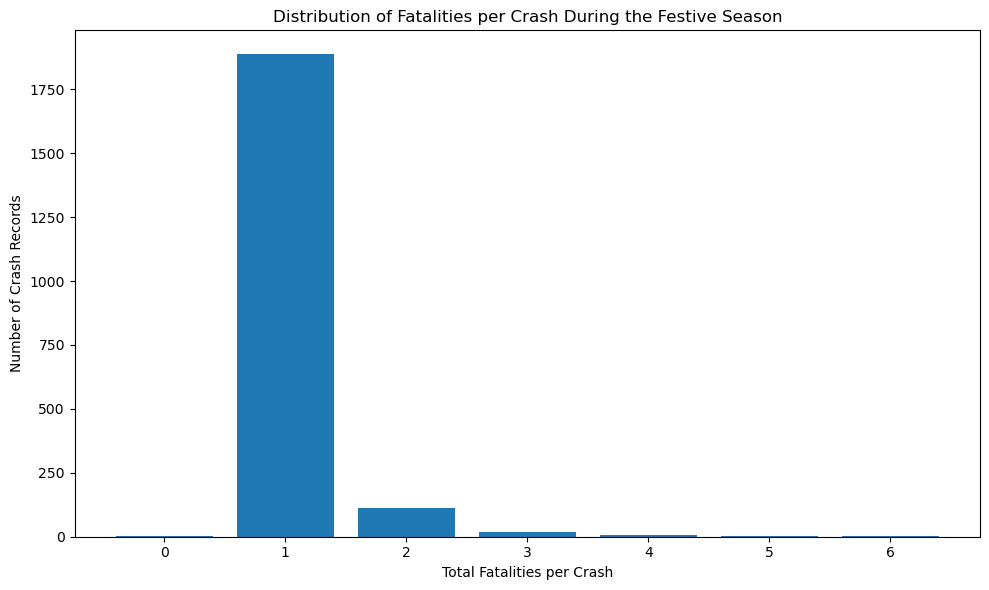

In [33]:
import matplotlib.pyplot as plt

# Festive-season fatalities
fatality_distribution = (df[df["FESTIVE_SEASON"] == 1]["TOTAL_FATALITIES"].value_counts().sort_index())

plt.figure(figsize=(10, 6))

plt.bar(fatality_distribution.index,fatality_distribution.values)

plt.xlabel("Total Fatalities per Crash")
plt.ylabel("Number of Crash Records")
plt.title("Distribution of Fatalities per Crash During the Festive Season")

plt.xticks(fatality_distribution.index)
plt.tight_layout()
plt.show()

### Distribution of Fatalities per Crash

The distribution of TOTAL_FATALITIES during the festive season was examined to assess the characteristics of the target variable.

The distribution was highly concentrated around one fatality per crash:

- **1 fatality:** 1,886 crash records (93.18%).
- **2 fatalities:** 111 crash records (5.48%).
- **3 fatalities:** 17 crash records (0.84%).
- **4 fatalities:** 6 crash records (0.30%).
- **5 fatalities:** 2 crash records (0.10%).
- **6 fatalities:** 1 crash record (0.05%).
- **0 fatalities:** 1 crash record (0.05%).

The distribution therefore demonstrates a strong concentration at one fatality, with substantially fewer observations involving multiple fatalities. This indicates that TOTAL_FATALITIES is a highly skewed count-based target variable.

This distribution was considered when selecting and evaluating the subsequent machine-learning models, particularly because a model may achieve relatively low prediction error by frequently predicting values close to the dominant value of one.

Looking at the relationship between the total vehicles involved and the total fatalities

In [34]:
from scipy.stats import spearmanr

festive_df = df[df["FESTIVE_SEASON"]==1].copy()

correlation, p_value = spearmanr(festive_df["TOTAL_VEHICLE_INVOLVED"],festive_df["TOTAL_FATALITIES"])

print("Spearman correlation:", correlation)
print("p-value:", p_value)

Spearman correlation: 0.21938164702489715
p-value: 1.7637010601201934e-23


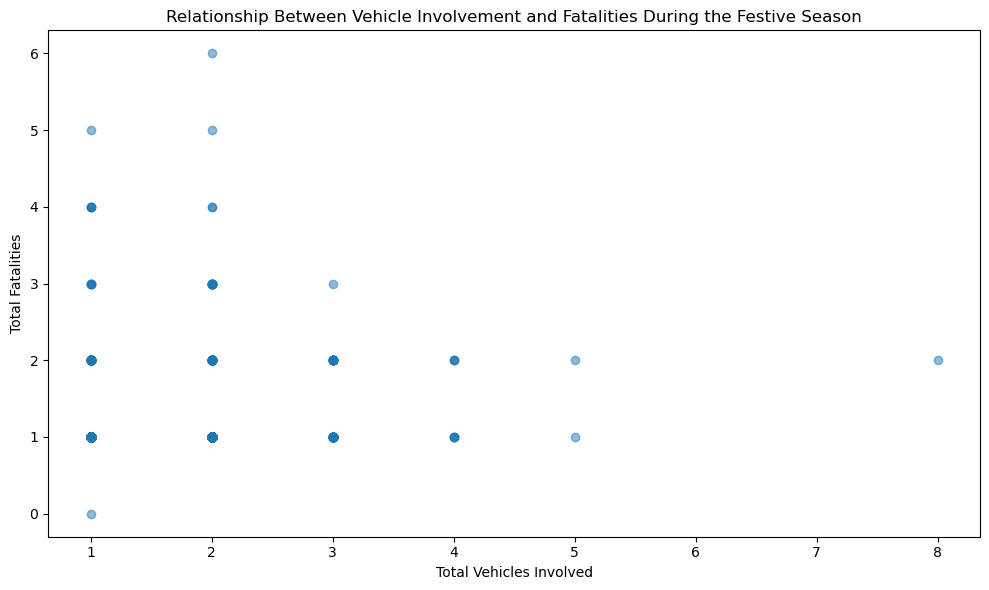

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(festive_df["TOTAL_VEHICLE_INVOLVED"],festive_df["TOTAL_FATALITIES"],alpha=0.5)
plt.xlabel("Total Vehicles Involved")
plt.ylabel("Total Fatalities")
plt.title("Relationship Between Vehicle Involvement and Fatalities During the Festive Season")
plt.tight_layout()
plt.show()

### Relationship Between Vehicle Involvement and Fatalities

The relationship between the number of vehicles involved in a crash and the number of fatalities was examined using Spearman's rank correlation because the target variable was highly skewed and represented count data.

A **positive Spearman correlation of 0.219** was observed between TOTAL_VEHICLE_INVOLVED and TOTAL_FATALITIE, indicating a positive but relatively weak monotonic association. The relationship was statistically significant (**p < 0.001**).

The scatter plot shows that most observations were concentrated around one to two vehicles and one fatality. Higher fatality counts were observed at different levels of vehicle involvement, although observations involving larger numbers of vehicles were relatively uncommon.

These results indicate that the number of vehicles involved is associated with fatalities, but the relatively weak correlation suggests that vehicle involvement alone does not explain a substantial proportion of the variation in TOTAL_FATALITIES.

Therefore, TOTAL_VEHICLE_INVOLVED will be retained as a candidate predictor for subsequent statistical analysis and machine-learning modelling.

Now examining anf looking at the relationship between Accident hours and total fatalities

In [36]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(festive_df["ACCIDENT_HOUR"],festive_df["TOTAL_FATALITIES"])
print("Spearman correlation:", correlation)
print("p-value:", p_value)

Spearman correlation: -0.004288043623061968
p-value: 0.8471187183163361


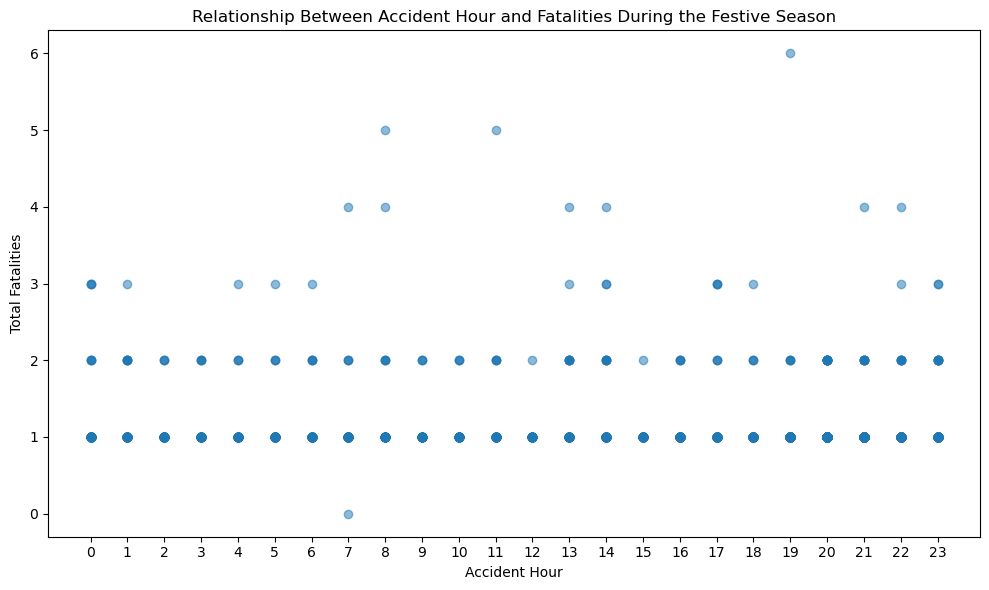

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(festive_df["ACCIDENT_HOUR"],festive_df["TOTAL_FATALITIES"],alpha=0.5)

plt.xlabel("Accident Hour")
plt.ylabel("Total Fatalities")
plt.title("Relationship Between Accident Hour and Fatalities During the Festive Season")

plt.xticks(range(24))
plt.tight_layout()
plt.show()

### Relationship Between Accident Hour and Fatalities

The relationship between ACCIDENT_HOUR and TOTAL_FATALITIES was initially examined using Spearman's rank correlation.

- **Spearman correlation:** -0.0043
- **p-value:** 0.8471

The result indicates **essentially no monotonic relationship** between accident hour and fatalities. The high p-value provides no statistical evidence of a monotonic association.

The scatter plot also shows that crashes involving one or two fatalities occurred throughout the day, while the relatively few higher-fatality crashes were distributed across different hours.

However, because ACCIDENT_HOUR represents a **cyclic time variable**, Spearman correlation is not considered the final test for this variable. A **Kruskal–Wallis test** will therefore be used to determine whether the distribution of TOTAL_FATALITIES differs significantly across the 24 accident-hour groups.

### Bottom Line

The preliminary analysis found **no monotonic association between accident hour and fatalities**. A group-based statistical test is required before determining whether ACCIDENT_HOUR should be considered a meaningful predictor of TOTAL_FATALITIES.

In [38]:
from scipy.stats import kruskal

hour_groups = [group["TOTAL_FATALITIES"].values
    for _, group in festive_df.groupby("ACCIDENT_HOUR")
]

statistic, p_value = kruskal(*hour_groups)

print("Kruskal-Wallis statistic:", statistic)
print("p-value:", p_value)

Kruskal-Wallis statistic: 22.21093225662353
p-value: 0.5075501059921463


### Statistical Relationship Between Accident Hour and Fatalities

A Kruskal–Wallis test was conducted to determine whether the distribution of TOTAL_FATALITIES differed across the 24 accident-hour groups.

- **Kruskal–Wallis statistic:** 22.21
- **p-value:** 0.5076

The result was **not statistically significant (p > 0.05)**, indicating no statistical evidence of a difference in the distribution of fatalities across accident hours during the festive season.

This finding is consistent with the preliminary Spearman correlation, which also showed no meaningful monotonic relationship between accident hour and fatalities.

### Bottom Line

Based on the current statistical analysis, **ACCIDENT_HOUR does not demonstrate a statistically significant relationship with TOTAL_FATALITIES**. It may therefore be given lower priority as a predictor in the subsequent modelling stage, although its potential predictive contribution can ultimately be assessed through model performance.

Examining type of crashes and total fatalities

In [39]:
from scipy.stats import kruskal

crash_type_groups = [group["TOTAL_FATALITIES"].values
    for _, group in festive_df.groupby("CRASH_TYPE_DESC")]
statistic, p_value = kruskal(*crash_type_groups)
print("Kruskal-Wallis statistic:", statistic)
print("p-value:", p_value)

Kruskal-Wallis statistic: 177.6625346769069
p-value: 2.4763135331502742e-29


### Relationship Between Crash Type and Fatalities

A Kruskal–Wallis test was conducted to determine whether the distribution of `TOTAL_FATALITIES` differed across the different crash types recorded during the festive season.

- **Kruskal–Wallis statistic:** 177.66
- **p-value:** 2.48 × 10⁻²⁹

The result was **statistically significant (p < 0.001)**, indicating that the distribution of fatalities was not the same across all crash types. This provides statistical evidence of differences in fatalities between at least some crash-type categories.

However, the Kruskal–Wallis test does not identify which specific crash types differ from one another. Therefore, a **post-hoc pairwise analysis** is required to identify the specific differences between crash-type groups.

### Bottom Line

The results provide strong statistical evidence that **CRASH_TYPE_DESC is associated with differences in TOTAL_FATALITIES**. Crash type will therefore be retained as an important candidate predictor for the subsequent machine-learning analysis.

In [40]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import itertools
import pandas as pd

#getting unique crash types
groups = festive_df["CRASH_TYPE_DESC"].dropna().unique()

results = []

# Performing pair wise Mann Whitney U tests
for group1, group2 in itertools.combinations(groups, 2):
    data1 = festive_df.loc[festive_df["CRASH_TYPE_DESC"]==group1,"TOTAL_FATALITIES"]
    data2 = festive_df.loc[festive_df["CRASH_TYPE_DESC"]==group2,"TOTAL_FATALITIES"]
    statistic, p_value = mannwhitneyu(data1,data2,alternative="two-sided")
    
    results.append({
        "CRASH_TYPE_1": group1,
        "CRASH_TYPE_2": group2,
        "U_STATISTIC": statistic,
        "RAW_P_VALUE": p_value
    })

dunn_alternative = pd.DataFrame(results)

# Holm correction for multiple comparisons
reject, adjusted_p, _, _ = multipletests(dunn_alternative["RAW_P_VALUE"],method="holm")

dunn_alternative["ADJUSTED_P_VALUE"] = adjusted_p
dunn_alternative["SIGNIFICANT"] = reject

#show only significant comparisons
significant_pairs = (dunn_alternative[dunn_alternative["SIGNIFICANT"]==True].sort_values("ADJUSTED_P_VALUE")
)

significant_pairs

,CRASH_TYPE_1,CRASH_TYPE_2,U_STATISTIC,RAW_P_VALUE,ADJUSTED_P_VALUE,SIGNIFICANT
5,Accident with pedestrian,Head on,33281.5,2.953968e-28,4.017396e-26,True
20,Hit and Run,Head on,26234.0,3.332337e-26,4.498654e-24,True
27,Hit and Run,Unknown,4677.0,5.279835e-11,7.074979e-09,True
19,Hit and Run,Single vehicle (overturned),49008.0,1.414493e-10,1.881276e-08,True
4,Accident with pedestrian,Single vehicle (overturned),62107.0,2.500742e-10,3.300979e-08,True
12,Accident with pedestrian,Unknown,5934.0,7.393797e-10,9.685874e-08,True
25,Hit and Run,Approach at angle (both trav. straight),11417.0,7.815568e-10,1.016024e-07,True
18,Hit and Run,Sideswipe (opposite directions),10113.0,2.956585e-09,3.813995e-07,True
21,Hit and Run,Head/rear end,27755.0,5.210481e-09,6.669416e-07,True
10,Accident with pedestrian,Approach at angle (both trav. straight),14474.5,5.696336e-09,7.234347e-07,True


### Post-Hoc Analysis of Crash Types


Following the statistically significant Kruskal–Wallis test, pairwise Mann–Whitney U tests were conducted to identify which specific crash types differed in their fatality patterns. In this context, the **fatality pattern (distribution)** refers to how the recorded numbers of fatalities (for example 1, 2, 3 or more fatalities) were spread across all crashes belonging to each crash type.

For example, the fatalities recorded across all **Head On** crashes were compared with the fatalities recorded across all **Accident with pedestrian** crashes. This allowed the analysis to determine whether the patterns of fatalities differed between the two crash types.

The Holm correction was applied to account for the large number of pairwise comparisons.

The post-hoc analysis identified **20 statistically significant pairwise differences** after adjustment. Several of the strongest differences involved comparisons between **Head On**, **Accident with pedestrian**, **Hit and Run**, and **Single vehicle (overturned)** crash types, with adjusted p-values below 0.001.

Significant differences were also observed between other crash-type categories, including comparisons involving **Sideswipe (opposite directions)**, **Approach at angle**, **Accident with fixed/other object**, and **Unknown**.

The results indicate that the significant overall Kruskal–Wallis finding was not attributable to a single comparison, but rather to differences between multiple crash-type groups. However, comparisons involving crash types with very few observations were interpreted cautiously because small group sizes can produce unstable estimates.


Overall, The post-hoc analysis provides further evidence that **CRASH_TYPE_DESC is associated with differences in the pattern of TOTAL_FATALITIES**. This supports retaining crash type as a predictor for the subsequent machine-learning analysis.

If all crash types had essentially the same fatality pattern, then knowing the crash type wouldn't give the ML model much useful information about the number of fatalities.

But if the fatality patterns differ significantly, then knowing the crash type provides information that may help predict the number of fatalities.

Comparing the district and the total fatalities

In [41]:
from scipy.stats import kruskal

district_groups = [group["TOTAL_FATALITIES"].values
    for _, group in festive_df.groupby("DISTRICT")]

statistic, p_value = kruskal(*district_groups)

print("Kruskal-Wallis statistic:", statistic)
print("p-value:", p_value)

Kruskal-Wallis statistic: 8.937741343617457
p-value: 0.06267463020051313


- 0.0627 > 0.05, so there is no statistically significant evidence that the distribution of TOTAL_FATALITIES differs across the five districts.

- So unlike CRASH_TYPE_DESC, we do not need a post-hoc pairwise test for DISTRICT.

- This does not mean district doesnt matter at all.

- It means that, based on this particular statistical test, we dont have enough evidence to say that the five districts have systematically different fatality distributions.

Comparing day of week and total fatalities

In [42]:
from scipy.stats import kruskal

day_groups = [group["TOTAL_FATALITIES"].values
    for _, group in festive_df.groupby("DAY_OF_WEEK")]

statistic, p_value = kruskal(*day_groups)

print("Kruskal-Wallis statistic:", statistic)
print("p-value:", p_value)

Kruskal-Wallis statistic: 11.065606716102144
p-value: 0.0863698180895126


- There is insufficient statistical evidence that the distribution of **TOTAL_FATALITIES** differs across the seven days of the week during the festive season.

- So we do not need post-hoc pairwise tests for **DAY_OF_WEEK**.

- This doesn't prove that the day of the week is useless for prediction. It simply means our statistical test did not find a significant difference at the 5% level.

Because **POLICE_STATION** has many categorical groups (146 stations), we can still use Kruskal–Wallis, but theres an important issue about many stations have very few festive-season observations, so the result could be heavily influenced by sparse groups.

In [43]:
station_counts = (festive_df["POLICE_STATION"].value_counts())

print(station_counts.describe())
print("\nStations with fewer than 5 observations:")
print((station_counts < 5).sum())

print("\nStations with at least 5 observations:")
print((station_counts >= 5).sum())

count    144.000000
mean      14.055556
std       10.230749
min        1.000000
25%        6.000000
50%       11.000000
75%       20.000000
max       48.000000
Name: count, dtype: float64

Stations with fewer than 5 observations:
24

Stations with at least 5 observations:
120


In [44]:
from scipy.stats import kruskal

station_groups = [group["TOTAL_FATALITIES"].values
    for _, group in festive_df.groupby("POLICE_STATION")
]

statistic, p_value = kruskal(*station_groups)

print("Kruskal-Wallis statistic:", statistic)
print("p-value:", p_value)

Kruskal-Wallis statistic: 102.05152669662782
p-value: 0.996098206634915


### Statistical Relationship Between Police Station and Fatalities

A Kruskal–Wallis test was conducted to determine whether the distribution of `TOTAL_FATALITIES` differed across police stations during the festive season.

- **Kruskal–Wallis statistic:** 102.05
- **p-value:** 0.9961

The result was **not statistically significant (p > 0.05)**, indicating that there is no statistical evidence that the distribution of fatalities differs across police stations in the festive-season dataset.

Although the number of crash records varied considerably between police stations, these differences in crash frequency did not correspond to statistically significant differences in the distribution of fatalities per crash.


- `POLICE_STATION` does not demonstrate a statistically significant relationship with `TOTAL_FATALITIES` in the current analysis. Its predictive contribution will therefore be assessed through the subsequent machine-learning modelling stage rather than being excluded solely on the basis of this statistical test.

Next its `ROAD_NUMBER` but because there is so many distinct road names, we need to handle that variable differently rather than throwing thousands of categories into another Kruskal–Wallis test.

In [45]:
#couting the roads
road_counts = (festive_df["ROAD_NAME_NUMBER"].value_counts())

print(road_counts.describe())
print("\nRoads with fewer than 5 observations:")
print((road_counts < 5).sum())
print("\nRoads with at least 5 observations:")
print((road_counts>= 5).sum())
print("\nTotal unique roads:")
print(road_counts.size)

count    899.000000
mean       2.218020
std        6.016058
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max      101.000000
Name: count, dtype: float64

Roads with fewer than 5 observations:
836

Roads with at least 5 observations:
63

Total unique roads:
899


# Road Name Standardisation

## Purpose

The `ROAD_NAME_NUMBER` variable was reviewed to identify inconsistencies that could
affect analysis of road-related patterns in the Gauteng crash data.

The original RTMC road-name values were retained, and a separate standardised
variable was created for analysis.

## Approach

Road names were reviewed using the recorded:

- District
- Police station
- Road name/number

Potential spelling errors and variations were investigated using the available
road-reference information and the surrounding dataset context.

Standardisation was applied only where the intended road name could be established
with reasonable confidence.

## Rules Applied

- Spelling and typographical errors were corrected where the intended road name
  was clear.
- Road types such as Road, Street, Drive and Avenue were retained where they
  represented meaningful distinctions.
- Route identifiers such as N1, N12, R59 and M1 were retained.
- Directional route information was retained where present.
- Junctions and compound descriptions were not arbitrarily assigned to a single
  road.
- Ambiguous or insufficiently supported entries were retained in their original
  form.

## Data Quality Consideration

Road-name information originates from the RTMC crash records and may contain
inconsistencies. Therefore, the standardisation process does not assume that every
record can be conclusively resolved.

Where sufficient evidence was unavailable, no correction was made.

## Reproducibility

The original `ROAD_NAME_NUMBER` variable was preserved. All standardised values
were created in a separate variable so that the transformation from the original
data can be traced and reviewed.

In [46]:
# Create the standardised road-name column
df_analysis = df.copy()
df_analysis["ROAD_NAME_STANDARDISED"] = df_analysis["ROAD_NAME_NUMBER"]

In [47]:
# Create the analysis copy
df_analysis = df.copy()

# Keep the original RTMC road name unchanged
df_analysis["ROAD_NAME_STANDARDISED"] = df_analysis["ROAD_NAME_NUMBER"]

# Apply the verified road-name mappings
verified_road_map = {
    '16 BEATRICE STRET': '16 BEATRICE STREET',
    '16 JUNE STREEET': '16 JUNE STREET',
    '22 LONGMEADOW BOULEVERD': '22 LONGMEADOW BOULEVARD',
    '3RD AVE': '3RD AVENUE',
    'ACACIA STREEET': 'ACACIA STREET',
    'ALBERTINA SISULU DRIDE': 'ALBERTINA SISULU ROAD',
    'ALBERTINA SISULU RD': 'ALBERTINA SISULU ROAD',
    'ALLANDALE OFFRAMP': 'ALLANDALE OFF RAMP',
    'ALLANDALE RD': 'ALLANDALE ROAD',
    'ANDREW MAPHETO DRIVEE': 'ANDREW MAPHETO DRIVE',
    'ATLAS ROADF': 'ATLAS ROAD',
    'BARRYHERTZOG AVENUE': 'BARRY HERTZOG AVENUE',
    'BAVIAANSPOORT STEET': 'BAVIAANSPOORT ROAD',
    'BEYERS HAUDE DRIVER': 'BEYERS NAUDE DRIVE',
    'BEYERS NAUDE DR': 'BEYERS NAUDE DRIVE',
    'BEYERSNAUDE DRIVE': 'BEYERS NAUDE DRIVE',
    'BOLANI RD': 'BOLANI ROAD',
    'BRAM FISCHERVILLE ROAD': 'BRAM FISHERVILLE ROAD',
    'BRAMFISCHER DRIVE': 'BRAM FISCHER DRIVE',
    'BRICKFIELD RD': 'BRICKFIELD ROAD',
    'BRONKHOSRTSPRUIT ROAD': 'BRONKHORSTSPRUIT ROAD',
    'CALBERTINA SISULU ROAD': 'ALBERTINA SISULU ROAD',
    'CAMBRIDGE RD': 'CAMBRIDGE ROAD',
    'CEDAR ROADD': 'CEDAR ROAD',
    'CHRIS HANI': 'CHRIS HANI ROAD',
    'CHRIS HANI RD': 'CHRIS HANI ROAD',
    'CHRISTIAAN DE WET RD': 'CHRISTIAAN DE WET ROAD',
    'CHRISTIAN DE WET DRIVE': 'CHRISTIAAN DE WET DRIVE',
    'COMISSIONER STREET': 'COMMISSIONER STREET',
    'DAAN DE WET NEL STREET': 'DAN DE WET NEL STREET',
    'DALE RD': 'DALE ROAD',
    'DELFOS BOULEVARED': 'DELFOS BOULEVARD',
    'DELMAS RD': 'DELMAS ROAD',
    'DEVON ROADM': 'DEVON ROAD',
    'DEWALD HATTING ROAD': 'DEWALD HATTINGH ROAD',
    'DONALD RD': 'DONALD ROAD',
    'DORE EVENUE': 'DOREEN AVENUE',
    'DR SWANEPOEL RD': 'DR SWANEPOEL ROAD',
    'EAST BANK AVENUEW': 'EAST BANK AVENUE',
    'EAST CENTRAL RD': 'EAST CENTRAL ROAD',
    'ELIAS MOTSOALED ROAD': 'ELIAS MOTSOALEDI ROAD',
    'ELIAS MOTSOALEDI STR': 'ELIAS MOTSOALEDI STREET',
    'ELJAH BARAYI ROAD': 'ELIJAH BARAYI ROAD',
    'EMAPHUPHENI STEET': 'EMAPHUPHENI STREET',
    'EMNDENI LINK': 'EMDENI LINK',
    'ERMELO RD': 'ERMELO ROAD',
    'ESKIA MPHAHLELE DR': 'ESKIA MPHAHLELE DRIVE',
    'EXT3 SOLOMON MAHLANGU RIOAD': 'EXT3 SOLOMON MAHLANGU ROAD',
    'FARENDEN STRRET': 'FARENDEN STREET',
    'FRIKKIE MEYER BOULEVALD': 'FRIKKIE MEYER BOULEVARD',
    'FRIKKIIE MEYER BOULEVARD': 'FRIKKIE MEYER BOULEVARD',
    'GENERAL HERTZOG STREET': 'GENERAL HERTOG STREET',
    'GEORGE STORRAR DRIVER': 'GEORGE STORRAR DRIVE',
    'GOLDEN HGHWAY': 'GOLDEN HIGHWAY',
    'GOLDEN HIGWAY': 'GOLDEN HIGHWAY',
    'GRASMERE RD': 'GRASMERE ROAD',
    'GRASMERE RIAD': 'GRASMERE ROAD',
    'HEALD RD': 'HEALD ROAD',
    'HEIDELBERG RD': 'HEIDELBERG ROAD',
    'HEIDELBERG ROAF': 'HEIDELBERG ROAD',
    'HEIDELBURG RD': 'HEIDELBURG ROAD',
    'HENDRICK POTGIETER ROAD': 'HENDRIK POTGIETER ROAD',
    'HENDRICK POTGIETER ROADR ROAF': 'HENDRIK POTGIETER ROAD',
    'HENDRICK VAN ECK BOULEVARD': 'HENDRICK VAN ECK BOULEVARD',
    'HENDRICK POTGIETER RD': 'HENDRIK POTGIETER ROAD',
    'HNNIE ALBERTS STREET': 'HENNIE ALBERTS STREET',
    'HOSPITAL RD': 'HOSPITAL ROAD',
    'HYDRANGEA AVE': 'HYDRANGEA AVENUE',
    'IMPALA RD': 'IMPALA ROAD',
    'ISSIE SMUTS TREET': 'ISSIE SMUTS STREET',
    'JOHAN LE ROUX': 'JOHAN LE ROUX ROAD',
    'KAMELFONTEIN ROAD': 'KAMEELFONTEIN ROAD',
    'KGOTSO STRET': 'KGOTSO STREET',
    'KOEDOE STREE': 'KOEDOE STREET',
    'KOOT STR': 'KOOT STREET',
    'LAWLEY RD': 'LAWLEY ROAD',
    'LEADWOOD STREEET': 'LEADWOOD STREET',
    'LENCHEN AVE': 'LENCHEN AVENUE',
    'LEONDALE RD': 'LEONDALE ROAD',
    'LIBANONI RORA': 'LIBANON ROAD',
    'LILIAN NGOYI STREET': 'LILLIAN NGOYI STREET',
    'LOVEDAY STRET': 'LOVEDAY STREET',
    'LUIPAARD STR': 'LUIPAARD STREET',
    'MAIN RD': 'MAIN ROAD',
    'MAIN REEF RD': 'MAIN REEF ROAD',
    'MARSALA STREE': 'MARSALA STREET',
    'MASAKHANE STREEET': 'MASAKHANE STREET',
    'MMABASOTHA STREE': 'MMABASOTHA STREET',
    'MODDERFONTEIN RD': 'MODDERFONTEIN ROAD',
    'MODJADJI RD': 'MODJADJI ROAD',
    'MOLEFE MAKNINTA ROAD': 'MOLEFE MAKINTA ROAD',
    'MONUMENT DRIVER': 'MONUMENT DRIVE',
    'NEW KLEINFOTEIN ROAD': 'NEW KLEINFONTEIN ROAD',
    'NEW RD': 'NEW ROAD',
    'NGUZA SRTEET': 'NGUZA STREET',
    'NIRVANA DR': 'NIRVANA DRIVE',
    'NITROGEN RD': 'NITROGEN ROAD',
    'NO STREE NAME': 'NO STREET NAME',
    'NORTH RAND RD': 'NORTH RAND ROAD',
    'NOTHERN PARKWAY ROAD': 'NORTHERN PARKWAY ROAD',
    'O STREET NAME': 'NO STREET NAME',
    'OLD PRETORIA MAIN RD': 'OLD PRETORIA MAIN ROAD',
    'OLD PRETORIA RD': 'OLD PRETORIA ROAD',
    'OLD PTA RD': 'OLD PTA ROAD',
    'OLIVIER ST': 'OLIVIER STREET',
    'OXFORD STR': 'OXFORD STREET',
    'PAUL KRUGER RD': 'PAUL KRUGER ROAD',
    'PAUL KRUGER STREE': 'PAUL KRUGER STREET',
    'PORTLAND VENUE': 'PORTLAND AVENUE',
    'PRETORIA RD': 'PRETORIA ROAD',
    'PRETORIA STEER': 'PRETORIA STREET',
    'PRIMULA SREET': 'PRIMULA STREET',
    'PRINCE GERORGE AVENUE': 'PRINCE GEORGE AVENUE',
    'PRITCHARD STR': 'PRITCHARD STREET',
    'R509 KOSTER ROADAR': 'R509 KOSTER ROAD',
    'RAILWAY ROAAD': 'RAILWAY ROAD',
    'RHOKANA STREEET': 'RHOKANA STREET',
    'RIETFONTEIN RD': 'RIETFONTEIN ROAD',
    'RIFLE RANGE': 'RIFLE RANGE ROAD',
    'RIVONIA RD': 'RIVONIA ROAD',
    'ROSE': 'ROSE ROAD',
    'ROSSETTENVILLE ROAD': 'ROSETTENVILLE ROAD',
    'RUBENSTEIN DRIVER': 'RUBENSTEIN DRIVE',
    'SCHOEMAN STRET': 'SCHOEMAN STREET',
    'SEFAKO MAKGATO DRIVE': 'SEFAKO MAKGATHO DRIVE',
    'SHAMROCK RD': 'SHAMROCK ROAD',
    'SILVERWRIGHT STREETQ': 'SILVERWRIGHT STREET',
    'SIMON VERMOTEN ROAD': 'SIMON VERMOETEN ROAD',
    'SOLOMON MAHLANGU DRIVER': 'SOLOMON MAHLANGU DRIVE',
    'SOLOMONA MAHLANGU DRIVE': 'SOLOMON MAHLANGU DRIVE',
    'SOUTPAN RD': 'SOUTPAN ROAD',
    'SPRINGS RD': 'SPRINGS ROAD',
    'SPRINGS ROADS': 'SPRINGS ROAD',
    'STANLEY RD': 'STANLEY ROAD',
    'STANZA BOPA PE STREET': 'STANZA BOPAPE STREET',
    'SWAARTKOPPIES ROAD': 'SWARTKOPPIES ROAD',
    'THABO SEHUME SREET': 'THABO SEHUME STREET',
    'TOTIUS RD': 'TOTIUS ROAD',
    'TRICHARD ROAD': 'TRICHARDT ROAD',
    'TRICHARD STREET': 'TRICHARDT STREET',
    'TRICHARDT': 'TRICHARDT',
    'TRICHARDTS': 'TRICHARDT',
    'TRICHARDTS ROAD': 'TRICHARDT ROAD',
    'TRICHARDTS STREET': 'TRICHARDT STREET',
    'TRICHARDTS STRET': 'TRICHARDT STREET',
    'TRICHART ROAD': 'TRICHARDT ROAD',
    'TRICHART STREET': 'TRICHARDT STREET',
    'TRICHARTS ROAD': 'TRICHARDT ROAD',
    'VAN RIEBECK STRET': 'VAN RIEBECK STREET',
    'VAN RIEBEECK STRET': 'VAN RIEBEECK STREET',
    'VAN ZYL SMIT STREETY': 'VAN ZYL SMIT STREET',
    'VANDER HOFF STREET': 'VAN DER HOFF STREET',
    'VENTERDORP STREET': 'VENTERSDORP STREET',
    'VENTERSDORP RD': 'VENTERSDORP ROAD',
    'VICKESRS ROAS': 'VICKERS ROAD',
    'VICTORIA STRET': 'VICTORIA STREET',
    'VON WEILIGH STREET': 'VON WEILLIGH STREET',
    'VOORTREKKER RD': 'VOORTREKKER ROAD',
    'WATERDAL RIOAD': 'WATERDAL ROAD',
    'WEILBACH RD': 'WEILBACH ROAD',
    'WEILBUCH RD': 'WEILBUCH ROAD',
    'WELGEDACHT RD': 'WELGEDACHT ROAD',
    'WF NKOMO STREETT': 'WF NKOMO STREET',
    'WILLIAM NICOLE DRIVE': 'WILLIAM NICOL DRIVE',
    'ZITHOBENI MAIN ROAD': 'ZINTHOBENI MAIN ROAD',
    'ZUURBEKOM ROAODO': 'ZUURBEKOM ROAD'
}

# Apply mappings
df_analysis["ROAD_NAME_STANDARDISED"] = (df_analysis["ROAD_NAME_NUMBER"].map(verified_road_map).fillna(df_analysis["ROAD_NAME_NUMBER"]))

In [48]:
# Check how many records changed
# Correctly identify records where the road name actually changed
changed = (df_analysis["ROAD_NAME_NUMBER"].notna()& df_analysis["ROAD_NAME_STANDARDISED"].notna()
    & (
        df_analysis["ROAD_NAME_NUMBER"]
        != df_analysis["ROAD_NAME_STANDARDISED"]
    )
)

print("Total records:", len(df_analysis))
print("Actual records standardised:", changed.sum())
print("Records unchanged:", (~changed).sum())
print("Missing road names:", df_analysis["ROAD_NAME_NUMBER"].isna().sum())

Total records: 17426
Actual records standardised: 211
Records unchanged: 17215
Missing road names: 309


In [49]:
# show fir every transformation that was made
changes = (df_analysis.loc[changed, ["ROAD_NAME_NUMBER", "ROAD_NAME_STANDARDISED"]].drop_duplicates().sort_values(["ROAD_NAME_NUMBER"]))

print("Distinct road-name transformations:", len(changes))
display(changes)

Distinct road-name transformations: 163


,ROAD_NAME_NUMBER,ROAD_NAME_STANDARDISED
3872,16 BEATRICE STRET,16 BEATRICE STREET
5309,16 JUNE STREEET,16 JUNE STREET
10661,22 LONGMEADOW BOULEVERD,22 LONGMEADOW BOULEVARD
16746,3RD AVE,3RD AVENUE
5373,ACACIA STREEET,ACACIA STREET
...,...,...
11217,WELGEDACHT RD,WELGEDACHT ROAD
16071,WF NKOMO STREETT,WF NKOMO STREET
3346,WILLIAM NICOLE DRIVE,WILLIAM NICOL DRIVE
1941,ZITHOBENI MAIN ROAD,ZINTHOBENI MAIN ROAD


In [50]:
# Show only genuine transformations
changes = (
    df_analysis.loc[
        changed,
        ["ROAD_NAME_NUMBER", "ROAD_NAME_STANDARDISED"]
    ]
    .drop_duplicates()
    .sort_values("ROAD_NAME_NUMBER")
)

print("Distinct genuine transformations:", len(changes))
display(changes)

Distinct genuine transformations: 163


,ROAD_NAME_NUMBER,ROAD_NAME_STANDARDISED
3872,16 BEATRICE STRET,16 BEATRICE STREET
5309,16 JUNE STREEET,16 JUNE STREET
10661,22 LONGMEADOW BOULEVERD,22 LONGMEADOW BOULEVARD
16746,3RD AVE,3RD AVENUE
5373,ACACIA STREEET,ACACIA STREET
...,...,...
11217,WELGEDACHT RD,WELGEDACHT ROAD
16071,WF NKOMO STREETT,WF NKOMO STREET
3346,WILLIAM NICOLE DRIVE,WILLIAM NICOL DRIVE
1941,ZITHOBENI MAIN ROAD,ZINTHOBENI MAIN ROAD


In [51]:
changes.to_csv("road_name_standardisation_audit.csv",index=False)
print("Saved:", len(changes), "distinct road-name transformations")

Saved: 163 distinct road-name transformations


In [52]:
print("Rows in df:", len(df))
print("Rows in df_analysis:", len(df_analysis))

print("\nColumns:")
print("ROAD_NAME_NUMBER" in df_analysis.columns)
print("ROAD_NAME_STANDARDISED" in df_analysis.columns)

Rows in df: 17426
Rows in df_analysis: 17426

Columns:
True
True


In [53]:
original_unchanged = df_analysis["ROAD_NAME_NUMBER"].equals(df["ROAD_NAME_NUMBER"])
print("Original ROAD_NAME_NUMBER unchanged:", original_unchanged)

Original ROAD_NAME_NUMBER unchanged: True


In [54]:
print("Missing ROAD_NAME_NUMBER:",df_analysis["ROAD_NAME_NUMBER"].isna().sum())
print("Missing ROAD_NAME_STANDARDISED:",df_analysis["ROAD_NAME_STANDARDISED"].isna().sum())

Missing ROAD_NAME_NUMBER: 309
Missing ROAD_NAME_STANDARDISED: 309


In [55]:
display(changes)

,ROAD_NAME_NUMBER,ROAD_NAME_STANDARDISED
3872,16 BEATRICE STRET,16 BEATRICE STREET
5309,16 JUNE STREEET,16 JUNE STREET
10661,22 LONGMEADOW BOULEVERD,22 LONGMEADOW BOULEVARD
16746,3RD AVE,3RD AVENUE
5373,ACACIA STREEET,ACACIA STREET
...,...,...
11217,WELGEDACHT RD,WELGEDACHT ROAD
16071,WF NKOMO STREETT,WF NKOMO STREET
3346,WILLIAM NICOLE DRIVE,WILLIAM NICOL DRIVE
1941,ZITHOBENI MAIN ROAD,ZINTHOBENI MAIN ROAD


In [56]:
# Extract all records with only the road-name columns
road_name_records = df_analysis[["ROAD_NAME_NUMBER", "ROAD_NAME_STANDARDISED"]].copy()

print("Total records:", len(road_name_records))
print("Columns:", list(road_name_records.columns))
display(road_name_records)

Total records: 17426
Columns: ['ROAD_NAME_NUMBER', 'ROAD_NAME_STANDARDISED']


,ROAD_NAME_NUMBER,ROAD_NAME_STANDARDISED
0,LANCASTER ROAD,LANCASTER ROAD
1,TAMBO ROAD,TAMBO ROAD
2,CO DUBE,CO DUBE
3,VAN DYK ROAD,VAN DYK ROAD
4,SINGH STREET,SINGH STREET
...,...,...
17421,KINGSWAY ROAD,KINGSWAY ROAD
17422,MAIN STREET,MAIN STREET
17423,PUBLIC ROAD,PUBLIC ROAD
17424,VILJOEN STREET,VILJOEN STREET


In [57]:
road_name_records.to_csv("Gauteng_Road_Name_Standardisation_All_Records.csv",index=False)
print("Saved successfully.")

Saved successfully.


In [58]:
# Check the current analysis dataset
print("Dataset shape:", df_analysis.shape)

print("\nColumns:")
for i, col in enumerate(df_analysis.columns, 1):
    print(f"{i}. {col}")

Dataset shape: (17426, 39)

Columns:
1. PROV
2. DISTRICT
3. POLICE_STATION
4. ACCIDENT_DATE
5. ACCIDENT_TIME
6. CRASH_TYPE_DESC
7. TOTAL_VEHICLE_INVOLVED
8. ROAD_NAME_NUMBER
9. PASSENGER
10. PEDESTRIAN
11. DRIVER
12. CYCLIST
13. UNKNOWN
14. BLACK
15. WHITE
16. ASIAN
17. COLOURED
18. OTHER
19. FOREIGNER
20. MALE
21. FEMALE
22. UNKNOWN_1
23. VEH1
24. VEH2
25. VEH3
26. VEH4
27. VEH5
28. VEH6
29. VEH7
30. VEH8
31. VEH9
32. VEH10
33. TOTAL_FATALITIES
34. FESTIVE_SEASON
35. FESTIVE_SEASON_YEAR
36. FESTIVE_SEASON_LABEL
37. ACCIDENT_HOUR
38. DAY_OF_WEEK
39. ROAD_NAME_STANDARDISED


In [59]:
# Check data types and missing values
variable_check = pd.DataFrame({"Data_Type": df_analysis.dtypes.astype(str),"Missing_Values": df_analysis.isna().sum(),"Unique_Values": df_analysis.nunique(dropna=True)})
display(variable_check)

,Data_Type,Missing_Values,Unique_Values
PROV,object,0,1
DISTRICT,object,0,5
POLICE_STATION,object,0,146
ACCIDENT_DATE,datetime64[ns],0,2863
ACCIDENT_TIME,object,0,1322
CRASH_TYPE_DESC,object,0,22
TOTAL_VEHICLE_INVOLVED,int64,0,13
ROAD_NAME_NUMBER,object,309,4957
PASSENGER,float64,14655,13
PEDESTRIAN,float64,7591,4


In [60]:
vehicle_columns = ["VEH1", "VEH2", "VEH3", "VEH4", "VEH5","VEH6", "VEH7", "VEH8", "VEH9", "VEH10"]

for col in vehicle_columns:
    print(f"\n{col}")
    print(df_analysis[col].value_counts(dropna=False))


VEH1
VEH1
Motor Car or Station Wagon    6624
Other                         4437
Light Delivery Vehicle        1846
NaN                           1658
Combi/Minibus                 1244
Motorcycle above > 125cc       493
GVM>3500kg (greater than)      393
Truck Articulated              352
Bus                            160
Panel Van                       67
Truck Articulated Multiple      60
Motorcycle 125cc and under      34
Midibus                         27
Bicycle                          8
Tractor                          7
Mobile Equipment (Driven)        5
Caravan/Trailer                  3
Bus-Train                        3
Quadrucycle                      3
Tricycle                         2
Name: count, dtype: int64

VEH2
VEH2
NaN                           13506
Motor Car or Station Wagon     1946
Light Delivery Vehicle          569
Other                           393
Combi/Minibus                   301
Motorcycle above > 125cc        257
Truck Articulated               181


In [61]:
# Compare the number of vehicles involved with the number
# of populated vehicle-type fields

vehicle_columns = ["VEH1", "VEH2", "VEH3", "VEH4", "VEH5","VEH6", "VEH7", "VEH8", "VEH9", "VEH10"]
df_analysis["VEHICLE_FIELDS_POPULATED"] = (df_analysis[vehicle_columns].notna().sum(axis=1))
vehicle_structure = (df_analysis.groupby("TOTAL_VEHICLE_INVOLVED")["VEHICLE_FIELDS_POPULATED"].value_counts().sort_index())
display(vehicle_structure)

TOTAL_VEHICLE_INVOLVED  VEHICLE_FIELDS_POPULATED
1                       0                            1230
                        1                           11810
                        2                              16
2                       0                             345
                        1                              65
                        2                            3318
                        3                               2
                        4                               1
3                       0                              44
                        1                               9
                        2                               1
                        3                             444
4                       0                              14
                        4                              93
5                       0                               2
                        5                              15
6                      

In [62]:
# Inspect unusual vehicle-count records
vehicle_anomalies = df_analysis[(df_analysis["TOTAL_VEHICLE_INVOLVED"] > 8) |((df_analysis["TOTAL_VEHICLE_INVOLVED"] <= 8) 
                                                                              &(df_analysis["VEHICLE_FIELDS_POPULATED"] == 0)
    )
]

display(vehicle_anomalies[["ACCIDENT_DATE","ACCIDENT_TIME","DISTRICT","POLICE_STATION","TOTAL_VEHICLE_INVOLVED","VEH1","VEH2","VEH3","VEH4","VEH5","VEH6","VEH7","VEH8","TOTAL_FATALITIES"]
    ]
)

,ACCIDENT_DATE,ACCIDENT_TIME,DISTRICT,POLICE_STATION,TOTAL_VEHICLE_INVOLVED,VEH1,VEH2,VEH3,VEH4,VEH5,VEH6,VEH7,VEH8,TOTAL_FATALITIES
7,2019-08-09,19:50,Ekurhuleni,ACTONVILLE,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
11,2019-07-16,07:51,Ekurhuleni,ACTONVILLE,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
15,2019-02-25,12:20,Ekurhuleni,ACTONVILLE,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
17,2019-07-27,23:27,Ekurhuleni,ACTONVILLE,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
21,2019-09-01,01:50,City of Tshwane,AKASIA,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13111,2019-04-06,13:00,Ekurhuleni,ZONKIZIZWE,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
13112,2019-07-22,06:30,Ekurhuleni,ZONKIZIZWE,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
13120,2019-07-21,12:55,Ekurhuleni,ZONKIZIZWE,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
13122,2019-09-29,07:00,Ekurhuleni,ZONKIZIZWE,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


In [63]:
print(df_analysis["TOTAL_VEHICLE_INVOLVED"].value_counts().sort_index())

TOTAL_VEHICLE_INVOLVED
1      13056
2       3731
3        498
4        107
5         17
6          5
7          3
8          4
9          1
10         1
11         1
14         1
111        1
Name: count, dtype: int64


The 111 is the obvious anomaly and should be investigated rather than silently corrected. The values 9, 10, 11 and 14 are rare, but they're not automatically errors.

We need to see the actual crash record before deciding whether 111 is:

- a genuine unusual RTMC value
- a data-entry error
- or something that needs to remain as supplied.

In [64]:
df_analysis[
    df_analysis["TOTAL_VEHICLE_INVOLVED"] == 111
][[
    "ACCIDENT_DATE",
    "ACCIDENT_TIME",
    "DISTRICT",
    "POLICE_STATION",
    "ROAD_NAME_NUMBER",
    "ROAD_NAME_STANDARDISED",
    "CRASH_TYPE_DESC",
    "TOTAL_VEHICLE_INVOLVED",
    "TOTAL_FATALITIES"
]]

,ACCIDENT_DATE,ACCIDENT_TIME,DISTRICT,POLICE_STATION,ROAD_NAME_NUMBER,ROAD_NAME_STANDARDISED,CRASH_TYPE_DESC,TOTAL_VEHICLE_INVOLVED,TOTAL_FATALITIES
5461,2021-09-04,22:30,City of Johannesburg,JEPPE,LAMOEN STREET,LAMOEN STREET,Accident with pedestrian,111,1.0


In [65]:
import numpy as np
# Remove the temporary investigation column
df_analysis = df_analysis.drop(columns=["VEHICLE_FIELDS_POPULATED"],errors="ignore")
#treating the 111 cars as an anomaly
df_analysis["TOTAL_VEHICLE_INVOLVED_CLEAN"] = (df_analysis["TOTAL_VEHICLE_INVOLVED"].replace(111, np.nan))
# Keep the original vehicle fields in df_analysis,
# but do not use VEH1–VEH10 as modelling predictors for now.

In [66]:
df_analysis[
    df_analysis["TOTAL_VEHICLE_INVOLVED"] > 8
][[
    "ACCIDENT_DATE",
    "ACCIDENT_TIME",
    "DISTRICT",
    "POLICE_STATION",
    "ROAD_NAME_NUMBER",
    "CRASH_TYPE_DESC",
    "TOTAL_VEHICLE_INVOLVED",
    "TOTAL_FATALITIES"
]].sort_values("TOTAL_VEHICLE_INVOLVED")

,ACCIDENT_DATE,ACCIDENT_TIME,DISTRICT,POLICE_STATION,ROAD_NAME_NUMBER,CRASH_TYPE_DESC,TOTAL_VEHICLE_INVOLVED,TOTAL_FATALITIES
11891,2021-05-09,15:00,Sedibeng,THE BARRAGE,N1,Head/rear end,9,3.0
13211,2024-05-20,11:18,Ekurhuleni,BEDFORDVIEW,N12,Head/rear end,10,2.0
6735,2023-09-03,03:00,City of Tshwane,LAUDIUM,R55,Hit and Run,11,1.0
8108,2019-05-19,06:30,City of Johannesburg,MONDEOR,N1,Unknown,14,4.0
5461,2021-09-04,22:30,City of Johannesburg,JEPPE,LAMOEN STREET,Accident with pedestrian,111,1.0


In [67]:
df_analysis[df_analysis["TOTAL_VEHICLE_INVOLVED"] == 111
][["ACCIDENT_DATE","TOTAL_VEHICLE_INVOLVED","TOTAL_VEHICLE_INVOLVED_CLEAN"]]

,ACCIDENT_DATE,TOTAL_VEHICLE_INVOLVED,TOTAL_VEHICLE_INVOLVED_CLEAN
5461,2021-09-04,111,NaN


In [68]:
df_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17426 entries, 0 to 17425
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   PROV                          17426 non-null  object        
 1   DISTRICT                      17426 non-null  object        
 2   POLICE_STATION                17426 non-null  object        
 3   ACCIDENT_DATE                 17426 non-null  datetime64[ns]
 4   ACCIDENT_TIME                 17426 non-null  object        
 5   CRASH_TYPE_DESC               17426 non-null  object        
 6   TOTAL_VEHICLE_INVOLVED        17426 non-null  int64         
 7   ROAD_NAME_NUMBER              17117 non-null  object        
 8   PASSENGER                     2771 non-null   float64       
 9   PEDESTRIAN                    9835 non-null   float64       
 10  DRIVER                        5102 non-null   float64       
 11  CYCLIST                     

In [69]:
for col in ["DISTRICT", "POLICE_STATION", "CRASH_TYPE_DESC"]:
    print(f"\n{col}")
    print(df_analysis[col].value_counts())


DISTRICT
DISTRICT
City of Johannesburg    5609
Ekurhuleni              4434
City of Tshwane         3926
Sedibeng                1838
West Rand               1619
Name: count, dtype: int64

POLICE_STATION
POLICE_STATION
KEMPTON PARK            341
SPRINGS                 340
MONDEOR                 337
MIDRAND                 325
VEREENIGING             314
                       ... 
DUBE                     10
PROTEA                   10
ROSEBANK                  9
FAIRLAND                  8
OR TAMBO INTERN AIRP      5
Name: count, Length: 146, dtype: int64

CRASH_TYPE_DESC
CRASH_TYPE_DESC
Accident with pedestrian                   5907
Hit and Run                                3865
Single vehicle (overturned)                2102
Head on                                    1258
Accident with fixed/other object           1124
Head/rear end                              1015
Approach at angle (both trav. straight)     443
Sideswipe (opposite directions)             429
Sideswipe (same

In [70]:
print("Unique road names:", df_analysis["ROAD_NAME_STANDARDISED"].nunique())
print("Missing road names:", df_analysis["ROAD_NAME_STANDARDISED"].isna().sum())
#the popular or commo road names
print("\nMost common road names:")
print(df_analysis["ROAD_NAME_STANDARDISED"].value_counts().head(20))

Unique road names: 4809
Missing road names: 309

Most common road names:
ROAD_NAME_STANDARDISED
N12               678
N1                665
N3                347
GOLDEN HIGHWAY    309
N14               300
R59               235
R21               232
N4                211
N/I               202
N17               193
R28               184
M1                184
MAIN REEF ROAD    159
R80               147
R101              145
R550              143
R55               134
R25               132
M2                128
R24               123
Name: count, dtype: int64


## Road Name Variable

The standardised road-name variable contains **4,809 unique road names** across 17,426 crash records, with **309 records missing a road name**.

Using the road name directly in the machine-learning models would create too many categories, with many roads appearing only a few times. This could make the models unnecessarily complex and produce unreliable estimates for rarely occurring roads.

Therefore, the original `ROAD_NAME_STANDARDISED` variable will be **retained for data analysis and reporting**, but it will not initially be used directly as a categorical predictor.

Instead, road information will be represented using broader road categories, such as **national routes (N), regional routes (R), metropolitan routes (M), and named roads**. This will retain relevant road information while reducing the number of categories used by the models.

The appropriate road categories will be determined from the values present in the dataset rather than being assigned arbitrarily.

In [71]:
import re

road_series = df_analysis["ROAD_NAME_STANDARDISED"].dropna().astype(str).str.upper().str.strip()
route_mask = road_series.str.match(r"^(N|R|M)\d+")

print("Route-code records:", route_mask.sum())
print("Non-route road records:", (~route_mask).sum())
print("Missing road records:", df_analysis["ROAD_NAME_STANDARDISED"].isna().sum())
print("\nRoute-code examples:")
print(df_analysis.loc[df_analysis["ROAD_NAME_STANDARDISED"].isin(road_series[route_mask].unique()),"ROAD_NAME_STANDARDISED"].value_counts().head(30))

Route-code records: 6270
Non-route road records: 10847
Missing road records: 309

Route-code examples:
ROAD_NAME_STANDARDISED
N12     678
N1      665
N3      347
N14     300
R59     235
R21     232
N4      211
N17     193
R28     184
M1      184
R80     147
R101    145
R550    143
R55     134
R25     132
M2      128
R24     123
R23     118
R42     101
R562     97
R554     97
R82      90
R559     84
R573     67
R511     65
R513     65
R41      59
R57      52
R558     52
R114     51
Name: count, dtype: int64


6,270 records (36.0%) have a route code (N, R, or M).
10,847 records (62.3%) have named/non-route roads.
309 records (1.8%) have no road name.

So the road variable isn't useless — we just need to represent it at a sensible level.

Next step

Let's create a road category based on the actual standardised values:

- N : National route
- R : Regional route
- M : Metropolitan/municipal route
- Other named roads : Named road
- Missing : Unknown

But before creating it, let's make sure there aren't other route formats that our current N/R/M + number rule missed.

In [72]:
road_series = (df_analysis["ROAD_NAME_STANDARDISED"].dropna().astype(str).str.upper().str.strip())
print(road_series[~road_series.str.match(r"^(N|R|M)\d+$")].value_counts().head(50))

ROAD_NAME_STANDARDISED
GOLDEN HIGHWAY            309
N/I                       202
MAIN REEF ROAD            159
NO STREET NAME            108
IMPALA ROAD                88
PRETORIA ROAD              80
CHRIS HANI ROAD            72
HEIDELBERG ROAD            66
MAIN ROAD                  65
RANDFONTEIN ROAD           61
SOUTPAN ROAD               59
ANDREW MAPHETO DRIVE       57
SOLOMON MAHLANGU DRIVE     51
BARRY MARAIS ROAD          47
REPUBLIC ROAD              43
BEYERS NAUDE DRIVE         43
ELIAS MOTSOALEDI ROAD      42
COMMISSIONER STREET        42
K43                        41
MODDERFONTEIN ROAD         40
KINGSWAY ROAD              40
MALIBONGWE DRIVE           38
OLD VEREENIGING ROAD       38
WELGEDACHT ROAD            38
ALLANDALE ROAD             36
WF NKOMO STREET            32
RAILWAY STREET             32
HENDRIK POTGIETER ROAD     32
SWARTKOPPIES ROAD          31
MOLEFE MAKINTA ROAD        31
ZUURFONTEIN ROAD           30
MOLOTO ROAD                30
WITKOPPEN ROAD   

## Road Category Preparation

Because `ROAD_NAME_STANDARDISED` contains a high number of unique road names, the variable will not be used directly as a categorical predictor.

Instead, road names will be grouped into broader categories based on the road identifiers recorded in the dataset:

- **National Route (N)** roads identified by an `N` route number.
- **Regional Route (R)** roads identified by an `R` route number.
- **Metropolitan/Municipal Route (M)** roads identified by an `M` route number.
- **Other Route (K)** route identifiers such as `K43`.
- **Named Road** roads recorded using a road name rather than a route identifier.
- **Unknown/Non-specific** missing road names and entries such as `N/I` or `NO STREET NAME`.

This approach reduces the high cardinality of the original road-name variable while retaining broad information about the type of road associated with each crash.

The original `ROAD_NAME_STANDARDISED` variable will be retained for reference and descriptive analysis.

In [73]:
import numpy as np

def classify_road(road):
    if pd.isna(road):
        return "Unknown"

    road = str(road).strip().upper()

    if re.fullmatch(r"N\d+", road):
        return "N Route"
    elif re.fullmatch(r"R\d+", road):
        return "R Route"
    elif re.fullmatch(r"M\d+", road):
        return "M Route"
    elif re.fullmatch(r"K\d+", road):
        return "K Route"
    elif road in ["N/I", "NO STREET NAME"]:
        return "Unknown"
    else:
        return "Named Road"
df_analysis["ROAD_CATEGORY"] = (df_analysis["ROAD_NAME_STANDARDISED"].apply(classify_road))

In [74]:
df_analysis["ROAD_CATEGORY"].value_counts(dropna=False)

ROAD_CATEGORY
Named Road    10682
R Route        3082
N Route        2402
Unknown         619
M Route         574
K Route          67
Name: count, dtype: int64

In [75]:
df_analysis["ACCIDENT_HOUR"].value_counts().sort_index()

ACCIDENT_HOUR
0      595
1      543
2      512
3      463
4      447
5      660
6      811
7      817
8      488
9      416
10     422
11     455
12     426
13     496
14     571
15     631
16     775
17     873
18    1378
19    1489
20    1369
21    1028
22     938
23     823
Name: count, dtype: int64

In [76]:
df_analysis["FESTIVE_SEASON"].value_counts()

FESTIVE_SEASON
0    15402
1     2024
Name: count, dtype: int64

In [77]:
pd.crosstab(df_analysis["FESTIVE_SEASON_LABEL"],df_analysis["FESTIVE_SEASON"])

FESTIVE_SEASON,0,1
FESTIVE_SEASON_LABEL,,
2017/18,0,51
2018/19,0,256
2019/20,0,233
2020/21,0,220
2021/22,0,268
2022/23,0,279
2023/24,0,297
2024/25,0,229
2025/26,0,191


In [78]:
df_festive = df_analysis[df_analysis["FESTIVE_SEASON"]== 1].copy()
print("Festive dataset shape:", df_festive.shape)

Festive dataset shape: (2024, 41)


In [79]:
df_festive["FESTIVE_SEASON_LABEL"].value_counts().sort_index()

FESTIVE_SEASON_LABEL
2017/18     51
2018/19    256
2019/20    233
2020/21    220
2021/22    268
2022/23    279
2023/24    297
2024/25    229
2025/26    191
Name: count, dtype: int64

In [80]:
print("rows:", len(df_festive))
print("Target missing:", df_festive["TOTAL_FATALITIES"].isna().sum())
print("Mean of target variable:", df_festive["TOTAL_FATALITIES"].mean())
print("max fatalties recorded in festive crashes:", df_festive["TOTAL_FATALITIES"].max())

rows: 2024
Target missing: 0
Mean of target variable: 1.0864624505928853
max fatalties recorded in festive crashes: 6.0


The mean of 1.086 means that, across the 2,024 festive crashes, the average number of fatalities recorded per crash is about 1.09. It does not mean thst 1.09 people died in each individual crash.

2017/2018 and 2025/2026 have missing data and they need to be dealt with before any forecasting takesplace.

In [81]:
season_summary = (df_festive.groupby("FESTIVE_SEASON_LABEL").agg(CRASHES=("TOTAL_FATALITIES", "size"),TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")).reset_index())
display(season_summary)

,FESTIVE_SEASON_LABEL,CRASHES,TOTAL_FATALITIES,MEAN_FATALITIES
0,2017/18,51,56.0,1.098039
1,2018/19,256,280.0,1.093750
2,2019/20,233,257.0,1.103004
3,2020/21,220,238.0,1.081818
4,2021/22,268,299.0,1.115672
5,2022/23,279,299.0,1.071685
6,2023/24,297,321.0,1.080808
7,2024/25,229,238.0,1.039301
8,2025/26,191,211.0,1.104712


- The 2024 festive crashes account for 2499 fatalities in total.
- The mean fatalities per crash range from about 1.04 to 1.12, so the average is relatively stable across seasons.
- 2017/18 is clearly much smaller in terms of recorded crashes (51), which supports treating it as an incomplete season.
- 2025/26 also has fewer records (191) than most of the middle seasons, but we shouldn't automatically conclude that the season is incomplete solely from this table.

In [82]:
season_dates = (df_festive.groupby("FESTIVE_SEASON_LABEL").agg(FIRST_DATE=("ACCIDENT_DATE", "min"),LAST_DATE=("ACCIDENT_DATE", "max"),
        CRASHES=("TOTAL_FATALITIES", "size")).reset_index())
display(season_dates)

,FESTIVE_SEASON_LABEL,FIRST_DATE,LAST_DATE,CRASHES
0,2017/18,2018-01-01,2018-01-11,51
1,2018/19,2018-12-01,2019-01-11,256
2,2019/20,2019-12-01,2020-01-11,233
3,2020/21,2020-12-01,2021-01-11,220
4,2021/22,2021-12-01,2022-01-11,268
5,2022/23,2022-12-01,2023-01-11,279
6,2023/24,2023-12-01,2024-01-11,297
7,2024/25,2024-12-01,2025-01-11,229
8,2025/26,2025-12-01,2025-12-31,191


In [83]:
#festive season data that has everything
complete_seasons = ["2018/19","2019/20","2020/21","2021/22","2022/23","2023/24","2024/25"]
df_festive_complete = df_analysis[df_analysis["FESTIVE_SEASON_LABEL"].isin(complete_seasons)].copy()
print("Complete festive dataset shape:", df_festive_complete.shape)

Complete festive dataset shape: (1782, 41)


In [84]:
df_festive_complete["FESTIVE_SEASON_LABEL"].value_counts().sort_index()

FESTIVE_SEASON_LABEL
2018/19    256
2019/20    233
2020/21    220
2021/22    268
2022/23    279
2023/24    297
2024/25    229
Name: count, dtype: int64

Setting up the modelling datsets

In [85]:
model_columns = ["DISTRICT","POLICE_STATION","CRASH_TYPE_DESC","TOTAL_VEHICLE_INVOLVED_CLEAN","ROAD_CATEGORY","ACCIDENT_HOUR","DAY_OF_WEEK","FESTIVE_SEASON_YEAR","TOTAL_FATALITIES"]

df_model = df_festive_complete[model_columns].copy()
print("Modelling dataset shape:", df_model.shape)
display(df_model.head())

Modelling dataset shape: (1782, 9)


,DISTRICT,POLICE_STATION,CRASH_TYPE_DESC,TOTAL_VEHICLE_INVOLVED_CLEAN,ROAD_CATEGORY,ACCIDENT_HOUR,DAY_OF_WEEK,FESTIVE_SEASON_YEAR,TOTAL_FATALITIES
6,Ekurhuleni,ACTONVILLE,Hit and Run,1.0,Named Road,14,Tuesday,2021,1.0
13,Ekurhuleni,ACTONVILLE,Hit and Run,1.0,Named Road,20,Thursday,2021,1.0
16,Ekurhuleni,ACTONVILLE,Accident with fixed/other object,1.0,R Route,8,Wednesday,2023,1.0
29,City of Tshwane,AKASIA,"Approach at angle, One or both turning",2.0,Named Road,9,Friday,2023,1.0
52,City of Tshwane,AKASIA,Sideswipe (opposite directions),2.0,R Route,22,Saturday,2022,1.0


# Festive-Season Modelling Dataset

## Festive-Season Coverage

The RTMC festive season was defined as **1 December to 11 January**. The dataset was therefore assessed to determine whether each festive season contained the complete period.

The following seasons were identified:

- **2017/18:** Incomplete bacause data available only from 1–11 January 2018.
- **2018/19:** Complete.
- **2019/20:** Complete.
- **2020/21:** Complete.
- **2021/22:** Complete.
- **2022/23:** Complete.
- **2023/24:** Complete.
- **2024/25:** Complete.
- **2025/26:** Incomplete because data available only from 1–31 December 2025.

For the primary machine-learning analysis, only the **seven complete festive seasons (2018/19–2024/25)** were used. This resulted in **1,782 crash records**.

The incomplete 2017/18 and 2025/26 seasons were retained in the full dataset for transparency and may be considered separately as supplementary or sensitivity analysis. They were not included in the primary modelling dataset because they do not cover the complete festive-season period.

## Modelling Variables

The modelling dataset contains the following predictors:

- `DISTRICT`
- `POLICE_STATION`
- `CRASH_TYPE_DESC`
- `TOTAL_VEHICLE_INVOLVED_CLEAN`
- `ROAD_CATEGORY`
- `ACCIDENT_HOUR`
- `DAY_OF_WEEK`
- `FESTIVE_SEASON_YEAR`

The target variable is: - `TOTAL_FATALITIES`

Variables forming part of the fatality calculation, such as `PASSENGER`, `PEDESTRIAN`, `DRIVER`, and `CYCLIST`, were excluded from the predictors to prevent **target leakage**.

Gender, demographic, and individual vehicle-type variables were also excluded from the initial modelling dataset because of substantial missingness and/or limited suitability for the planned analysis.

## Road Variable Preparation

The original standardised road-name variable contained **4,809 unique road names**. Using it directly would result in a high-cardinality categorical variable.

Therefore, `ROAD_NAME_STANDARDISED` was converted into the broader `ROAD_CATEGORY` variable:

- `N Route`
- `R Route`
- `M Route`
- `K Route`
- `Named Road`
- `Unknown`

This reduced the road variable to six categories while retaining broad road-related information for modelling.

The original road-name variables were retained in the dataset for reference and descriptive analysis.

## Vehicle Count Preparation

The `TOTAL_VEHICLE_INVOLVED` variable contained one anomalous value of **111 vehicles**. The corresponding crash record was reviewed and the value was considered inconsistent with the dataset.

The original value was retained for traceability, while a cleaned modelling variable, `TOTAL_VEHICLE_INVOLVED_CLEAN`, was created with this value replaced by `NaN`.

Other high vehicle-count values (9, 10, 11 and 14) were retained because there was insufficient evidence to classify them as errors.

In [86]:
df_model.isna().sum()
df_model.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1782 entries, 6 to 16107
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   DISTRICT                      1782 non-null   object 
 1   POLICE_STATION                1782 non-null   object 
 2   CRASH_TYPE_DESC               1782 non-null   object 
 3   TOTAL_VEHICLE_INVOLVED_CLEAN  1782 non-null   float64
 4   ROAD_CATEGORY                 1782 non-null   object 
 5   ACCIDENT_HOUR                 1782 non-null   int32  
 6   DAY_OF_WEEK                   1782 non-null   object 
 7   FESTIVE_SEASON_YEAR           1782 non-null   int32  
 8   TOTAL_FATALITIES              1782 non-null   float64
dtypes: float64(2), int32(2), object(5)
memory usage: 125.3+ KB


In [87]:
#checking the number of categories in each predictor and their frequency
categorical_columns = ["DISTRICT","POLICE_STATION","CRASH_TYPE_DESC","ROAD_CATEGORY","DAY_OF_WEEK"]

for col in categorical_columns:
    print(f"\n{col}")
    print("Number of categories:", df_model[col].nunique())
    print(df_model[col].value_counts())


DISTRICT
Number of categories: 5
DISTRICT
City of Johannesburg    596
Ekurhuleni              450
City of Tshwane         404
Sedibeng                183
West Rand               149
Name: count, dtype: int64

POLICE_STATION
Number of categories: 144
POLICE_STATION
BENONI              42
MONDEOR             41
ORANGE FARMS        40
ELDORADO PARK       39
BRONKHORSTSPRUIT    34
                    ..
WEDELA               1
LAUDIUM              1
NALEDI               1
ROSEBANK             1
PROTEA               1
Name: count, Length: 144, dtype: int64

CRASH_TYPE_DESC
Number of categories: 15
CRASH_TYPE_DESC
Accident with pedestrian                   578
Hit and Run                                441
Single vehicle (overturned)                192
Accident with fixed/other object           144
Head on                                    118
Head/rear end                              109
Approach at angle (both trav. straight)     46
Sideswipe (opposite directions)             40
Accident

In [88]:
df_festive_complete["FESTIVE_SEASON_YEAR"].value_counts().sort_index()

FESTIVE_SEASON_YEAR
2018    256
2019    233
2020    220
2021    268
2022    279
2023    297
2024    229
Name: count, dtype: int64

In [89]:
season_target = (df_festive_complete.groupby("FESTIVE_SEASON_YEAR")["TOTAL_FATALITIES"].agg(["count", "mean", "std", "min", "max"]).reset_index())
display(season_target)

,FESTIVE_SEASON_YEAR,count,mean,std,min,max
0,2018,256,1.093750,0.352859,0.0,3.0
1,2019,233,1.103004,0.412770,1.0,4.0
2,2020,220,1.081818,0.320725,1.0,4.0
3,2021,268,1.115672,0.384212,1.0,4.0
4,2022,279,1.071685,0.320557,1.0,4.0
5,2023,297,1.080808,0.394475,1.0,6.0
6,2024,229,1.039301,0.270204,1.0,4.0


This confirms that FESTIVE_SEASON_YEAR doesn't show a strong or consistent relationship with the target in these seven seasons. The mean fatalities range from about 1.04 to 1.12, and the sample sizes vary between 220 and 297.

One important issue before splitting

Because we're using a chronological train-test split, we should avoid randomly mixing observations from the same festive season between training and testing.

A reasonable primary split is:

Training
- 2018/19
- 2019/20
- 2020/21
- 2021/22
- 2022/23

Test
- 2023/24
- 2024/25

That gives:
- Training: 1,256 crashes
- Testing: 526 crashes

In [90]:
train_seasons = ["2018/19", "2019/20", "2020/21", "2021/22", "2022/23"]
test_seasons = ["2023/24", "2024/25"]

print("Training records:",df_festive_complete[df_festive_complete["FESTIVE_SEASON_LABEL"].isin(train_seasons)].shape[0])
print("Testing records:",df_festive_complete[df_festive_complete["FESTIVE_SEASON_LABEL"].isin(test_seasons)].shape[0])

Training records: 1256
Testing records: 526


In [91]:
train_seasons = ["2018/19","2019/20","2020/21","2021/22","2022/23"]

test_seasons = ["2023/24","2024/25"]

train_mask = df_festive_complete["FESTIVE_SEASON_LABEL"].isin(train_seasons)
test_mask = df_festive_complete["FESTIVE_SEASON_LABEL"].isin(test_seasons)

train_data = df_festive_complete[train_mask].copy()
test_data = df_festive_complete[test_mask].copy()

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

Training shape: (1256, 41)
Testing shape: (526, 41)


In [92]:
#the predictors
predictor_columns = ["DISTRICT","CRASH_TYPE_DESC","TOTAL_VEHICLE_INVOLVED_CLEAN","ROAD_CATEGORY","ACCIDENT_HOUR","DAY_OF_WEEK","FESTIVE_SEASON_YEAR"]

X_train = train_data[predictor_columns].copy()
y_train = train_data["TOTAL_FATALITIES"].copy()

X_test = test_data[predictor_columns].copy()
y_test = test_data["TOTAL_FATALITIES"].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1256, 7)
y_train: (1256,)
X_test: (526, 7)
y_test: (526,)


## Data Preprocessing and Categorical Encoding

The predictor variables consist of both categorical and numerical variables.

The categorical variables are:

- `DISTRICT`
- `CRASH_TYPE_DESC`
- `ROAD_CATEGORY`
- `DAY_OF_WEEK`

These variables will be converted into numerical form using **one-hot encoding** so that they can be used by the machine-learning algorithms.

The numerical variables are:

- `TOTAL_VEHICLE_INVOLVED_CLEAN`
- `ACCIDENT_HOUR`
- `FESTIVE_SEASON_YEAR`

The categorical encoder will be fitted using the **training data only** and then applied to the testing data. This prevents information from the testing seasons from being used during model training and helps avoid data leakage.

A `ColumnTransformer` will be used to apply the appropriate preprocessing to each group of variables.

In [93]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["DISTRICT","CRASH_TYPE_DESC","ROAD_CATEGORY","DAY_OF_WEEK"]

numeric_features = ["TOTAL_VEHICLE_INVOLVED_CLEAN","ACCIDENT_HOUR","FESTIVE_SEASON_YEAR"]

preprocessor = ColumnTransformer(
    transformers=[("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_features),("numeric","passthrough",numeric_features)])

## Applying the Preprocessing

The preprocessing pipeline is fitted using the training data only.

The fitted preprocessing steps are then applied to both the training and testing datasets. This ensures that the testing data remains unseen during the preparation of the model inputs.

One-hot encoding converts each categorical variable into binary indicator variables, while the numerical variables are passed through unchanged.

In [94]:
# Fit the preprocessor using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessor to the test data
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (1256, 36)
Processed X_test shape: (526, 36)


## Encoded Feature Inspection

After one-hot encoding, the original categorical variables are represented by binary indicator features.

The four categorical predictors were expanded into separate encoded features, while the three numerical predictors were retained as numerical variables.

The resulting training and testing datasets contain the same **36 model features**, ensuring that both datasets have a consistent structure for model training and evaluation.

In [95]:
feature_names = preprocessor.get_feature_names_out()

print("Number of generated features:", len(feature_names))

for i, feature in enumerate(feature_names, start=1):
    print(f"{i}. {feature}")

Number of generated features: 36
1. categorical__DISTRICT_City of Johannesburg
2. categorical__DISTRICT_City of Tshwane
3. categorical__DISTRICT_Ekurhuleni
4. categorical__DISTRICT_Sedibeng
5. categorical__DISTRICT_West Rand
6. categorical__CRASH_TYPE_DESC_Accident with Pedal Cyclist
7. categorical__CRASH_TYPE_DESC_Accident with fixed/other object
8. categorical__CRASH_TYPE_DESC_Accident with pedestrian
9. categorical__CRASH_TYPE_DESC_Approach at angle (both trav. straight)
10. categorical__CRASH_TYPE_DESC_Approach at angle,  One or both turning
11. categorical__CRASH_TYPE_DESC_Head on
12. categorical__CRASH_TYPE_DESC_Head/rear end
13. categorical__CRASH_TYPE_DESC_Hit and Run
14. categorical__CRASH_TYPE_DESC_Person fell off
15. categorical__CRASH_TYPE_DESC_Sideswipe (opposite directions)
16. categorical__CRASH_TYPE_DESC_Sideswipe (same direction)
17. categorical__CRASH_TYPE_DESC_Single vehicle (left the road)
18. categorical__CRASH_TYPE_DESC_Single vehicle (overturned)
19. categorical_

## Treatment of Festive Season

`FESTIVE_SEASON_YEAR` identifies the festive season in which each crash occurred. Since the numerical difference between seasons does not necessarily represent a proportional change in the outcome, the variable will be treated as a categorical variable rather than as a continuous numerical predictor.

One-hot encoding will therefore be applied to `FESTIVE_SEASON_YEAR`, allowing the models to account for differences between festive seasons without imposing a linear relationship between year and fatalities.

In [96]:
categorical_features = ["DISTRICT","CRASH_TYPE_DESC","ROAD_CATEGORY","DAY_OF_WEEK","FESTIVE_SEASON_YEAR"]
numeric_features = ["TOTAL_VEHICLE_INVOLVED_CLEAN","ACCIDENT_HOUR"]

In [97]:
preprocessor = ColumnTransformer(
    transformers=[("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_features),("numeric","passthrough",numeric_features)])

In [98]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (1256, 40)
Processed X_test shape: (526, 40)


In [99]:
feature_names = preprocessor.get_feature_names_out()

for i, feature in enumerate(feature_names, start=1):
    print(f"{i}. {feature}")

1. categorical__DISTRICT_City of Johannesburg
2. categorical__DISTRICT_City of Tshwane
3. categorical__DISTRICT_Ekurhuleni
4. categorical__DISTRICT_Sedibeng
5. categorical__DISTRICT_West Rand
6. categorical__CRASH_TYPE_DESC_Accident with Pedal Cyclist
7. categorical__CRASH_TYPE_DESC_Accident with fixed/other object
8. categorical__CRASH_TYPE_DESC_Accident with pedestrian
9. categorical__CRASH_TYPE_DESC_Approach at angle (both trav. straight)
10. categorical__CRASH_TYPE_DESC_Approach at angle,  One or both turning
11. categorical__CRASH_TYPE_DESC_Head on
12. categorical__CRASH_TYPE_DESC_Head/rear end
13. categorical__CRASH_TYPE_DESC_Hit and Run
14. categorical__CRASH_TYPE_DESC_Person fell off
15. categorical__CRASH_TYPE_DESC_Sideswipe (opposite directions)
16. categorical__CRASH_TYPE_DESC_Sideswipe (same direction)
17. categorical__CRASH_TYPE_DESC_Single vehicle (left the road)
18. categorical__CRASH_TYPE_DESC_Single vehicle (overturned)
19. categorical__CRASH_TYPE_DESC_Turn right in fa

## Final Preprocessing and Data Split

The final modelling dataset contains **1,782 crash records** from the seven complete festive seasons (2018/19–2024/25).

A chronological train-test split was used to prevent information from later festive seasons being included in model training.

- **Training set:** 1256 crashes from 2018/19–2022/23
- **Testing set:** 526 crashes from 2023/24–2024/25

The predictor variables were transformed using one-hot encoding for categorical variables, while numerical variables were retained in their numerical form.

The preprocessing was fitted **only on the training data** and then applied to the testing data to prevent data leakage.

The preprocessing produced **40 model features**.

The 2024 festive season was not present in the training categories and was therefore treated as an unseen category during testing. `handle_unknown="ignore"` was used to allow the model to process this test data without using information from it during training.

The final processed data is therefore:

- **Training:** 1256 observations × 40 features
- **Testing:** 526 observations × 40 features

The processed datasets are now ready for machine-learning model development and evaluation.

## Baseline Model

A baseline model was established before training the machine-learning algorithms. The baseline predicts the mean number of fatalities observed in the training data for every crash in the testing set.

This provides a reference point against which the performance of the machine-learning models can be evaluated.

Model performance will primarily be assessed using RMSE, with MAE and R² used as additional evaluation metrics.

A machine-learning model should demonstrate improvement over the baseline to provide evidence that the predictors contribute useful information for predicting road traffic fatalities.

- The question its , Can this model predict fatalities better than simply predicting the average every time?

In [100]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

#Baseline prediction for mean fatalities from training data
baseline_prediction = np.repeat( y_train.mean(),len(y_test))
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))
baseline_mae = mean_absolute_error(y_test,baseline_prediction)
baseline_r2 = r2_score(y_test,baseline_prediction)

print("Baseline RMSE:", baseline_rmse)
print("Baseline MAE:", baseline_mae)
print("Baseline R²:", baseline_r2)

Baseline RMSE: 0.3472221457792889
Baseline MAE: 0.14738986704124382
Baseline R²: -0.007732366004700175


## Random Forest Regression

- A Random Forest Regression model was selected as the first machine-learning model.

- Random Forest combines multiple decision trees to model potentially nonlinear relationships between the predictor variables and the number of fatalities. The model can also capture interactions between predictors without requiring these relationships to be specified in advance.

- The Random Forest model will be trained using the training data and evaluated on the unseen testing data.

- Its performance will be compared with the baseline using RMSE, MAE and R².

In [101]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=300,random_state=42,n_jobs=-1)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

rf_mae = mean_absolute_error(y_test,rf_predictions)
rf_r2 = r2_score(y_test,rf_predictions)

print("Random Forest RMSE:", rf_rmse)
print("Random Forest MAE:", rf_mae)
print("Random Forest R²:", rf_r2)

Random Forest RMSE: 0.3656054113519642
Random Forest MAE: 0.12011195606252642
Random Forest R²: -0.11726348284580568


In [102]:
#Diagnosing the random forest model
#Create a results table for the test set
rf_results = test_data[["FESTIVE_SEASON_LABEL","TOTAL_FATALITIES"]].copy()

rf_results["PREDICTED_FATALITIES"] = rf_predictions

# Calculate prediction error
rf_results["ERROR"] = (rf_results["TOTAL_FATALITIES"]- rf_results["PREDICTED_FATALITIES"])

rf_results["ABS_ERROR"] = rf_results["ERROR"].abs()

# Largest prediction errors
rf_results.sort_values("ABS_ERROR",ascending=False).head(20)

,FESTIVE_SEASON_LABEL,TOTAL_FATALITIES,PREDICTED_FATALITIES,ERROR,ABS_ERROR
12350,2023/24,6.0,1.416667,4.583333,4.583333
13717,2024/25,4.0,1.133333,2.866667,2.866667
7700,2023/24,3.0,1.076667,1.923333,1.923333
8933,2023/24,1.0,2.763333,-1.763333,1.763333
3549,2023/24,1.0,2.756667,-1.756667,1.756667
12102,2023/24,3.0,1.343333,1.656667,1.656667
12954,2023/24,1.0,2.563333,-1.563333,1.563333
14292,2024/25,1.0,2.046667,-1.046667,1.046667
6662,2023/24,2.0,1.000000,1.000000,1.000000
12465,2023/24,2.0,1.000000,1.000000,1.000000


In [103]:
# Compare actual and predicted fatality distributions
print("Actual fatalities:")
print(y_test.value_counts().sort_index())

print("\nPredicted fatalities summary:")
print(rf_results["PREDICTED_FATALITIES"].describe())

Actual fatalities:
TOTAL_FATALITIES
1.0    502
2.0     19
3.0      3
4.0      1
6.0      1
Name: count, dtype: int64

Predicted fatalities summary:
count    526.000000
mean       1.073217
std        0.195485
min        0.770000
25%        1.000000
50%        1.003333
75%        1.050000
max        2.763333
Name: PREDICTED_FATALITIES, dtype: float64


In [104]:
# Error summary by actual fatality count

error_by_actual = (rf_results.groupby("TOTAL_FATALITIES").agg(crashes=("TOTAL_FATALITIES", "size"),mean_prediction=("PREDICTED_FATALITIES", "mean"),
        mean_absolute_error=("ABS_ERROR", "mean")).reset_index())
error_by_actual

,TOTAL_FATALITIES,crashes,mean_prediction,mean_absolute_error
0,1.0,502,1.067109,0.069726
1,2.0,19,1.118070,0.881930
2,3.0,3,1.676667,1.323333
3,4.0,1,1.133333,2.866667
4,6.0,1,1.416667,4.583333


Runming the model without the festive season

In [105]:
predictor_columns_no_year = ["DISTRICT","CRASH_TYPE_DESC","TOTAL_VEHICLE_INVOLVED_CLEAN","ROAD_CATEGORY", "ACCIDENT_HOUR","DAY_OF_WEEK"]

X_train_no_year = train_data[predictor_columns_no_year].copy()
X_test_no_year = test_data[predictor_columns_no_year].copy()

In [106]:
categorical_features_no_year = ["DISTRICT","CRASH_TYPE_DESC","ROAD_CATEGORY","DAY_OF_WEEK"]
numeric_features_no_year = ["TOTAL_VEHICLE_INVOLVED_CLEAN","ACCIDENT_HOUR"]

preprocessor_no_year = ColumnTransformer(
    transformers=[("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_features_no_year),
        ("numeric","passthrough",numeric_features_no_year)])

X_train_no_year_processed = preprocessor_no_year.fit_transform(X_train_no_year)
X_test_no_year_processed = preprocessor_no_year.transform(X_test_no_year)

In [107]:
#training the very same dataset with Randome forest but withou the festive elemement
rf_model_no_year = RandomForestRegressor(n_estimators=300,random_state=42,n_jobs=-1)

rf_model_no_year.fit(X_train_no_year_processed,y_train)
rf_predictions_no_year = rf_model_no_year.predict(X_test_no_year_processed)

In [108]:
rf_no_year_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions_no_year))
rf_no_year_mae = mean_absolute_error(y_test,rf_predictions_no_year)
rf_no_year_r2 = r2_score(y_test,rf_predictions_no_year)

print("Random Forest WITHOUT Season Year")
print("RMSE:", rf_no_year_rmse)
print("MAE:", rf_no_year_mae)
print("R²:", rf_no_year_r2)

Random Forest WITHOUT Season Year
RMSE: 0.3755655134940343
MAE: 0.14019330984112355
R²: -0.1789673723185521


In [109]:
comparison = pd.DataFrame({"Model": ["Baseline","Random Forest","Random Forest (No Season Year)"],
    "RMSE": [baseline_rmse,rf_rmse,rf_no_year_rmse],
    "MAE": [baseline_mae,rf_mae,rf_no_year_mae],
    "R²": [baseline_r2,rf_r2,rf_no_year_r2]})
comparison

,Model,RMSE,MAE,R²
0,Baseline,0.347222,0.147390,-0.007732
1,Random Forest,0.365605,0.120112,-0.117263
2,Random Forest (No Season Year),0.375566,0.140193,-0.178967


## Gradient Boosting Regression

- Gradient Boosting Regression was selected as a second machine-learning approach for predicting road traffic fatalities.

- Unlike Random Forest, which builds multiple decision trees independently, Gradient Boosting builds trees sequentially, with each new tree attempting to improve the errors made by the previous trees.

- This allows the model to capture nonlinear relationships between the predictor variables and the number of fatalities.

- The Gradient Boosting model will be trained using the same training dataset and predictor variables used for the Random Forest model. Its performance will then be evaluated on the same unseen testing data using RMSE, MAE and R².

- The results will be compared with the baseline and Random Forest models.

In [110]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(n_estimators=300,learning_rate=0.05,max_depth=3,random_state=4)
gb_model.fit(X_train_processed,y_train)
gb_predictions = gb_model.predict(X_test_processed)

In [111]:
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_mae = mean_absolute_error(y_test,gb_predictions)
gb_r2 = r2_score(y_test,gb_predictions)

print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting R²:", gb_r2)

Gradient Boosting RMSE: 0.35136163968740347
Gradient Boosting MAE: 0.13200928968823275
Gradient Boosting R²: -0.03190344974897874


In [112]:
comparison = pd.DataFrame({
    "Model": ["Baseline","Random Forest","Random Forest (No Season Year)","Gradient Boosting"],
    "RMSE": [baseline_rmse,rf_rmse,rf_no_year_rmse,gb_rmse],
    "MAE": [baseline_mae,rf_mae,rf_no_year_mae,gb_mae],
    "R²": [baseline_r2,rf_r2,rf_no_year_r2,gb_r2]})
comparison

,Model,RMSE,MAE,R²
0,Baseline,0.347222,0.147390,-0.007732
1,Random Forest,0.365605,0.120112,-0.117263
2,Random Forest (No Season Year),0.375566,0.140193,-0.178967
3,Gradient Boosting,0.351362,0.132009,-0.031903


## Interpretation of odel rsults so far

The baseline model achieved an RMSE of **0.3472**, an MAE of **0.1474**, and an R² of **-0.0077**. The baseline provides a benchmark by predicting the mean number of fatalities from the training data for every crash in the testing set.

The Random Forest Regression model achieved an RMSE of **0.3656**, an MAE of **0.1201**, and an R² of **-0.1173**. Although the Random Forest produced a lower MAE than the baseline, its RMSE was higher. This indicates that the model reduced the average absolute prediction error but made some larger prediction errors that were penalised more heavily by RMSE. Therefore, the Random Forest did not outperform the baseline according to the primary evaluation metric, RMSE.

The Random Forest model was also evaluated without `FESTIVE_SEASON_YEAR`. This produced an RMSE of **0.3756**, an MAE of **0.1402**, and an R² of **-0.1790**. The removal of the variable resulted in poorer performance across all three evaluation metrics. The original Random Forest configuration was therefore retained for comparison with subsequent models.

The Gradient Boosting Regression model achieved an RMSE of **0.3514**, an MAE of **0.1320**, and an R² of **-0.0319**. Compared with the Random Forest, Gradient Boosting produced a lower RMSE and a higher R², while also maintaining a lower MAE than the baseline. However, its RMSE remained slightly higher than the baseline RMSE of **0.3472**.

Overall, neither Random Forest nor Gradient Boosting outperformed the baseline according to the primary RMSE metric at this stage. The results indicate that predicting the number of fatalities at the individual crash level is challenging because the target variable is highly concentrated around one fatality, while crashes involving larger numbers of fatalities occur relatively infrequently. Further machine-learning algorithms will therefore be evaluated to determine whether another modelling approach can achieve a lower RMSE than the baseline.

In [113]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [114]:
import xgboost
print(xgboost.__version__)

3.4.1


## XGBoost Regression

- XGBoost Regression was selected as an additional machine-learning approach for predicting road traffic fatalities.

- XGBoost is a gradient-boosting method that builds decision trees sequentially, with each successive tree attempting to reduce the prediction errors of the previous trees.

- The model will be trained using the same training and testing datasets and predictor variables used for the previous models. This ensures that the model results can be compared under the same experimental conditions.

- Model performance will be evaluated using RMSE as the primary evaluation metric, with MAE and R² used as additional metrics.

In [115]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(n_estimators=300,learning_rate=0.05,max_depth=3,random_state=42,n_jobs=-1,objective="reg:squarederror")
xgb_model.fit(X_train_processed,y_train)
xgb_predictions = xgb_model.predict(X_test_processed)

In [116]:
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_mae = mean_absolute_error(y_test,xgb_predictions)
xgb_r2 = r2_score(y_test,xgb_predictions)

print("XGBoost RMSE:", xgb_rmse)
print("XGBoost MAE:", xgb_mae)
print("XGBoost R²:", xgb_r2)

XGBoost RMSE: 0.35083625849315336
XGBoost MAE: 0.1311604649168457
XGBoost R²: -0.028819804409047967


In [117]:
comparison = pd.DataFrame({
    "Model": ["Baseline","Random Forest","Random Forest (No Season Year)","Gradient Boosting","XGBoost"],
    "RMSE": [baseline_rmse,rf_rmse,rf_no_year_rmse,gb_rmse,xgb_rmse],
    "MAE": [baseline_mae,rf_mae,rf_no_year_mae,gb_mae,xgb_mae],
    "R²": [baseline_r2,rf_r2,rf_no_year_r2,gb_r2,xgb_r2]})
comparison

,Model,RMSE,MAE,R²
0,Baseline,0.347222,0.147390,-0.007732
1,Random Forest,0.365605,0.120112,-0.117263
2,Random Forest (No Season Year),0.375566,0.140193,-0.178967
3,Gradient Boosting,0.351362,0.132009,-0.031903
4,XGBoost,0.350836,0.131160,-0.028820


## Interpretation of XGBoost Results

The XGBoost Regression model achieved an RMSE of **0.3508**, an MAE of **0.1312**, and an R² of **-0.0288**.

The XGBoost model produced a lower MAE than the baseline model, decreasing the MAE from **0.1474** to **0.1312**. This indicates that the XGBoost predictions had a smaller average absolute error than the baseline predictions.

However, the XGBoost RMSE of **0.3508** remained slightly higher than the baseline RMSE of **0.3472**. Therefore, XGBoost did not outperform the baseline according to the primary evaluation metric.

The negative R² indicates that the model did not explain the variation in the testing-set fatality counts sufficiently well relative to the mean-based baseline.

Despite not outperforming the baseline, XGBoost produced the lowest RMSE among the machine-learning models evaluated so far. Its relatively close RMSE to the baseline suggests that the model was able to capture some predictive information from the available crash characteristics, although the rare occurrence of crashes with multiple fatalities remained a challenge.

Further machine-learning models and model optimisation will be evaluated to determine whether predictive performance can be improved.

## Support Vector Regression

Support Vector Regression (SVR) was selected as an additional machine-learning approach for predicting road traffic fatalities.

SVR is a regression technique that attempts to identify a function that predicts the target variable while allowing a specified degree of error. Unlike the tree-based models previously evaluated, SVR uses a different modelling approach and can capture nonlinear relationships through the use of kernel functions.

The SVR model will be trained using the same training dataset, predictor variables and testing dataset used for the previous models. This ensures that the performance results remain directly comparable.

Model performance will be evaluated using RMSE as the primary metric, with MAE and R² used as additional evaluation metrics.

In [118]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Copy the already processed data
X_train_svr = X_train_processed.copy()
X_test_svr = X_test_processed.copy()

# Scale the processed features
scaler = StandardScaler(with_mean=False)

X_train_svr_scaled = scaler.fit_transform(X_train_svr)
X_test_svr_scaled = scaler.transform(X_test_svr)

In [119]:
svr_model = SVR(kernel="rbf",C=1.0,epsilon=0.1)
svr_model.fit(X_train_svr_scaled,y_train)
svr_predictions = svr_model.predict(X_test_svr_scaled)

In [120]:
svr_rmse = np.sqrt(mean_squared_error(y_test, svr_predictions))
svr_mae = mean_absolute_error(y_test,svr_predictions)
svr_r2 = r2_score(y_test,svr_predictions)

print("SVR RMSE:", svr_rmse)
print("SVR MAE:", svr_mae)
print("SVR R²:", svr_r2)

SVR RMSE: 0.34870628382005603
SVR MAE: 0.13393656334496806
SVR R²: -0.016365515259046504


In [121]:
comparison = pd.DataFrame({
    "Model": ["Baseline","Random Forest","Random Forest (No Season Year)","Gradient Boosting","XGBoost","SVR"],
    "RMSE": [baseline_rmse,rf_rmse,rf_no_year_rmse,gb_rmse,xgb_rmse,svr_rmse],
    "MAE": [baseline_mae,rf_mae,rf_no_year_mae,gb_mae,xgb_mae,svr_mae],
    "R²": [baseline_r2,rf_r2,rf_no_year_r2,gb_r2,xgb_r2,svr_r2]})
comparison

,Model,RMSE,MAE,R²
0,Baseline,0.347222,0.147390,-0.007732
1,Random Forest,0.365605,0.120112,-0.117263
2,Random Forest (No Season Year),0.375566,0.140193,-0.178967
3,Gradient Boosting,0.351362,0.132009,-0.031903
4,XGBoost,0.350836,0.131160,-0.028820
5,SVR,0.348706,0.133937,-0.016366


## Interpretation of SVR Results

The Support Vector Regression (SVR) model achieved an RMSE of **0.3487**, an MAE of **0.1339**, and an R² of **-0.0164**.

The SVR model produced a lower MAE than the baseline, reducing the mean absolute error from **0.1474** to **0.1339**. This indicates that SVR produced smaller average absolute prediction errors than the baseline.

However, the SVR RMSE of **0.3487** remained slightly higher than the baseline RMSE of **0.3472**. Therefore, SVR did not outperform the baseline according to the primary evaluation metric.

Among the machine-learning models evaluated so far, SVR produced one of the closest RMSE values to the baseline. Its performance also resulted in an R² value closer to zero than the tree-based models, indicating that its predictions were more closely aligned with the variation observed in the testing data.

Despite this relatively close performance, the results indicate that the baseline remains difficult to outperform when RMSE is used as the primary evaluation metric. This is likely influenced by the highly concentrated distribution of the target variable, where the majority of crashes involve one fatality and higher-fatality crashes occur relatively infrequently.

Further modelling and optimisation will be considered to determine whether predictive performance can be improved.

## Model Optimisation

Following the initial model comparison, model optimisation was conducted to determine whether the predictive performance of the machine-learning algorithms could be improved through parameter tuning.

Hyperparameter optimisation was performed using the training data only. The testing data remained completely unseen during the optimisation process to prevent data leakage.

Cross-validation was used to evaluate different hyperparameter combinations. RMSE was used as the optimisation criterion because it is the primary evaluation metric for this study.

The best-performing parameter configuration identified using the training data was subsequently used to train the model on the complete training set and evaluate its performance on the independent testing set.

This process allows model performance to be improved without using information from the final testing data during model selection.

In [122]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

svr_param_grid = {"C": [0.1, 1, 10, 100],"epsilon": [0.01, 0.05, 0.1, 0.2],"gamma": ["scale", "auto", 0.01, 0.1, 1]}
svr_grid = GridSearchCV(estimator=SVR(kernel="rbf"),param_grid=svr_param_grid,scoring="neg_root_mean_squared_error",cv=5,n_jobs=-1)
svr_grid.fit(X_train_svr_scaled,y_train)

,estimator,SVR()
,param_grid,"{'C': [0.1, 1, ...], 'epsilon': [0.01, 0.05, ...], 'gamma': ['scale', 'auto', ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'rbf'


In [123]:
tuned_svr_model = svr_grid.best_estimator_

tuned_svr_predictions = tuned_svr_model.predict(X_test_svr_scaled)
tuned_svr_rmse = np.sqrt(mean_squared_error(y_test, tuned_svr_predictions))
tuned_svr_mae = mean_absolute_error(y_test,tuned_svr_predictions)
tuned_svr_r2 = r2_score(y_test,tuned_svr_predictions)

print("Tuned SVR RMSE:", tuned_svr_rmse)
print("Tuned SVR MAE:", tuned_svr_mae)
print("Tuned SVR R²:", tuned_svr_r2)

Tuned SVR RMSE: 0.34465523960532257
Tuned SVR MAE: 0.12299402073775884
Tuned SVR R²: 0.007112268329243165


In [124]:
comparison = pd.DataFrame({
    "Model": ["Baseline","Random Forest","Random Forest (No Season Year)","Gradient Boosting","XGBoost","SVR","Tuned SVR"],
    "RMSE": [baseline_rmse,rf_rmse,rf_no_year_rmse,gb_rmse,xgb_rmse,svr_rmse,tuned_svr_rmse],
    "MAE": [baseline_mae,rf_mae,rf_no_year_mae,gb_mae,xgb_mae,svr_mae,tuned_svr_mae],
    "R²": [baseline_r2,rf_r2,rf_no_year_r2,gb_r2,xgb_r2,svr_r2,tuned_svr_r2]})
comparison

,Model,RMSE,MAE,R²
0,Baseline,0.347222,0.147390,-0.007732
1,Random Forest,0.365605,0.120112,-0.117263
2,Random Forest (No Season Year),0.375566,0.140193,-0.178967
3,Gradient Boosting,0.351362,0.132009,-0.031903
4,XGBoost,0.350836,0.131160,-0.028820
5,SVR,0.348706,0.133937,-0.016366
6,Tuned SVR,0.344655,0.122994,0.007112


## Interpretation of Tuned SVR Results

Following hyperparameter optimisation, the tuned Support Vector Regression (SVR) model achieved an RMSE of **0.3447**, an MAE of **0.1230**, and an R² of **0.0071** on the independent testing dataset.

The tuned SVR produced a lower RMSE than the baseline model, which achieved an RMSE of **0.3472**. This represents a reduction of approximately **0.0026 in RMSE**, indicating a modest improvement in predictive performance according to the primary evaluation metric.

The tuned SVR also achieved a lower MAE than the baseline, decreasing from **0.1474** to **0.1230**. This indicates that the tuned model produced smaller average absolute prediction errors on the testing data.

Unlike the initial machine-learning models, the tuned SVR produced a positive R² value of **0.0071**. Although the value is close to zero, it indicates that the tuned model performed slightly better than the mean-based baseline in explaining variation in the testing-set fatality counts.

Overall, hyperparameter optimisation improved the performance of the SVR model. The tuned SVR achieved the lowest RMSE among the models evaluated in this study and was the first model to outperform the baseline according to the primary evaluation metric. However, the improvement was modest, indicating that predicting individual crash-level fatality counts remains challenging given the highly concentrated distribution of the target variable.

## Gradient Boosting Model Optimisation

The Gradient Boosting Regression model was further optimised through hyperparameter tuning to determine whether its predictive performance could be improved.

A grid search with five-fold cross-validation was performed using the training dataset only. The testing dataset remained completely unseen during the optimisation process.

The parameters evaluated included the number of boosting stages, learning rate, and maximum tree depth. RMSE was used as the optimisation criterion because it is the primary evaluation metric of the study.

The best-performing parameter configuration identified through cross-validation was subsequently evaluated on the independent testing dataset.

In [125]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor

gb_param_grid = {"n_estimators": [100, 200, 300, 500],"learning_rate": [0.01, 0.05, 0.1],"max_depth": [2, 3, 4]}

gb_grid = GridSearchCV(estimator=GradientBoostingRegressor(random_state=42),param_grid=gb_param_grid,scoring="neg_root_mean_squared_error",cv=5,n_jobs=-1
)
gb_grid.fit(X_train_processed,y_train)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [126]:
print("Best Gradient Boosting parameters:")
print(gb_grid.best_params_)

print("\nBest cross-validation RMSE:")
print(-gb_grid.best_score_)

Best Gradient Boosting parameters:
{'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 100}

Best cross-validation RMSE:
0.3482960179749039


In [127]:
tuned_gb_model = gb_grid.best_estimator_

tuned_gb_predictions = tuned_gb_model.predict(X_test_processed)
tuned_gb_rmse = np.sqrt(mean_squared_error(y_test, tuned_gb_predictions))
tuned_gb_mae = mean_absolute_error(y_test,tuned_gb_predictions)
tuned_gb_r2 = r2_score(y_test,tuned_gb_predictions)

print("Tuned Gradient Boosting RMSE:", tuned_gb_rmse)
print("Tuned Gradient Boosting MAE:", tuned_gb_mae)
print("Tuned Gradient Boosting R²:", tuned_gb_r2)

Tuned Gradient Boosting RMSE: 0.3394240901255997
Tuned Gradient Boosting MAE: 0.1339728294451343
Tuned Gradient Boosting R²: 0.03702347765159619


## Interpretation of Tuned Gradient Boosting Results

Following hyperparameter optimisation, the Gradient Boosting Regression model achieved an RMSE of **0.3394**, an MAE of **0.1340**, and an R² of **0.0370** on the independent testing dataset.

The tuned Gradient Boosting model improved substantially compared with the original Gradient Boosting model, which achieved an RMSE of **0.3514**. The tuned model also outperformed the baseline RMSE of **0.3472**, representing a reduction of approximately **0.0078 in RMSE relative to the baseline**.

The tuned model achieved an R² of **0.0370**, compared with the baseline R² of **-0.0077**. This indicates that the tuned model provided a small improvement in explaining variation in the testing-set fatality counts relative to the baseline.

The MAE of **0.1340** was also lower than the baseline MAE of **0.1474**, indicating that the tuned Gradient Boosting model produced smaller average absolute prediction errors.

Overall, the tuned Gradient Boosting model demonstrated improved predictive performance compared with the baseline according to all three evaluation metrics. In particular, it achieved the lowest RMSE among the models evaluated so far, making it a strong candidate for the final model comparison.

## XGBoost Model Optimisation

The XGBoost Regression model was further optimised through hyperparameter tuning to determine whether its predictive performance could be improved.

A grid search with five-fold cross-validation was performed using the training dataset only. The testing dataset remained completely unseen during the optimisation process.

The parameters evaluated included the number of boosting trees, learning rate, maximum tree depth, and minimum child weight. RMSE was used as the optimisation criterion because it is the primary evaluation metric of the study.

The best-performing parameter configuration identified through cross-validation was subsequently evaluated on the independent testing dataset.

In [128]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

xgb_param_grid = {"n_estimators": [100, 200, 300, 500],"learning_rate": [0.01, 0.05, 0.1],"max_depth": [2, 3, 4],"min_child_weight": [1, 3, 5]}

xgb_grid = GridSearchCV(estimator=XGBRegressor(random_state=42,n_jobs=-1,objective="reg:squarederror"),param_grid=xgb_param_grid,scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

xgb_grid.fit(X_train_processed,y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'min_child_weight': [1, 3, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [129]:
print("Best XGBoost parameters:")
print(xgb_grid.best_params_)

print("\nBest cross-validation RMSE:")
print(-xgb_grid.best_score_)

Best XGBoost parameters:
{'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 100}

Best cross-validation RMSE:
0.344934216363536


In [130]:
tuned_xgb_model = xgb_grid.best_estimator_

tuned_xgb_predictions = tuned_xgb_model.predict(X_test_processed)
tuned_xgb_rmse = np.sqrt(mean_squared_error(y_test, tuned_xgb_predictions))
tuned_xgb_mae = mean_absolute_error(y_test,tuned_xgb_predictions)
tuned_xgb_r2 = r2_score(y_test,tuned_xgb_predictions)

print("Tuned XGBoost RMSE:", tuned_xgb_rmse)
print("Tuned XGBoost MAE:", tuned_xgb_mae)
print("Tuned XGBoost R²:", tuned_xgb_r2)

Tuned XGBoost RMSE: 0.33869001717478425
Tuned XGBoost MAE: 0.13451490112130632
Tuned XGBoost R²: 0.041184234866250446


In [131]:
comparison = pd.DataFrame({
    "Model": ["Baseline","Random Forest","Random Forest (No Season Year)","Gradient Boosting","XGBoost","SVR","Tuned SVR","Tuned Gradient Boosting",
        "Tuned XGBoost"
    ],
    "RMSE": [baseline_rmse,rf_rmse,rf_no_year_rmse,gb_rmse,xgb_rmse,svr_rmse,tuned_svr_rmse,tuned_gb_rmse,tuned_xgb_rmse],
    "MAE": [baseline_mae,rf_mae,rf_no_year_mae,gb_mae,xgb_mae,svr_mae,tuned_svr_mae,tuned_gb_mae,tuned_xgb_mae],
    "R²": [baseline_r2,rf_r2,rf_no_year_r2,gb_r2,xgb_r2,svr_r2,tuned_svr_r2,tuned_gb_r2,tuned_xgb_r2]})
comparison.sort_values("RMSE")

,Model,RMSE,MAE,R²
8,Tuned XGBoost,0.338690,0.134515,0.041184
7,Tuned Gradient Boosting,0.339424,0.133973,0.037023
6,Tuned SVR,0.344655,0.122994,0.007112
0,Baseline,0.347222,0.147390,-0.007732
5,SVR,0.348706,0.133937,-0.016366
4,XGBoost,0.350836,0.131160,-0.028820
3,Gradient Boosting,0.351362,0.132009,-0.031903
1,Random Forest,0.365605,0.120112,-0.117263
2,Random Forest (No Season Year),0.375566,0.140193,-0.178967


## Interpretation of Tuned XGBoost Results

Following hyperparameter optimisation, the tuned XGBoost Regression model achieved an RMSE of **0.3387**, an MAE of **0.1345**, and an R² of **0.0412** on the independent testing dataset.

The tuned XGBoost model achieved a lower RMSE than the baseline model, which recorded an RMSE of **0.3472**. This represents a reduction of approximately **0.0085 in RMSE**, equivalent to an improvement of approximately **2.46%** relative to the baseline.

The tuned XGBoost model also produced a positive R² value of **0.0412**, compared with the baseline R² of **-0.0077**. This indicates a small improvement in the model's ability to explain variation in the testing-set fatality counts relative to the mean-based baseline.

The MAE of **0.1345** was also lower than the baseline MAE of **0.1474**, indicating that the tuned XGBoost model produced smaller average absolute prediction errors than the baseline.

Compared with the other tuned models, tuned XGBoost achieved a lower RMSE than tuned Gradient Boosting (**0.3394**) and tuned SVR (**0.3447**). However, tuned Gradient Boosting produced a slightly lower MAE (**0.1340**) than XGBoost (**0.1345**). Since RMSE was defined as the primary evaluation metric, the tuned XGBoost model currently provides the strongest predictive performance according to the primary criterion.

Overall, hyperparameter optimisation improved the performance of XGBoost, resulting in the lowest RMSE among the models evaluated in this study.

In [132]:
xgb_grid.best_params_

{'learning_rate': 0.01,
 'max_depth': 4,
 'min_child_weight': 5,
 'n_estimators': 100}

In [133]:
xgb_results = test_data[ ["FESTIVE_SEASON_LABEL", "TOTAL_FATALITIES"] ].copy()

xgb_results["PREDICTED_FATALITIES"] = tuned_xgb_predictions
xgb_results["ERROR"] = (xgb_results["TOTAL_FATALITIES"]- xgb_results["PREDICTED_FATALITIES"])
xgb_results["ABS_ERROR"] = xgb_results["ERROR"].abs()
xgb_results.sort_values("ABS_ERROR",ascending=False).head(20)

,FESTIVE_SEASON_LABEL,TOTAL_FATALITIES,PREDICTED_FATALITIES,ERROR,ABS_ERROR
12350,2023/24,6.0,1.348651,4.651349,4.651349
13717,2024/25,4.0,1.088344,2.911656,2.911656
7700,2023/24,3.0,1.090383,1.909617,1.909617
12102,2023/24,3.0,1.226396,1.773604,1.773604
15017,2024/25,3.0,1.460373,1.539627,1.539627
6662,2023/24,2.0,1.065573,0.934427,0.934427
5374,2023/24,2.0,1.068238,0.931762,0.931762
7191,2023/24,2.0,1.068238,0.931762,0.931762
11341,2023/24,2.0,1.068238,0.931762,0.931762
14759,2024/25,2.0,1.068238,0.931762,0.931762


In [134]:
xgb_error_by_actual = (xgb_results.groupby("TOTAL_FATALITIES").agg(crashes=("TOTAL_FATALITIES", "size"),
        mean_prediction=("PREDICTED_FATALITIES", "mean"),
        mean_absolute_error=("ABS_ERROR", "mean")).reset_index())

xgb_error_by_actual

,TOTAL_FATALITIES,crashes,mean_prediction,mean_absolute_error
0,1.0,502,1.081659,0.081659
1,2.0,19,1.106518,0.893482
2,3.0,3,1.259050,1.740949
3,4.0,1,1.088344,2.911656
4,6.0,1,1.348651,4.651349


## Final Comparison of Optimised Models

Following the initial model evaluation, the three strongest machine-learning approaches were subjected to hyperparameter optimisation using five-fold cross-validation on the training data.

The optimised models were evaluated on the same independent testing dataset consisting of the 2023/24 and 2024/25 festive seasons.

RMSE was used as the primary model-selection criterion, while MAE and R² were used as additional evaluation metrics.

The baseline model was retained as a reference point to determine whether the optimised machine-learning models provided predictive improvement over a simple mean-based prediction.

In [135]:
final_comparison = pd.DataFrame({
    "Model": ["Baseline","Tuned SVR","Tuned Gradient Boosting","Tuned XGBoost"],
    "RMSE": [baseline_rmse, tuned_svr_rmse,tuned_gb_rmse,tuned_xgb_rmse],
    "MAE": [baseline_mae,tuned_svr_mae,tuned_gb_mae,tuned_xgb_mae],
    "R²": [baseline_r2,tuned_svr_r2,tuned_gb_r2,tuned_xgb_r2]})

final_comparison = final_comparison.sort_values("RMSE",ascending=True).reset_index(drop=True)
final_comparison

,Model,RMSE,MAE,R²
0,Tuned XGBoost,0.338690,0.134515,0.041184
1,Tuned Gradient Boosting,0.339424,0.133973,0.037023
2,Tuned SVR,0.344655,0.122994,0.007112
3,Baseline,0.347222,0.147390,-0.007732


In [136]:
baseline_rmse_value = baseline_rmse

final_comparison["RMSE_Improvement_vs_Baseline"] = (baseline_rmse_value - final_comparison["RMSE"])
final_comparison["RMSE_Improvement_Percent"] = ((baseline_rmse_value - final_comparison["RMSE"])/ baseline_rmse_value) * 100
final_comparison

,Model,RMSE,MAE,R²,RMSE_Improvement_vs_Baseline,RMSE_Improvement_Percent
0,Tuned XGBoost,0.338690,0.134515,0.041184,0.008532,2.457254
1,Tuned Gradient Boosting,0.339424,0.133973,0.037023,0.007798,2.245841
2,Tuned SVR,0.344655,0.122994,0.007112,0.002567,0.739269
3,Baseline,0.347222,0.147390,-0.007732,0.000000,0.000000


In [137]:
xgb_feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(xgb_feature_names))

Number of features: 40


In [138]:
xgb_importance = pd.DataFrame({"Feature": xgb_feature_names,"Importance": tuned_xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values("Importance",ascending=False).reset_index(drop=True)
xgb_importance.head(20)

,Feature,Importance
0,categorical__ROAD_CATEGORY_N Route,0.115284
1,categorical__CRASH_TYPE_DESC_Head on,0.110328
2,categorical__DISTRICT_City of Tshwane,0.100196
3,categorical__DAY_OF_WEEK_Thursday,0.086446
4,numeric__TOTAL_VEHICLE_INVOLVED_CLEAN,0.056397
5,categorical__CRASH_TYPE_DESC_Single vehicle (o...,0.046945
6,categorical__FESTIVE_SEASON_YEAR_2018,0.046460
7,categorical__CRASH_TYPE_DESC_Accident with ped...,0.041908
8,categorical__DAY_OF_WEEK_Sunday,0.040422
9,categorical__FESTIVE_SEASON_YEAR_2020,0.035653


In [139]:
def get_original_feature(feature_name):
    if feature_name.startswith("categorical__DISTRICT"):
        return "DISTRICT"
    elif feature_name.startswith("categorical__CRASH_TYPE_DESC"):
        return "CRASH_TYPE_DESC"
    elif feature_name.startswith("categorical__ROAD_CATEGORY"):
        return "ROAD_CATEGORY"
    elif feature_name.startswith("categorical__DAY_OF_WEEK"):
        return "DAY_OF_WEEK"
    elif feature_name.startswith("categorical__FESTIVE_SEASON_YEAR"):
        return "FESTIVE_SEASON_YEAR"
    elif feature_name.startswith("numeric__TOTAL_VEHICLE_INVOLVED_CLEAN"):
        return "TOTAL_VEHICLE_INVOLVED_CLEAN"
    elif feature_name.startswith("numeric__ACCIDENT_HOUR"):
        return "ACCIDENT_HOUR"
    else:
        return "OTHER"

xgb_importance["Original_Predictor"] = (xgb_importance["Feature"].apply(get_original_feature))

In [140]:
predictor_importance = (xgb_importance.groupby("Original_Predictor")["Importance"].sum().sort_values(ascending=False).reset_index())
predictor_importance

,Original_Predictor,Importance
0,CRASH_TYPE_DESC,0.352378
1,DAY_OF_WEEK,0.154953
2,DISTRICT,0.137282
3,ROAD_CATEGORY,0.133929
4,FESTIVE_SEASON_YEAR,0.130091
5,TOTAL_VEHICLE_INVOLVED_CLEAN,0.056397
6,ACCIDENT_HOUR,0.034971


## Interpretation of Feature Importance

Feature importance analysis was conducted using the tuned XGBoost model to identify the predictor variables that contributed most strongly to the model's predictions.

The importance values of individual one-hot encoded categories were aggregated to the level of their original predictor variables to facilitate interpretation.

`CRASH_TYPE_DESC` had the highest aggregated feature importance at **0.3524**, indicating that crash type contributed the most to the fitted model's predictive decisions. This was followed by `DAY_OF_WEEK` (**0.1550**), `DISTRICT` (**0.1373**), and `ROAD_CATEGORY` (**0.1339**).

`FESTIVE_SEASON_YEAR` contributed **0.1301**, while `TOTAL_VEHICLE_INVOLVED_CLEAN` and `ACCIDENT_HOUR` contributed **0.0564** and **0.0350**, respectively.

At the individual encoded-feature level, `ROAD_CATEGORY_N Route` had the largest feature importance (**0.1153**), followed by `CRASH_TYPE_DESC_Head on` (**0.1103**), `DISTRICT_City of Tshwane` (**0.1002**), and `DAY_OF_WEEK_Thursday` (**0.0864**).

These results indicate which variables contributed most strongly to the predictive behaviour of the fitted XGBoost model. Feature importance should not be interpreted as evidence of causation, and therefore the results do not establish that any predictor directly causes an increase or decrease in road traffic fatalities.

The results provide evidence that crash characteristics, temporal characteristics, geographic characteristics, and road categories all contributed to the model's prediction of crash-level fatalities during the festive seasons.

## Time-Series Analysis of Festive-Season Fatalities

A temporal analysis was conducted to examine the pattern of road traffic fatalities across the festive season.

The analysis was restricted to the seven complete festive seasons from 2018/19 to 2024/25. Daily fatality totals were calculated by aggregating the crash-level `TOTAL_FATALITIES` variable for each date.

The purpose of the analysis was to determine whether systematic temporal patterns were present within the festive period and whether a time-series forecasting approach would be appropriate.

Incomplete festive seasons were excluded from this analysis to ensure that each season represented the complete 1 December to 11 January period.

In [141]:
# Use only the seven complete festive seasons
ts_data = df_festive_complete.copy()

# Aggregate fatalities by festive season and date
daily_fatalities = (ts_data.groupby(["FESTIVE_SEASON_LABEL", "ACCIDENT_DATE"],as_index=False )["TOTAL_FATALITIES"].sum().rename(columns={"TOTAL_FATALITIES": "DAILY_FATALITIES"
    })
)

daily_fatalities.head()

,FESTIVE_SEASON_LABEL,ACCIDENT_DATE,DAILY_FATALITIES
0,2018/19,2018-12-01,10.0
1,2018/19,2018-12-02,13.0
2,2018/19,2018-12-03,8.0
3,2018/19,2018-12-04,3.0
4,2018/19,2018-12-05,3.0


In [142]:
print("Number of daily observations:", len(daily_fatalities))

print("\nFestive seasons:")
print(daily_fatalities["FESTIVE_SEASON_LABEL"].value_counts().sort_index())
print("\nDate range:")
print(daily_fatalities["ACCIDENT_DATE"].min())
print(daily_fatalities["ACCIDENT_DATE"].max())

Number of daily observations: 289

Festive seasons:
FESTIVE_SEASON_LABEL
2018/19    41
2019/20    41
2020/21    41
2021/22    41
2022/23    42
2023/24    42
2024/25    41
Name: count, dtype: int64

Date range:
2018-12-01 00:00:00
2025-01-11 00:00:00


In [143]:
import pandas as pd

complete_labels = ["2018/19","2019/20","2020/21","2021/22","2022/23","2023/24","2024/25"]

season_daily = []

for label in complete_labels:

    # Get the starting year from the label
    start_year = int(label[:4])

    start_date = pd.Timestamp(f"{start_year}-12-01")
    end_date = pd.Timestamp(f"{start_year + 1}-01-11")
    dates = pd.date_range(start=start_date,end=end_date,freq="D")
    temp = pd.DataFrame({"FESTIVE_SEASON_LABEL": label,"ACCIDENT_DATE": dates})
    season_daily.append(temp)

season_calendar = pd.concat(season_daily,ignore_index=True)

print("Total expected festive days:", len(season_calendar))

Total expected festive days: 294


In [144]:
#merging the actual fatalities
season_daily = season_calendar.merge(daily_fatalities,on=["FESTIVE_SEASON_LABEL", "ACCIDENT_DATE"],how="left")
season_daily["DAILY_FATALITIES"] = (season_daily["DAILY_FATALITIES"].fillna(0))
season_daily.head()

,FESTIVE_SEASON_LABEL,ACCIDENT_DATE,DAILY_FATALITIES
0,2018/19,2018-12-01,10.0
1,2018/19,2018-12-02,13.0
2,2018/19,2018-12-03,8.0
3,2018/19,2018-12-04,3.0
4,2018/19,2018-12-05,3.0


In [145]:
#checking which dates have zero fatalities
season_daily[
    season_daily["DAILY_FATALITIES"] == 0
][[
    "FESTIVE_SEASON_LABEL",
    "ACCIDENT_DATE",
    "DAILY_FATALITIES"
]]

,FESTIVE_SEASON_LABEL,ACCIDENT_DATE,DAILY_FATALITIES
39,2018/19,2019-01-09,0.0
71,2019/20,2019-12-30,0.0
114,2020/21,2020-12-31,0.0
161,2021/22,2022-01-05,0.0
284,2024/25,2025-01-02,0.0


In [146]:
print("Total rows:", len(season_daily))
print("Zero-fatality days:", (season_daily["DAILY_FATALITIES"] == 0).sum())
print("Non-zero days:", (season_daily["DAILY_FATALITIES"] > 0).sum())

Total rows: 294
Zero-fatality days: 5
Non-zero days: 289


In [147]:
print(season_daily.columns.tolist())

['FESTIVE_SEASON_LABEL', 'ACCIDENT_DATE', 'DAILY_FATALITIES']


In [148]:
season_daily["FESTIVE_DAY"] = (season_daily.groupby("FESTIVE_SEASON_LABEL").cumcount() + 1)

In [149]:
festive_day_summary = (
    season_daily
    .groupby(by="FESTIVE_DAY")["DAILY_FATALITIES"]
    .agg(
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

festive_day_summary

,FESTIVE_DAY,mean,median,minimum,maximum
0,1,10.285714,10.0,3.0,21.0
1,2,9.000000,9.0,2.0,16.0
2,3,11.000000,8.0,2.0,25.0
3,4,7.428571,7.0,3.0,15.0
4,5,7.857143,5.0,3.0,18.0
5,6,8.571429,8.0,4.0,18.0
6,7,7.428571,7.0,4.0,11.0
7,8,8.571429,7.0,3.0,16.0
8,9,7.142857,8.0,3.0,13.0
9,10,7.000000,9.0,2.0,10.0


In [150]:
print("Mean daily fatalities:",season_daily["DAILY_FATALITIES"].mean())
print("Median daily fatalities:",season_daily["DAILY_FATALITIES"].median())
print("Maximum daily fatalities:",season_daily["DAILY_FATALITIES"].max())
print("Standard deviation:",season_daily["DAILY_FATALITIES"].std())

Mean daily fatalities: 6.571428571428571
Median daily fatalities: 5.5
Maximum daily fatalities: 31.0
Standard deviation: 4.6472862645390585


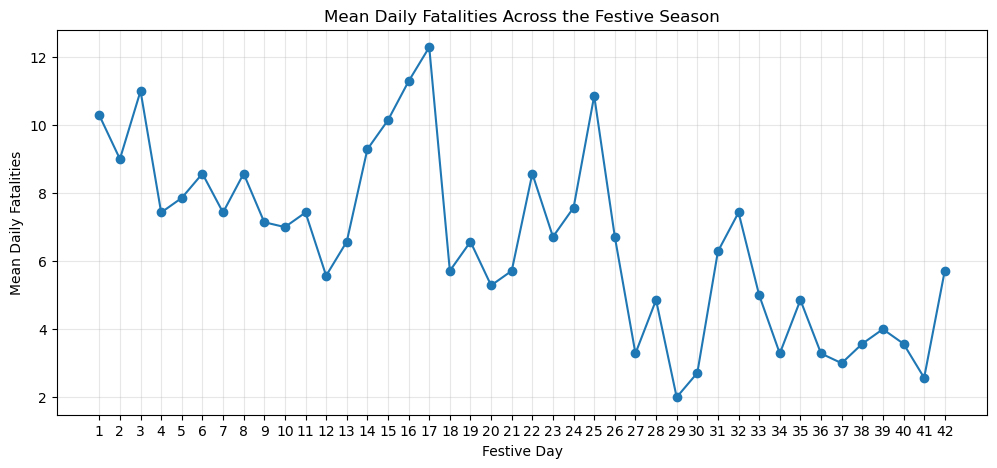

In [151]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    festive_day_summary["FESTIVE_DAY"],
    festive_day_summary["mean"],
    marker="o"
)

plt.xlabel("Festive Day")
plt.ylabel("Mean Daily Fatalities")
plt.title("Mean Daily Fatalities Across the Festive Season")

plt.xticks(range(1, 43))
plt.grid(True, alpha=0.3)

plt.show()

In [152]:
season_profile = season_daily.pivot(index="FESTIVE_DAY",columns="FESTIVE_SEASON_LABEL",values="DAILY_FATALITIES")
season_profile.head()

FESTIVE_SEASON_LABEL,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25
FESTIVE_DAY,,,,,,,
1,10.0,21.0,3.0,5.0,4.0,12.0,17.0
2,13.0,5.0,2.0,9.0,9.0,16.0,9.0
3,8.0,3.0,2.0,16.0,20.0,25.0,3.0
4,3.0,6.0,7.0,8.0,15.0,5.0,8.0
5,3.0,6.0,18.0,17.0,5.0,3.0,3.0


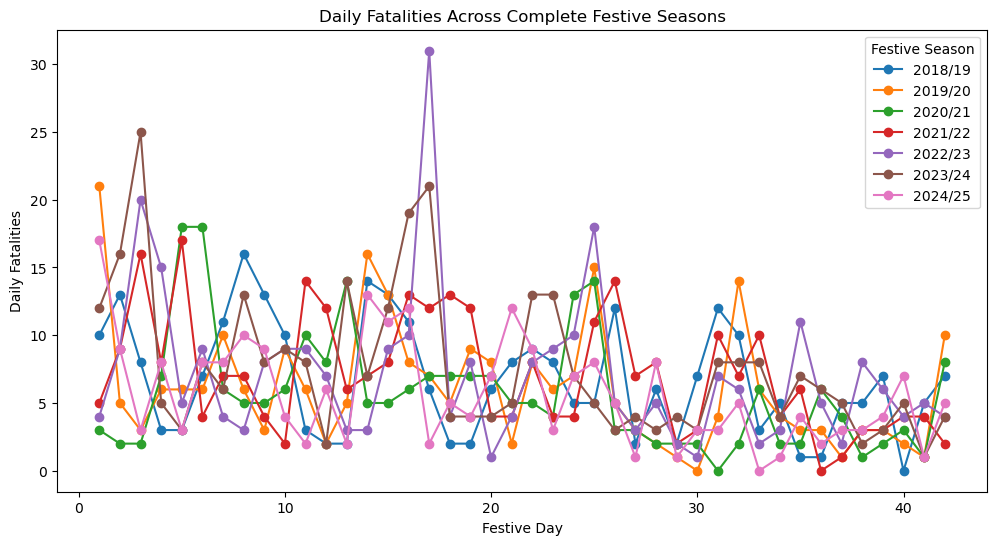

In [153]:
season_profile.plot(figsize=(12, 6),marker="o")

plt.xlabel("Festive Day")
plt.ylabel("Daily Fatalities")
plt.title("Daily Fatalities Across Complete Festive Seasons")
plt.legend(title="Festive Season")

plt.show()

## Temporal Pattern of Festive-Season Fatalities

A temporal analysis was conducted using daily fatality totals across the seven complete festive seasons from 2018/19 to 2024/25. Each festive season was represented using the 42-day period from 1 December to 11 January.

Across the 294 festive days, the mean number of daily fatalities was **6.57**, with a median of **5.50** and a standard deviation of **4.65**. The maximum number of fatalities recorded on a single day was **31**.

The average daily fatality profile showed considerable variation across the festive period. Mean daily fatalities were relatively high during the early part of the festive season and increased again during approximately Days 14–26. The highest average occurred on festive Day 17, with a mean of **12.29 fatalities** across the seven complete seasons. A decline was observed from approximately Day 27 onwards, with the lowest average occurring on Day 29 at **2.00 fatalities**.

However, the season-specific analysis demonstrated substantial variation between festive seasons. Peaks did not consistently occur on the same festive days across all seasons. For example, the maximum daily value of **31 fatalities** occurred during the 2022/23 festive season, demonstrating that individual high-fatality days can substantially influence the overall temporal pattern.

Therefore, the temporal analysis indicates variation in fatality levels throughout the festive period, but the observed patterns should not be interpreted as evidence that a particular festive day directly causes higher fatalities. The results instead demonstrate that fatality levels vary considerably both within and between festive seasons.

## Statistical Test of Festive-Day Differences

A Friedman test was conducted to assess whether daily fatality counts differed systematically across the 42 festive-day positions.

The test was selected because the analysis contains repeated observations from the same seven festive seasons, with each season contributing a fatality count for each festive-day position. The Friedman test provides a non-parametric alternative to repeated-measures ANOVA and does not require the daily fatality counts to follow a normal distribution.

The null hypothesis was that the distribution of daily fatalities was the same across the 42 festive-day positions.

The alternative hypothesis was that at least one festive-day position differed from the others.

A significance level of 0.05 was used.

In [154]:
from scipy.stats import friedmanchisquare

# Create a 7 seasons × 42 festive days matrix
friedman_data = season_daily.pivot(index="FESTIVE_SEASON_LABEL",columns="FESTIVE_DAY",values="DAILY_FATALITIES")
# Make sure the columns are in Day 1 → Day 42 order
friedman_data = friedman_data.sort_index(axis=1)
print("Shape:", friedman_data.shape)

Shape: (7, 42)


In [155]:
friedman_statistic, friedman_pvalue = friedmanchisquare(*[friedman_data[day]
        for day in friedman_data.columns
    ]
)

print("Friedman test statistic:", friedman_statistic)
print("Friedman p-value:", friedman_pvalue)

Friedman test statistic: 104.24325527453347
Friedman p-value: 2.0375093245627494e-07


## Interpretation of the Friedman Test

- The Friedman test produced a test statistic of **104.2433** and a p-value of **2.04 × 10⁻⁷**. Since the p-value was below the significance level of **0.05**, the null hypothesis was rejected.

- This provides statistical evidence that daily fatality counts differed across the 42 festive-day positions. The result supports the descriptive temporal analysis, which showed variation in daily fatality levels throughout the festive period.

- The Friedman test does not identify which specific festive-day positions differ from one another. Therefore, the significant result should be interpreted as evidence of an overall temporal difference rather than evidence that any particular festive day is inherently associated with higher fatalities.

- The substantial variation observed between individual festive seasons also indicates that the temporal pattern is not identical across seasons. Consequently, the results demonstrate temporal variation within the festive period while highlighting the importance of season-to-season variability.

In [156]:

# POST-HOC ANALYSIS AFTER FRIEDMAN TEST
# Wilcoxon signed-rank tests + Holm correction

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

# Ensure festive days are ordered correctly
friedman_data = season_daily.pivot(index="FESTIVE_SEASON_LABEL",columns="FESTIVE_DAY",values="DAILY_FATALITIES").sort_index(axis=1)

results = []

days = friedman_data.columns.tolist()

for i in range(len(days)):
    for j in range(i + 1, len(days)):

        day_1 = days[i]
        day_2 = days[j]

        x = friedman_data[day_1]
        y = friedman_data[day_2]

        # Remove paired observations with missing values
        valid = x.notna() & y.notna()
        x_valid = x[valid]
        y_valid = y[valid]

        # Wilcoxon signed-rank test
        try:
            statistic, p_value = wilcoxon( x_valid, y_valid,zero_method="wilcox",alternative="two-sided"
            )
        except ValueError:
            statistic = np.nan
            p_value = np.nan

        results.append({
            "Day_1": day_1,
            "Day_2": day_2,
            "Wilcoxon_statistic": statistic,
            "Raw_p_value": p_value
        })

posthoc_results = pd.DataFrame(results)

# Remove comparisons where the test could not be calculated
valid_results = posthoc_results["Raw_p_value"].notna()

# Holm multiple-comparison correction
reject, p_adjusted, _, _ = multipletests(posthoc_results.loc[valid_results, "Raw_p_value"],method="holm",alpha=0.05)

posthoc_results.loc[valid_results, "Holm_adjusted_p"] = p_adjusted
posthoc_results.loc[valid_results, "Significant"] = reject

# Sort by adjusted p-value
posthoc_results = posthoc_results.sort_values("Holm_adjusted_p").reset_index(drop=True)
posthoc_results.head(20)

,Day_1,Day_2,Wilcoxon_statistic,Raw_p_value,Holm_adjusted_p,Significant
0,1,2,14.0,1.000000,1.0,False
1,18,25,2.0,0.046875,1.0,False
2,18,26,6.0,0.812500,1.0,False
3,18,27,0.0,0.062500,1.0,False
4,18,28,10.0,0.593750,1.0,False
5,18,29,0.0,0.062500,1.0,False
6,18,30,5.0,0.156250,1.0,False
7,18,31,12.5,0.843750,1.0,False
8,18,32,7.0,0.562500,1.0,False
9,18,33,10.0,0.562500,1.0,False


In [157]:
significant_pairs = posthoc_results[posthoc_results["Significant"] == True].copy()
significant_pairs

,Day_1,Day_2,Wilcoxon_statistic,Raw_p_value,Holm_adjusted_p,Significant


In [158]:
print(f"Number of significant pairwise comparisons: "f"{len(significant_pairs)}")
print(f"Total valid pairwise comparisons: "f"{valid_results.sum()}")

Number of significant pairwise comparisons: 0
Total valid pairwise comparisons: 861


In [159]:
significant_pairs[ ["Day_1","Day_2","Wilcoxon_statistic","Raw_p_value","Holm_adjusted_p"]]

,Day_1,Day_2,Wilcoxon_statistic,Raw_p_value,Holm_adjusted_p


In [160]:
posthoc_results["Mean_Day_1"] = [
    friedman_data[row.Day_1].mean()
    for _, row in posthoc_results.iterrows()
]

posthoc_results["Mean_Day_2"] = [
    friedman_data[row.Day_2].mean()
    for _, row in posthoc_results.iterrows()
]

posthoc_results["Mean_Difference"] = (posthoc_results["Mean_Day_1"] - posthoc_results["Mean_Day_2"])
significant_pairs = posthoc_results[posthoc_results["Significant"] == True].copy()
significant_pairs[ ["Day_1","Day_2","Mean_Day_1","Mean_Day_2","Mean_Difference","Holm_adjusted_p"]]

,Day_1,Day_2,Mean_Day_1,Mean_Day_2,Mean_Difference,Holm_adjusted_p


- Following the significant Friedman test, pairwise Wilcoxon signed-rank tests were conducted to identify specific differences between festive-day positions. A Holm correction was applied to control for multiple comparisons across the 861 pairwise comparisons. 
- Although the omnibus Friedman test indicated statistically significant variation in daily fatality counts across the festive period (χ²(41) = 104.24, p < 0.001), none of the pairwise comparisons remained statistically significant following Holm adjustment.
- Therefore, the analysis provides evidence of an overall temporal pattern but does not support the conclusion that any specific festive day has significantly higher or lower fatality counts than another after accounting for multiple comparisons.

In [161]:

# FESTIVE-SEASON FATALITIES BY HOUR
# Seven complete festive seasons: 2018/19–2024/25


hourly_fatalities = (df_festive_complete.groupby("ACCIDENT_HOUR")["TOTAL_FATALITIES"].agg(
        Total_Fatalities="sum",
        Mean_Fatalities="mean",
        Median_Fatalities="median",
        Crash_Count="count"
    ).reset_index())

hourly_fatalities

,ACCIDENT_HOUR,Total_Fatalities,Mean_Fatalities,Median_Fatalities,Crash_Count
0,0,76.0,1.151515,1.0,66
1,1,66.0,1.081967,1.0,61
2,2,58.0,1.035714,1.0,56
3,3,63.0,1.067797,1.0,59
4,4,58.0,1.074074,1.0,54
5,5,65.0,1.083333,1.0,60
6,6,72.0,1.074627,1.0,67
7,7,70.0,1.076923,1.0,65
8,8,52.0,1.155556,1.0,45
9,9,42.0,1.076923,1.0,39


In [162]:
highest_hour = hourly_fatalities.loc[hourly_fatalities["Total_Fatalities"].idxmax()]
lowest_hour = hourly_fatalities.loc[hourly_fatalities["Total_Fatalities"].idxmin()]

print("Highest total fatalities:")
print(highest_hour)

print("\nLowest total fatalities:")
print(lowest_hour)

Highest total fatalities:
ACCIDENT_HOUR         20.000000
Total_Fatalities     183.000000
Mean_Fatalities        1.070175
Median_Fatalities      1.000000
Crash_Count          171.000000
Name: 20, dtype: float64

Lowest total fatalities:
ACCIDENT_HOUR        10.000000
Total_Fatalities     40.000000
Mean_Fatalities       1.052632
Median_Fatalities     1.000000
Crash_Count          38.000000
Name: 10, dtype: float64


In [163]:
hourly_fatalities.sort_values("Total_Fatalities",ascending=False)

,ACCIDENT_HOUR,Total_Fatalities,Mean_Fatalities,Median_Fatalities,Crash_Count
20,20,183.0,1.070175,1.0,171
21,21,137.0,1.070312,1.0,128
22,22,128.0,1.103448,1.0,116
19,19,125.0,1.068376,1.0,117
23,23,113.0,1.118812,1.0,101
17,17,90.0,1.097561,1.0,82
18,18,89.0,1.059524,1.0,84
16,16,88.0,1.047619,1.0,84
13,13,79.0,1.161765,1.0,68
14,14,78.0,1.164179,1.0,67


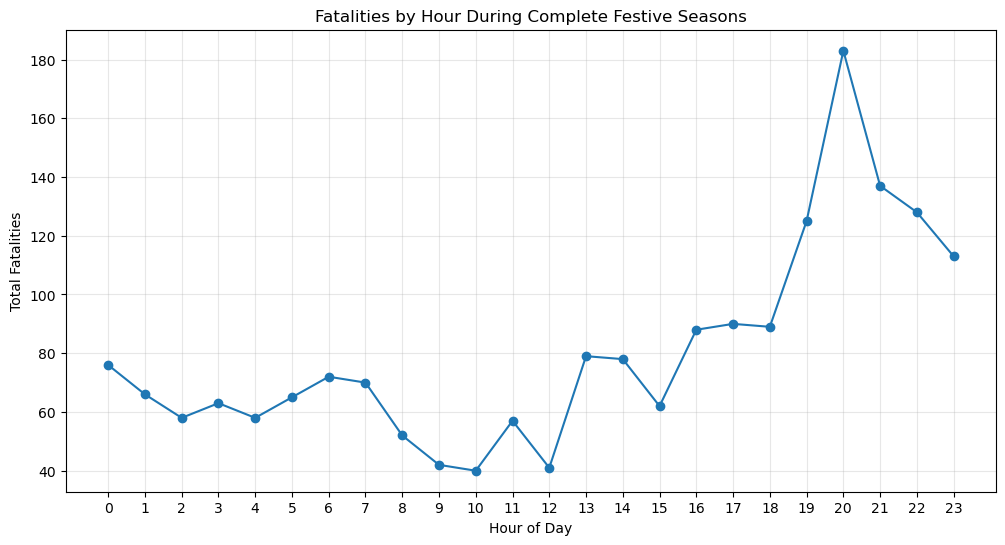

In [164]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(hourly_fatalities["ACCIDENT_HOUR"], hourly_fatalities["Total_Fatalities"], marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Total Fatalities")
plt.title("Fatalities by Hour During Complete Festive Seasons")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

In [165]:
from scipy.stats import kruskal

hour_groups = [
    group["TOTAL_FATALITIES"].values
    for _, group in df_festive_complete.groupby("ACCIDENT_HOUR")
]

kruskal_statistic, kruskal_pvalue = kruskal(*hour_groups)

print("Kruskal-Wallis statistic:", kruskal_statistic)
print("Kruskal-Wallis p-value:", kruskal_pvalue)

Kruskal-Wallis statistic: 19.525288346018822
Kruskal-Wallis p-value: 0.6703513466673263


## Statistical Analysis of Fatalities by Hour

A Kruskal–Wallis test was conducted to determine whether the distribution of fatalities per crash differed across the 24 hours of the day during the seven complete festive seasons.

The test did not identify a statistically significant difference in fatality distributions across hours, H(23) = 19.525, p = 0.670. Therefore, the null hypothesis that the distributions were equivalent across the hourly groups was not rejected.

Descriptively, 20:00 recorded the highest total number of fatalities (183), followed by 21:00 (137), 22:00 (128), 19:00 (125) and 23:00 (113). However, these hours also recorded relatively high numbers of crashes. The mean number of fatalities per crash remained close to one across the hourly groups.

Therefore, the higher number of fatalities observed during the evening period appears primarily to reflect the greater volume of crashes occurring during these hours rather than a statistically significant difference in fatalities per crash.

In [166]:
# COVID-19 sensitivity analysis
# Compare the temporal profile with 2020/21 included vs excluded

# Full seven-season dataset
temporal_with_covid = season_daily.copy()

# Exclude the 2020/21 festive season
temporal_without_covid = season_daily[
    season_daily["FESTIVE_SEASON_LABEL"] != "2020/21"
].copy()

# Compare overall daily statistics
covid_sensitivity_summary = pd.DataFrame({
    "Analysis": ["All seven complete seasons","Excluding 2020/21"],
    "Number_of_Seasons": [temporal_with_covid["FESTIVE_SEASON_LABEL"].nunique(),temporal_without_covid["FESTIVE_SEASON_LABEL"].nunique()],
    "Mean_Daily_Fatalities": [temporal_with_covid["DAILY_FATALITIES"].mean(),temporal_without_covid["DAILY_FATALITIES"].mean()],
    "Median_Daily_Fatalities": [temporal_with_covid["DAILY_FATALITIES"].median(),temporal_without_covid["DAILY_FATALITIES"].median()],
    "SD_Daily_Fatalities": [temporal_with_covid["DAILY_FATALITIES"].std(),temporal_without_covid["DAILY_FATALITIES"].std()],
    "Maximum_Daily_Fatalities": [temporal_with_covid["DAILY_FATALITIES"].max(),temporal_without_covid["DAILY_FATALITIES"].max()]})

covid_sensitivity_summary

,Analysis,Number_of_Seasons,Mean_Daily_Fatalities,Median_Daily_Fatalities,SD_Daily_Fatalities,Maximum_Daily_Fatalities
0,All seven complete seasons,7,6.571429,5.5,4.647286,31.0
1,Excluding 2020/21,6,6.722222,6.0,4.688953,31.0


In [167]:
festive_day_without_covid = (temporal_without_covid.groupby("FESTIVE_DAY")["DAILY_FATALITIES"]
    .agg(Mean="mean",Median="median",Minimum="min", Maximum="max").reset_index())

festive_day_without_covid.head(10)

,FESTIVE_DAY,Mean,Median,Minimum,Maximum
0,1,11.500000,11.0,4.0,21.0
1,2,10.166667,9.0,5.0,16.0
2,3,12.500000,12.0,3.0,25.0
3,4,7.500000,7.0,3.0,15.0
4,5,6.166667,4.0,3.0,17.0
5,6,7.000000,7.5,4.0,9.0
6,7,7.666667,7.5,4.0,11.0
7,8,9.166667,8.5,3.0,16.0
8,9,7.500000,8.0,3.0,13.0
9,10,7.166667,9.0,2.0,10.0


In [168]:
temporal_comparison = (season_daily.groupby("FESTIVE_DAY")["DAILY_FATALITIES"].mean().rename("Mean_With_COVID").to_frame())

temporal_comparison["Mean_Without_COVID"] = (temporal_without_covid.groupby("FESTIVE_DAY")["DAILY_FATALITIES"].mean())
temporal_comparison["Difference"] = (temporal_comparison["Mean_With_COVID"]- temporal_comparison["Mean_Without_COVID"])

temporal_comparison

,Mean_With_COVID,Mean_Without_COVID,Difference
FESTIVE_DAY,,,
1,10.285714,11.500000,-1.214286
2,9.000000,10.166667,-1.166667
3,11.000000,12.500000,-1.500000
4,7.428571,7.500000,-0.071429
5,7.857143,6.166667,1.690476
6,8.571429,7.000000,1.571429
7,7.428571,7.666667,-0.238095
8,8.571429,9.166667,-0.595238
9,7.142857,7.500000,-0.357143


In [169]:
from scipy.stats import friedmanchisquare

# Create 6-season festive-day matrix
friedman_without_covid = temporal_without_covid.pivot(index="FESTIVE_SEASON_LABEL",columns="FESTIVE_DAY",values="DAILY_FATALITIES")
friedman_without_covid = friedman_without_covid.sort_index(axis=1)

# Friedman test without 2020/21
friedman_stat_without_covid, friedman_p_without_covid = friedmanchisquare(*[friedman_without_covid[day]
      for day in friedman_without_covid.columns]
)

print("Friedman statistic:", friedman_stat_without_covid)
print("p-value:", friedman_p_without_covid)

Friedman statistic: 102.05658728424734
p-value: 4.0692497740798416e-07


In [170]:
friedman_sensitivity = pd.DataFrame({
    "Analysis": ["All seven complete seasons","Excluding 2020/21"],
    "Seasons": [7,6],
    "Friedman_Statistic": [friedman_statistic,friedman_stat_without_covid],
    "p_value": [friedman_pvalue,friedman_p_without_covid]})

friedman_sensitivity

,Analysis,Seasons,Friedman_Statistic,p_value
0,All seven complete seasons,7,104.243255,2.037509e-07
1,Excluding 2020/21,6,102.056587,4.069250e-07


## COVID-19 Sensitivity Analysis

Because the 2020/21 festive season occurred during the COVID-19 pandemic and may have been affected by unusual travel and mobility patterns, a sensitivity analysis was conducted to determine whether its inclusion materially influenced the observed temporal patterns.

The descriptive results were broadly consistent after excluding the 2020/21 festive season. The mean daily fatality count changed from 6.57 across all seven complete seasons to 6.72 when 2020/21 was excluded, while the standard deviation remained similar (4.65 compared with 4.69). The maximum daily fatality count remained 31 in both analyses.

The Friedman test was also repeated after excluding the 2020/21 season. The original analysis produced a statistically significant result, χ²(41) = 104.24, p < 0.001. After excluding 2020/21, the test remained statistically significant, χ²(41) = 102.06, p < 0.001.

These results indicate that the evidence of variation in daily fatality counts across festive-day positions was not dependent on the inclusion of the 2020/21 festive season. Therefore, the temporal findings appear reasonably robust to the potential influence of the COVID-19 period.

Because season_daily already has the 42-day position, we need to attach that information to each crash in df_festive_complete.

In [171]:
#Add FESTIVE_DAY
# Create the date-to-festive-day mapping
festive_day_map = season_daily[["FESTIVE_SEASON_LABEL", "ACCIDENT_DATE", "FESTIVE_DAY"]].copy()

# Add FESTIVE_DAY to the crash-level modelling data
df_festive_complete = df_festive_complete.drop(columns=["FESTIVE_DAY"],errors="ignore")

df_festive_complete = df_festive_complete.merge(festive_day_map,on=["FESTIVE_SEASON_LABEL", "ACCIDENT_DATE"],how="left")

print("Missing FESTIVE_DAY:", df_festive_complete["FESTIVE_DAY"].isna().sum())
print("FESTIVE_DAY range:",df_festive_complete["FESTIVE_DAY"].min(),"to",df_festive_complete["FESTIVE_DAY"].max())

Missing FESTIVE_DAY: 0
FESTIVE_DAY range: 1 to 42


In [172]:
df_festive_complete[ [ "ACCIDENT_DATE","FESTIVE_SEASON_LABEL","FESTIVE_DAY"]].head(15)

,ACCIDENT_DATE,FESTIVE_SEASON_LABEL,FESTIVE_DAY
0,2022-01-04,2021/22,35
1,2021-12-16,2021/22,16
2,2023-12-27,2023/24,27
3,2023-12-01,2023/24,1
4,2022-12-03,2022/23,3
5,2018-12-05,2018/19,5
6,2023-01-03,2022/23,34
7,2020-12-05,2020/21,5
8,2020-01-06,2019/20,37
9,2020-12-06,2020/21,6


In [173]:
train_data = df_festive_complete[df_festive_complete["FESTIVE_SEASON_LABEL"].isin(train_seasons)].copy()

test_data = df_festive_complete[df_festive_complete["FESTIVE_SEASON_LABEL"].isin(test_seasons)].copy()

X_train = train_data[predictor_columns].copy()
y_train = train_data["TOTAL_FATALITIES"].copy()

X_test = test_data[predictor_columns].copy()
y_test = test_data["TOTAL_FATALITIES"].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (1256, 7)
y_train: (1256,)
X_test : (526, 7)
y_test : (526,)


In [174]:
# Define the final predictors FIRST
predictor_columns = [
    "DISTRICT",
    "CRASH_TYPE_DESC",
    "TOTAL_VEHICLE_INVOLVED_CLEAN",
    "ROAD_CATEGORY",
    "ACCIDENT_HOUR",
    "DAY_OF_WEEK",
    "FESTIVE_DAY",
    "FESTIVE_SEASON_YEAR"
]

target_column = "TOTAL_FATALITIES"


# Create training and testing datasets
train_data = df_festive_complete[
    df_festive_complete["FESTIVE_SEASON_LABEL"].isin(train_seasons)
].copy()

test_data = df_festive_complete[
    df_festive_complete["FESTIVE_SEASON_LABEL"].isin(test_seasons)
].copy()


# Create X and y
X_train = train_data[predictor_columns].copy()
y_train = train_data[target_column].copy()

X_test = test_data[predictor_columns].copy()
y_test = test_data[target_column].copy()


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (1256, 8)
y_train: (1256,)
X_test : (526, 8)
y_test : (526,)


In [175]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "DISTRICT",
    "CRASH_TYPE_DESC",
    "ROAD_CATEGORY",
    "DAY_OF_WEEK",
    "FESTIVE_SEASON_YEAR"
]

numeric_features = [
    "TOTAL_VEHICLE_INVOLVED_CLEAN",
    "ACCIDENT_HOUR",
    "FESTIVE_DAY"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)

X_train_processed: (1256, 41)
X_test_processed : (526, 41)


In [176]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print("\nFeatures:")
for i, feature in enumerate(feature_names, start=1):
    print(i, feature)

Number of features: 41

Features:
1 categorical__DISTRICT_City of Johannesburg
2 categorical__DISTRICT_City of Tshwane
3 categorical__DISTRICT_Ekurhuleni
4 categorical__DISTRICT_Sedibeng
5 categorical__DISTRICT_West Rand
6 categorical__CRASH_TYPE_DESC_Accident with Pedal Cyclist
7 categorical__CRASH_TYPE_DESC_Accident with fixed/other object
8 categorical__CRASH_TYPE_DESC_Accident with pedestrian
9 categorical__CRASH_TYPE_DESC_Approach at angle (both trav. straight)
10 categorical__CRASH_TYPE_DESC_Approach at angle,  One or both turning
11 categorical__CRASH_TYPE_DESC_Head on
12 categorical__CRASH_TYPE_DESC_Head/rear end
13 categorical__CRASH_TYPE_DESC_Hit and Run
14 categorical__CRASH_TYPE_DESC_Person fell off
15 categorical__CRASH_TYPE_DESC_Sideswipe (opposite directions)
16 categorical__CRASH_TYPE_DESC_Sideswipe (same direction)
17 categorical__CRASH_TYPE_DESC_Single vehicle (left the road)
18 categorical__CRASH_TYPE_DESC_Single vehicle (overturned)
19 categorical__CRASH_TYPE_DESC_T

In [177]:
#Tuning Random Forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf_param_grid = { "n_estimators": [100, 300, 500], "max_depth": [None, 5, 10, 20], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 1.0]
}

rf_grid_search = GridSearchCV(estimator=RandomForestRegressor( random_state=42, n_jobs=-1 ),param_grid=rf_param_grid,  scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [None, 5, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [178]:
print("Best parameters:")
print(rf_grid_search.best_params_)

print("\nBest CV RMSE:")
print(-rf_grid_search.best_score_)

Best parameters:
{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}

Best CV RMSE:
0.3429840305266376


In [179]:
tuned_rf_model = rf_grid_search.best_estimator_

tuned_rf_predictions = tuned_rf_model.predict(X_test_processed)
tuned_rf_rmse = np.sqrt(mean_squared_error(y_test, tuned_rf_predictions))
tuned_rf_mae = mean_absolute_error(y_test, tuned_rf_predictions)
tuned_rf_r2 = r2_score( y_test, tuned_rf_predictions)

print("Tuned Random Forest Results")
print("RMSE:", tuned_rf_rmse)
print("MAE :", tuned_rf_mae)
print("R²  :", tuned_rf_r2)

Tuned Random Forest Results
RMSE: 0.33133908585748106
MAE : 0.13035221285874762
R²  : 0.08235286401701902


In [180]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

ada_model = AdaBoostRegressor(estimator=DecisionTreeRegressor(random_state=42),random_state=42)
ada_param_grid = {"n_estimators": [50, 100, 200],"learning_rate": [0.01, 0.05, 0.1],"loss": ["linear", "square", "exponential"],"estimator__max_depth": [1, 2, 3],
    "estimator__min_samples_leaf": [1, 2, 4]}
ada_grid_search = GridSearchCV(estimator=ada_model,param_grid=ada_param_grid,scoring="neg_root_mean_squared_error",cv=5,n_jobs=-1,verbose=1)
ada_grid_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


,estimator,AdaBoostRegre...ndom_state=42)
,param_grid,"{'estimator__max_depth': [1, 2, ...], 'estimator__min_samples_leaf': [1, 2, ...], 'learning_rate': [0.01, 0.05, ...], 'loss': ['linear', 'square', ...], ...}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [181]:
print("Best parameters:")
print(ada_grid_search.best_params_)

print("\nBest CV RMSE:")
print(-ada_grid_search.best_score_)

Best parameters:
{'estimator__max_depth': 2, 'estimator__min_samples_leaf': 4, 'learning_rate': 0.01, 'loss': 'square', 'n_estimators': 100}

Best CV RMSE:
0.34344948422557237


In [182]:
tuned_ada_model = ada_grid_search.best_estimator_

tuned_ada_predictions = tuned_ada_model.predict(X_test_processed)
tuned_ada_rmse = np.sqrt( mean_squared_error(y_test, tuned_ada_predictions))
tuned_ada_mae = mean_absolute_error(y_test,tuned_ada_predictions)
tuned_ada_r2 = r2_score(y_test,tuned_ada_predictions)

print("Tuned AdaBoost Results")
print("RMSE:", tuned_ada_rmse)
print("MAE :", tuned_ada_mae)
print("R²  :", tuned_ada_r2)

Tuned AdaBoost Results
RMSE: 0.3372149460474752
MAE : 0.15538924202035892
R²  : 0.0495177642656236


ANN / MLP

For the neural network using MLPRegressor. Because neural networks are sensitive to feature scale,  standardise the 41 processed features using the training data only.

In [183]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Convert sparse matrices to dense arrays
X_train_dense = X_train_processed.toarray()
X_test_dense = X_test_processed.toarray()

# Standardise using training data only
mlp_scaler = StandardScaler()

X_train_mlp = mlp_scaler.fit_transform(X_train_dense)
X_test_mlp = mlp_scaler.transform(X_test_dense)

print("X_train_mlp:", X_train_mlp.shape)
print("X_test_mlp :", X_test_mlp.shape)

X_train_mlp: (1256, 41)
X_test_mlp : (526, 41)


In [184]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(random_state=42,max_iter=1000,early_stopping=True,validation_fraction=0.1,n_iter_no_change=20))])

mlp_param_grid = {"mlp__hidden_layer_sizes": [(20,),(50,),(100,),(50, 25) ],"mlp__learning_rate_init": [0.001,0.01],"mlp__alpha": [0.0001,0.001,0.01 ]}

mlp_grid_search = GridSearchCV(estimator=mlp_pipeline,param_grid=mlp_param_grid,scoring="neg_root_mean_squared_error",cv=5,n_jobs=-1,verbose=1)
mlp_grid_search.fit(X_train_dense, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'mlp__alpha': [0.0001, 0.001, ...], 'mlp__hidden_layer_sizes': [(20,), (50,), ...], 'mlp__learning_rate_init': [0.001, 0.01]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [185]:
print("Best parameters:")
print(mlp_grid_search.best_params_)

print("\nBest CV RMSE:")
print(-mlp_grid_search.best_score_)

Best parameters:
{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (100,), 'mlp__learning_rate_init': 0.01}

Best CV RMSE:
0.3921597251187564


In [186]:
tuned_mlp_model = mlp_grid_search.best_estimator_

tuned_mlp_predictions = tuned_mlp_model.predict(X_test_dense)
tuned_mlp_rmse = np.sqrt(mean_squared_error(y_test, tuned_mlp_predictions))
tuned_mlp_mae = mean_absolute_error(y_test,tuned_mlp_predictions)
tuned_mlp_r2 = r2_score(y_test,tuned_mlp_predictions)

print("Tuned ANN/MLP Results")
print("RMSE:", tuned_mlp_rmse)
print("MAE :", tuned_mlp_mae)
print("R²  :", tuned_mlp_r2)

Tuned ANN/MLP Results
RMSE: 0.39348670172782735
MAE : 0.20662470587393145
R²  : -0.29416751127739227


In [187]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

gb_model = GradientBoostingRegressor(random_state=42)
gb_param_grid = {"n_estimators": [100, 200, 300, 500],"learning_rate": [0.01, 0.05, 0.1],"max_depth": [2, 3, 4]}
gb_grid_search = GridSearchCV(estimator=gb_model,param_grid=gb_param_grid,scoring="neg_root_mean_squared_error",cv=5,n_jobs=-1,verbose=1)
gb_grid_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [188]:
print("Best parameters:")
print(gb_grid_search.best_params_)

print("\nBest CV RMSE:")
print(-gb_grid_search.best_score_)

Best parameters:
{'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200}

Best CV RMSE:
0.34917768702769003


In [189]:
tuned_gb_model = gb_grid_search.best_estimator_

tuned_gb_predictions = tuned_gb_model.predict(X_test_processed)
tuned_gb_rmse = np.sqrt(mean_squared_error(y_test, tuned_gb_predictions))
tuned_gb_mae = mean_absolute_error(y_test,tuned_gb_predictions)

tuned_gb_r2 = r2_score( y_test,tuned_gb_predictions)

print("Tuned Gradient Boosting Results")
print("RMSE:", tuned_gb_rmse)
print("MAE :", tuned_gb_mae)
print("R²  :", tuned_gb_r2)

Tuned Gradient Boosting Results
RMSE: 0.3412854572971337
MAE : 0.13602671645420997
R²  : 0.026432787405611946


In [190]:
#xg boost
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb_model = XGBRegressor(objective="reg:squarederror",random_state=42,n_jobs=-1)
xgb_param_grid = {"n_estimators": [100, 200, 300, 500],"learning_rate": [0.01, 0.05, 0.1],"max_depth": [2, 3, 4],"min_child_weight": [1, 3, 5]}
xgb_grid_search = GridSearchCV(estimator=xgb_model,param_grid=xgb_param_grid,scoring="neg_root_mean_squared_error",cv=5,n_jobs=-1, verbose=1)
xgb_grid_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'min_child_weight': [1, 3, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [191]:
tuned_xgb_model = xgb_grid_search.best_estimator_

tuned_xgb_predictions = tuned_xgb_model.predict(X_test_processed)
tuned_xgb_rmse = np.sqrt(mean_squared_error(y_test, tuned_xgb_predictions))
tuned_xgb_mae = mean_absolute_error(y_test,tuned_xgb_predictions)
tuned_xgb_r2 = r2_score(y_test,tuned_xgb_predictions)

print("Tuned XGBoost Results")
print("RMSE:", tuned_xgb_rmse)
print("MAE :", tuned_xgb_mae)
print("R²  :", tuned_xgb_r2)

Tuned XGBoost Results
RMSE: 0.3346930778342437
MAE : 0.13216273140997942
R²  : 0.06368100343987726


In [192]:
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

svr_pipeline = Pipeline([("scaler", StandardScaler()),("svr", SVR(kernel="rbf"))])
svr_param_grid = {"svr__C": [0.1, 1, 10, 100],"svr__epsilon": [0.01, 0.05, 0.1, 0.2],"svr__gamma": ["scale", "auto", 0.01, 0.1, 1]}
svr_grid_search = GridSearchCV(estimator=svr_pipeline,param_grid=svr_param_grid,scoring="neg_root_mean_squared_error",cv=5, n_jobs=-1,verbose=1)
svr_grid_search.fit(X_train_dense, y_train)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


,estimator,"Pipeline(step...svr', SVR())])"
,param_grid,"{'svr__C': [0.1, 1, ...], 'svr__epsilon': [0.01, 0.05, ...], 'svr__gamma': ['scale', 'auto', ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [193]:
print("Best parameters:")
print(svr_grid_search.best_params_)

print("\nBest CV RMSE:")
print(-svr_grid_search.best_score_)

Best parameters:
{'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma': 0.01}

Best CV RMSE:
0.35212633412124067


In [194]:
tuned_svr_model = svr_grid_search.best_estimator_

tuned_svr_predictions = tuned_svr_model.predict(X_test_dense)
tuned_svr_rmse = np.sqrt(mean_squared_error(y_test, tuned_svr_predictions))
tuned_svr_mae = mean_absolute_error(y_test,tuned_svr_predictions)
tuned_svr_r2 = r2_score(y_test,tuned_svr_predictions)

print("Tuned SVR Results")
print("RMSE:", tuned_svr_rmse)
print("MAE :", tuned_svr_mae)
print("R²  :", tuned_svr_r2)

Tuned SVR Results
RMSE: 0.34476721616691774
MAE : 0.12273957122968568
R²  : 0.006466996171040518


In [195]:
[x for x in globals() if "rf" in x.lower()]

['rf_model',
 'rf_predictions',
 'rf_rmse',
 'rf_mae',
 'rf_r2',
 'rf_results',
 'rf_model_no_year',
 'rf_predictions_no_year',
 'rf_no_year_rmse',
 'rf_no_year_mae',
 'rf_no_year_r2',
 'rf_param_grid',
 'rf_grid_search',
 'tuned_rf_model',
 'tuned_rf_predictions',
 'tuned_rf_rmse',
 'tuned_rf_mae',
 'tuned_rf_r2']

In [196]:
tuned_rf_predictions = tuned_rf_model.predict(X_test_processed)

In [197]:
tuned_rf_predictions[:10]

array([1.13064206, 1.11889422, 1.03034952, 1.08703111, 1.02762086,
       1.21390008, 1.09582045, 1.07677749, 1.07737144, 1.05306682])

In [198]:
prediction_check = pd.DataFrame({ "ACTUAL": y_test.values, "PREDICTED": tuned_rf_predictions})
prediction_check.head(20)

,ACTUAL,PREDICTED
0,1.0,1.130642
1,1.0,1.118894
2,1.0,1.030350
3,1.0,1.087031
4,1.0,1.027621
5,1.0,1.213900
6,1.0,1.095820
7,1.0,1.076777
8,1.0,1.077371
9,1.0,1.053067


In [199]:
#Is the Random Forest actually learning to predict higher-fatality crashes, or is it mostly predicting around 1 because 1 dominates the dataset?

prediction_check[prediction_check["ACTUAL"] > 1].sort_values("ACTUAL")

,ACTUAL,PREDICTED
23,2.0,1.160157
425,2.0,1.092705
421,2.0,1.108426
308,2.0,1.241539
248,2.0,1.128894
233,2.0,1.067497
221,2.0,1.255813
217,2.0,1.091575
181,2.0,1.294592
216,2.0,1.225599


In [200]:
severity_diagnostics = (
    prediction_check
    .assign(
        ABS_ERROR=lambda x: abs(x["ACTUAL"] - x["PREDICTED"]))
    .groupby("ACTUAL")
    .agg(N=("PREDICTED", "count"),MEAN_PREDICTED=("PREDICTED", "mean"),MAE=("ABS_ERROR", "mean") ) .reset_index())

severity_diagnostics

,ACTUAL,N,MEAN_PREDICTED,MAE
0,1.0,502,1.079156,0.079718
1,2.0,19,1.149964,0.850036
2,3.0,3,1.328613,1.671387
3,4.0,1,1.239593,2.760407
4,6.0,1,1.378400,4.621600


The Random Forest performed well for the dominant one-fatality crash category but substantially underestimated rare higher-fatality crashes. This indicates that overall RMSE alone does not fully capture the model's behaviour across different fatality levels.

what the Random Forest actually learned to pay attention to.

## Feature Importance Analysis

Feature importance was examined for the final Random Forest model to identify which predictor variables contributed most to the model's predictions of road traffic fatalities.

The Random Forest calculates an importance value for each feature based on its contribution to reducing prediction error across the decision trees. Because categorical variables were transformed using one-hot encoding during preprocessing, individual categories initially received separate importance values.

To improve interpretability, the importance values of the encoded categories will be aggregated back to their original predictor variables. For example, the importance values of the individual `CRASH_TYPE_DESC` categories will be combined to represent the overall contribution of crash type.

The resulting predictor-level importance values will be used to identify which variables the Random Forest relied on most when making its predictions.

Feature importance represents the contribution of a predictor to the model's predictive process and should not be interpreted as evidence of causation. A higher importance value indicates that the predictor contributed more to the Random Forest's prediction process, but it does not establish that the predictor directly causes road traffic fatalities.

In [201]:
rf_importance = tuned_rf_model.feature_importances_

feature_names = preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({"FEATURE": feature_names,"IMPORTANCE": rf_importance})
importance_df.sort_values( "IMPORTANCE",ascending=False).head(20)

,FEATURE,IMPORTANCE
40,numeric__FESTIVE_DAY,0.126011
39,numeric__ACCIDENT_HOUR,0.117537
10,categorical__CRASH_TYPE_DESC_Head on,0.117046
38,numeric__TOTAL_VEHICLE_INVOLVED_CLEAN,0.083668
7,categorical__CRASH_TYPE_DESC_Accident with ped...,0.040835
22,categorical__ROAD_CATEGORY_N Route,0.037972
17,categorical__CRASH_TYPE_DESC_Single vehicle (o...,0.037236
30,categorical__DAY_OF_WEEK_Thursday,0.037105
1,categorical__DISTRICT_City of Tshwane,0.035560
12,categorical__CRASH_TYPE_DESC_Hit and Run,0.031552


In [202]:
# Create predictor-level labels
def get_original_predictor(feature):
    feature = feature.replace("categorical__", "").replace("numeric__", "")

    if feature.startswith("DISTRICT_"):
        return "DISTRICT"
    elif feature.startswith("CRASH_TYPE_DESC_"):
        return "CRASH_TYPE_DESC"
    elif feature.startswith("ROAD_CATEGORY_"):
        return "ROAD_CATEGORY"
    elif feature.startswith("DAY_OF_WEEK_"):
        return "DAY_OF_WEEK"
    elif feature.startswith("FESTIVE_SEASON_YEAR_"):
        return "FESTIVE_SEASON_YEAR"
    elif feature == "TOTAL_VEHICLE_INVOLVED_CLEAN":
        return "TOTAL_VEHICLE_INVOLVED_CLEAN"
    elif feature == "ACCIDENT_HOUR":
        return "ACCIDENT_HOUR"
    elif feature == "FESTIVE_DAY":
        return "FESTIVE_DAY"
    else:
        return "OTHER"


importance_df["PREDICTOR"] = (importance_df["FEATURE"].apply(get_original_predictor))
importance_by_predictor = (importance_df.groupby("PREDICTOR", as_index=False)["IMPORTANCE"].sum().sort_values("IMPORTANCE", ascending=False))
importance_by_predictor

,PREDICTOR,IMPORTANCE
1,CRASH_TYPE_DESC,0.282865
4,FESTIVE_DAY,0.126011
2,DAY_OF_WEEK,0.121970
0,ACCIDENT_HOUR,0.117537
6,ROAD_CATEGORY,0.096998
3,DISTRICT,0.085515
5,FESTIVE_SEASON_YEAR,0.085435
7,TOTAL_VEHICLE_INVOLVED_CLEAN,0.083668


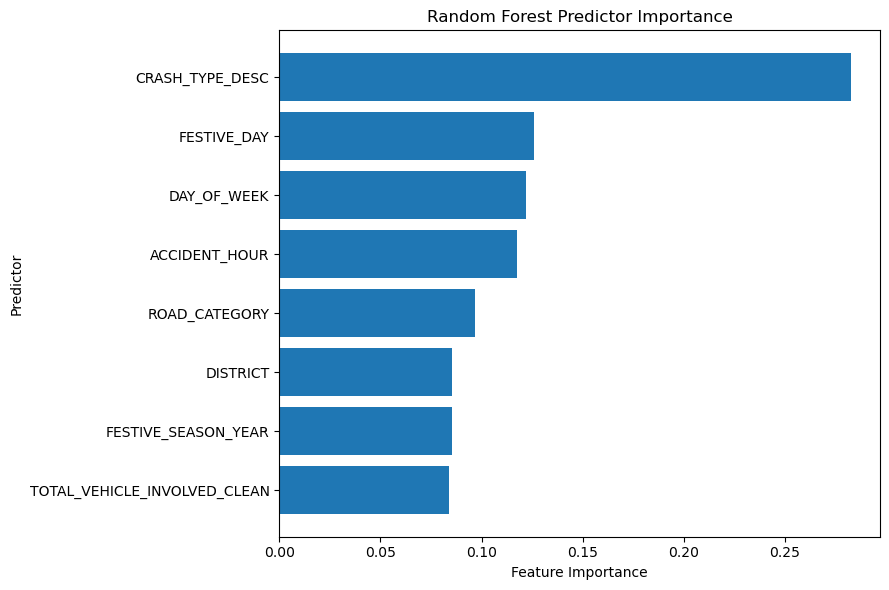

In [203]:
import matplotlib.pyplot as plt

importance_plot = importance_by_predictor.sort_values("IMPORTANCE", ascending=True)

plt.figure(figsize=(9, 6))

plt.barh( importance_plot["PREDICTOR"], importance_plot["IMPORTANCE"])

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")
plt.title("Random Forest Predictor Importance")

plt.tight_layout()
plt.show()

## Random Forest Feature Importance

Feature importance was examined for the final Random Forest model to determine which predictor variables contributed most to the model's predictive process.

Because categorical variables were transformed using one-hot encoding, the importance values of individual encoded categories were aggregated back to their original predictor variables. This produced an overall importance value for each predictor included in the model.

The results showed that `CRASH_TYPE_DESC` had the highest overall feature importance (0.283). The temporal variables `FESTIVE_DAY` (0.126), `DAY_OF_WEEK` (0.122), and `ACCIDENT_HOUR` (0.118) followed. `ROAD_CATEGORY` (0.097), `DISTRICT` (0.086), `FESTIVE_SEASON_YEAR` (0.085), and `TOTAL_VEHICLE_INVOLVED_CLEAN` (0.084) also contributed to the model's predictions.

These results indicate that the Random Forest relied substantially on both crash characteristics and temporal information when predicting fatalities during the festive season.

Feature importance represents the contribution of a predictor to the Random Forest's predictive process and should not be interpreted as a causal effect. A higher importance value indicates greater contribution to the model's decision-making process, but it does not mean that the predictor causes a corresponding proportion of road traffic fatalities.

The feature-importance results are therefore interpreted as indicators of which predictors the model relied on most, rather than as evidence of causal relationships.

Next: COVID-19 sensitivity analysis

In [204]:
# Exclude the 2020/21 festive season from the training data
train_data_no_covid = train_data[train_data["FESTIVE_SEASON_LABEL"] != "2020/21"].copy()

test_data_no_covid = test_data.copy()

print("Training shape:", train_data_no_covid.shape)
print("Testing shape:", test_data_no_covid.shape)
print("Training seasons:")
print(train_data_no_covid["FESTIVE_SEASON_LABEL"].value_counts().sort_index())
print("\nTesting seasons:")
print(test_data_no_covid["FESTIVE_SEASON_LABEL"].value_counts().sort_index())

Training shape: (1036, 42)
Testing shape: (526, 42)
Training seasons:
FESTIVE_SEASON_LABEL
2018/19    256
2019/20    233
2021/22    268
2022/23    279
Name: count, dtype: int64

Testing seasons:
FESTIVE_SEASON_LABEL
2023/24    297
2024/25    229
Name: count, dtype: int64


In [205]:
X_train_no_covid = train_data_no_covid[predictor_columns]
y_train_no_covid = train_data_no_covid[target_column]

X_test_no_covid = test_data_no_covid[predictor_columns]
y_test_no_covid = test_data_no_covid[target_column]

print("X_train:", X_train_no_covid.shape)
print("y_train:", y_train_no_covid.shape)
print("X_test:", X_test_no_covid.shape)
print("y_test:", y_test_no_covid.shape)

X_train: (1036, 8)
y_train: (1036,)
X_test: (526, 8)
y_test: (526,)


In [206]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor_no_covid = ColumnTransformer(
    transformers=[
        ( "categorical", OneHotEncoder(handle_unknown="ignore"),   categorical_features),
        ( "numeric", "passthrough", numeric_features ) ])

X_train_no_covid_processed = preprocessor_no_covid.fit_transform( X_train_no_covid)

X_test_no_covid_processed = preprocessor_no_covid.transform(  X_test_no_covid)

print("Processed training shape:", X_train_no_covid_processed.shape)
print("Processed testing shape:", X_test_no_covid_processed.shape)

Processed training shape: (1036, 39)
Processed testing shape: (526, 39)


In [207]:
from sklearn.ensemble import RandomForestRegressor

rf_no_covid = RandomForestRegressor( n_estimators=100, max_depth=20,  max_features="log2",    min_samples_leaf=4,  min_samples_split=10,  random_state=42)

rf_no_covid.fit( X_train_no_covid_processed,   y_train_no_covid)

,n_estimators,100
,criterion,'squared_error'
,max_depth,20
,min_samples_split,10
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [208]:
rf_no_covid_predictions = rf_no_covid.predict(  X_test_no_covid_processed)

In [209]:
from sklearn.metrics import (   mean_squared_error,  mean_absolute_error,  r2_score)
import numpy as np

rf_no_covid_rmse = np.sqrt(  mean_squared_error(y_test_no_covid,rf_no_covid_predictions ))

rf_no_covid_mae = mean_absolute_error(y_test_no_covid,rf_no_covid_predictions)

rf_no_covid_r2 = r2_score(y_test_no_covid, rf_no_covid_predictions)

print("COVID-excluded Random Forest")
print("RMSE:", rf_no_covid_rmse)
print("MAE:", rf_no_covid_mae)
print("R²:", rf_no_covid_r2)

COVID-excluded Random Forest
RMSE: 0.33393350083841283
MAE: 0.13448801221451098
R²: 0.06792608280164691


## COVID-19 Sensitivity Analysis

A sensitivity analysis was conducted to assess whether the inclusion of the 2020/21 festive season, which occurred during the COVID-19 pandemic, materially influenced the predictive performance of the Random Forest model.

The primary Random Forest model, trained using all seven complete festive seasons, achieved a test RMSE of 0.3313, MAE of 0.1304 and R² of 0.0824. When the 2020/21 festive season was excluded from the training data, while keeping the same 2023/24 and 2024/25 test set and model hyperparameters, the model achieved an RMSE of 0.3339, MAE of 0.1345 and R² of 0.0679.

The exclusion of the COVID-19 season resulted in a small increase in RMSE and MAE and a decrease in R². However, the RMSE increased by only approximately 0.78%, while the model continued to outperform the baseline RMSE of 0.3472.

These results indicate that excluding the COVID-19 festive season did not materially alter the Random Forest's predictive performance. Therefore, the model's predictive results appear reasonably robust to the potential influence of the unusual conditions associated with the 2020/21 festive season.

In [210]:
import pandas as pd

model_results = pd.DataFrame([
    ["Random Forest", 0.33133908585748106, 0.13035221285874762, 0.08235286401701902],
    ["XGBoost", 0.33469, 0.13216, 0.06368],
    ["AdaBoost", 0.3372149460474752, 0.15538924202035892, 0.0495177642656236],
    ["Gradient Boosting", 0.34129, 0.13803, 0.02643],
    ["SVR", 0.34476721616691774, 0.12273957122968568, 0.006466996171040518],
    ["ANN/MLP", 0.39348, 0.20662, -0.29418],
    ["Baseline", 0.3472221457792889, 0.14738986704124382, -0.007732366004700175]
], columns=["MODEL", "RMSE", "MAE", "R2"])

baseline_rmse = model_results.loc[model_results["MODEL"] == "Baseline", "RMSE"].iloc[0]

model_results["RMSE_IMPROVEMENT_%"] = ( (baseline_rmse - model_results["RMSE"]) / baseline_rmse) * 100

model_results = model_results.sort_values( "RMSE").reset_index(drop=True)
model_results

,MODEL,RMSE,MAE,R2,RMSE_IMPROVEMENT_%
0,Random Forest,0.331339,0.130352,0.082353,4.574322
1,XGBoost,0.334690,0.132160,0.063680,3.609259
2,AdaBoost,0.337215,0.155389,0.049518,2.882074
3,Gradient Boosting,0.341290,0.138030,0.026430,1.708458
4,SVR,0.344767,0.122740,0.006467,0.707020
5,Baseline,0.347222,0.147390,-0.007732,0.000000
6,ANN/MLP,0.393480,0.206620,-0.294180,-13.322265


## Comparison of Machine Learning Models

The predictive performance of the evaluated machine learning models was compared using RMSE, MAE and R² on the held-out test set. RMSE was used as the primary evaluation metric in accordance with the research objective of identifying the model with the lowest prediction error.

The Random Forest model achieved the lowest test RMSE of 0.3313, followed by XGBoost (0.3347), AdaBoost (0.3372), Gradient Boosting (0.3413), and SVR (0.3448). The baseline model produced an RMSE of 0.3472. The Random Forest therefore reduced RMSE by approximately 4.57% relative to the baseline.

The Random Forest also achieved the highest R² value among the evaluated models (0.0824), followed by XGBoost (0.0637) and AdaBoost (0.0495). Although these R² values are relatively low, they indicate that the tree-based ensemble models provided some predictive improvement over the baseline on the unseen test data.

SVR produced the lowest MAE of 0.1227, indicating relatively small average absolute prediction errors. However, its RMSE of 0.3448 was higher than that of the Random Forest. This difference indicates that SVR's errors included larger deviations that were more strongly reflected by RMSE.

The ANN/MLP model produced the highest RMSE (0.3935) and the lowest R² (-0.2942), performing worse than the baseline on the test set. Overall, the Random Forest was selected as the final model based on its lowest test RMSE and highest R² among the evaluated models.

In [211]:
import numpy as np
import pandas as pd

rf_diagnostics = pd.DataFrame({ "ACTUAL": y_test.values,"PREDICTED": tuned_rf_predictions})
rf_diagnostics["RESIDUAL"] = ( rf_diagnostics["ACTUAL"] - rf_diagnostics["PREDICTED"])
rf_diagnostics["ABS_ERROR"] = ( rf_diagnostics["RESIDUAL"].abs())
rf_diagnostics.head(10)

,ACTUAL,PREDICTED,RESIDUAL,ABS_ERROR
0,1.0,1.130642,-0.130642,0.130642
1,1.0,1.118894,-0.118894,0.118894
2,1.0,1.030350,-0.030350,0.030350
3,1.0,1.087031,-0.087031,0.087031
4,1.0,1.027621,-0.027621,0.027621
5,1.0,1.213900,-0.213900,0.213900
6,1.0,1.095820,-0.095820,0.095820
7,1.0,1.076777,-0.076777,0.076777
8,1.0,1.077371,-0.077371,0.077371
9,1.0,1.053067,-0.053067,0.053067


In [212]:
print("Residual mean:", rf_diagnostics["RESIDUAL"].mean())
print("Residual median:", rf_diagnostics["RESIDUAL"].median())
print("Residual standard deviation:", rf_diagnostics["RESIDUAL"].std())
print("Minimum residual:", rf_diagnostics["RESIDUAL"].min())
print("Maximum residual:", rf_diagnostics["RESIDUAL"].max())

Residual mean: -0.021272268466881097
Residual median: -0.047649936479488564
Residual standard deviation: 0.33097029156352004
Minimum residual: -0.4448025228821144
Maximum residual: 4.6216004152013435


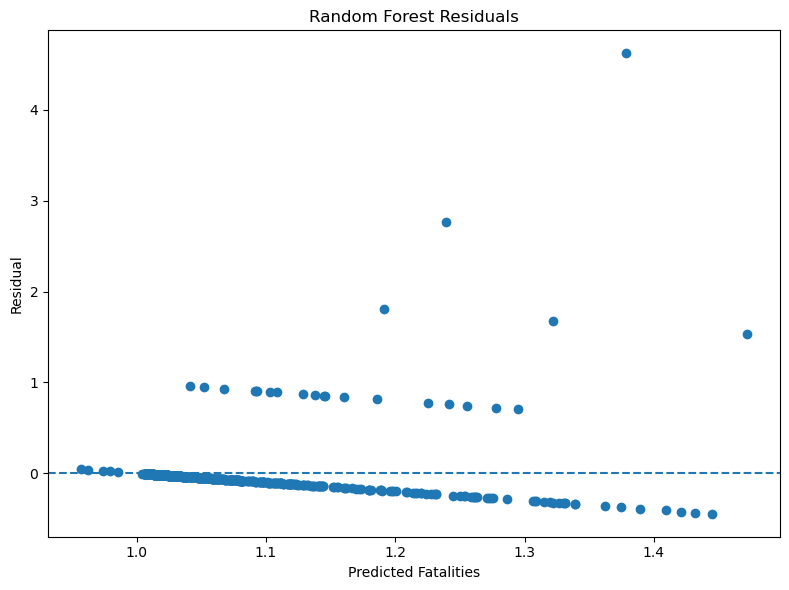

In [213]:
plt.figure(figsize=(8, 6))

plt.scatter(rf_diagnostics["PREDICTED"], rf_diagnostics["RESIDUAL"])

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Fatalities")
plt.ylabel("Residual")
plt.title("Random Forest Residuals")

plt.tight_layout()
plt.show()

## Random Forest Diagnostic Analysis

Residual analysis was conducted to assess the behaviour of the final Random Forest model on the held-out test data. Residuals were calculated as the difference between the observed and predicted number of fatalities.

The mean residual was -0.0213, with a median of -0.0476, indicating that the model did not exhibit substantial overall systematic bias across the test observations. However, the residuals ranged from -0.4448 to 4.6216, with the largest positive residual corresponding to a crash involving six observed fatalities that the model predicted at approximately 1.38 fatalities.

The diagnostic results indicate that the model generally produced predictions close to the dominant one-fatality outcome but tended to underestimate crashes involving multiple fatalities. This behaviour is consistent with the distribution of the test data, in which 502 of 526 crashes (95.4%) involved one fatality, while only 24 crashes (4.6%) involved more than one fatality.

The large positive residuals were therefore retained rather than treated as erroneous observations, as they represent genuine higher-severity crash outcomes. This finding highlights an important limitation of the model: although the Random Forest achieved the lowest RMSE among the evaluated models, its predictions are less accurate for rare, high-fatality crashes.

Given these crash conditions, what fatality count does the Random Forest predict?

Step 1  Check the exact category values

In [214]:
print("DISTRICT:")
print(sorted(X_train["DISTRICT"].dropna().unique()))

print("\nCRASH TYPES:")
print(sorted(X_train["CRASH_TYPE_DESC"].dropna().unique()))

print("\nROAD CATEGORIES:")
print(sorted(X_train["ROAD_CATEGORY"].dropna().unique()))

print("\nDAYS OF WEEK:")
print(sorted(X_train["DAY_OF_WEEK"].dropna().unique()))

print("\nFESTIVE SEASON YEARS:")
print(sorted(X_train["FESTIVE_SEASON_YEAR"].dropna().unique()))

DISTRICT:
['City of Johannesburg', 'City of Tshwane', 'Ekurhuleni', 'Sedibeng', 'West Rand']

CRASH TYPES:
['Accident with Pedal Cyclist', 'Accident with fixed/other object', 'Accident with pedestrian', 'Approach at angle (both trav. straight)', 'Approach at angle,  One or both turning', 'Head on', 'Head/rear end', 'Hit and Run', 'Person fell off', 'Sideswipe (opposite directions)', 'Sideswipe (same direction)', 'Single vehicle (left the road)', 'Single vehicle (overturned)', 'Turn right in face of oncoming traffic', 'Unknown']

ROAD CATEGORIES:
['K Route', 'M Route', 'N Route', 'Named Road', 'R Route', 'Unknown']

DAYS OF WEEK:
['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

FESTIVE SEASON YEARS:
[np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022)]


In [215]:
scenarios = pd.DataFrame([
    {
        "SCENARIO": "1. Pedestrian crash at night",
        "DISTRICT": "City of Johannesburg",
        "CRASH_TYPE_DESC": "Accident with pedestrian",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 1,
        "ROAD_CATEGORY": "Named Road",
        "ACCIDENT_HOUR": 20,
        "DAY_OF_WEEK": "Saturday",
        "FESTIVE_DAY": 17,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "2. Head-on collision at night",
        "DISTRICT": "City of Tshwane",
        "CRASH_TYPE_DESC": "Head on",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 2,
        "ROAD_CATEGORY": "N Route",
        "ACCIDENT_HOUR": 20,
        "DAY_OF_WEEK": "Saturday",
        "FESTIVE_DAY": 17,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "3. Single vehicle rollover",
        "DISTRICT": "Ekurhuleni",
        "CRASH_TYPE_DESC": "Single vehicle (overturned)",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 1,
        "ROAD_CATEGORY": "R Route",
        "ACCIDENT_HOUR": 23,
        "DAY_OF_WEEK": "Saturday",
        "FESTIVE_DAY": 20,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "4. Hit-and-run at night",
        "DISTRICT": "City of Johannesburg",
        "CRASH_TYPE_DESC": "Hit and Run",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 1,
        "ROAD_CATEGORY": "Named Road",
        "ACCIDENT_HOUR": 22,
        "DAY_OF_WEEK": "Friday",
        "FESTIVE_DAY": 20,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "5. Head/rear-end collision",
        "DISTRICT": "Ekurhuleni",
        "CRASH_TYPE_DESC": "Head/rear end",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 2,
        "ROAD_CATEGORY": "N Route",
        "ACCIDENT_HOUR": 18,
        "DAY_OF_WEEK": "Friday",
        "FESTIVE_DAY": 10,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "6. Pedestrian crash during daytime",
        "DISTRICT": "Sedibeng",
        "CRASH_TYPE_DESC": "Accident with pedestrian",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 1,
        "ROAD_CATEGORY": "R Route",
        "ACCIDENT_HOUR": 14,
        "DAY_OF_WEEK": "Monday",
        "FESTIVE_DAY": 29,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "7. Three-vehicle collision",
        "DISTRICT": "City of Tshwane",
        "CRASH_TYPE_DESC": "Approach at angle (both trav. straight)",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 3,
        "ROAD_CATEGORY": "N Route",
        "ACCIDENT_HOUR": 19,
        "DAY_OF_WEEK": "Sunday",
        "FESTIVE_DAY": 17,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "8. Single vehicle leaves road",
        "DISTRICT": "West Rand",
        "CRASH_TYPE_DESC": "Single vehicle (left the road)",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 1,
        "ROAD_CATEGORY": "Named Road",
        "ACCIDENT_HOUR": 2,
        "DAY_OF_WEEK": "Sunday",
        "FESTIVE_DAY": 20,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "9. Cyclist crash",
        "DISTRICT": "City of Johannesburg",
        "CRASH_TYPE_DESC": "Accident with Pedal Cyclist",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 1,
        "ROAD_CATEGORY": "M Route",
        "ACCIDENT_HOUR": 7,
        "DAY_OF_WEEK": "Tuesday",
        "FESTIVE_DAY": 5,
        "FESTIVE_SEASON_YEAR": 2022
    },
    {
        "SCENARIO": "10. Two-vehicle sideswipe",
        "DISTRICT": "Ekurhuleni",
        "CRASH_TYPE_DESC": "Sideswipe (opposite directions)",
        "TOTAL_VEHICLE_INVOLVED_CLEAN": 2,
        "ROAD_CATEGORY": "R Route",
        "ACCIDENT_HOUR": 18,
        "DAY_OF_WEEK": "Thursday",
        "FESTIVE_DAY": 42,
        "FESTIVE_SEASON_YEAR": 2022
    }
])

scenarios

,SCENARIO,DISTRICT,CRASH_TYPE_DESC,TOTAL_VEHICLE_INVOLVED_CLEAN,ROAD_CATEGORY,ACCIDENT_HOUR,DAY_OF_WEEK,FESTIVE_DAY,FESTIVE_SEASON_YEAR
0,1. Pedestrian crash at night,City of Johannesburg,Accident with pedestrian,1,Named Road,20,Saturday,17,2022
1,2. Head-on collision at night,City of Tshwane,Head on,2,N Route,20,Saturday,17,2022
2,3. Single vehicle rollover,Ekurhuleni,Single vehicle (overturned),1,R Route,23,Saturday,20,2022
3,4. Hit-and-run at night,City of Johannesburg,Hit and Run,1,Named Road,22,Friday,20,2022
4,5. Head/rear-end collision,Ekurhuleni,Head/rear end,2,N Route,18,Friday,10,2022
5,6. Pedestrian crash during daytime,Sedibeng,Accident with pedestrian,1,R Route,14,Monday,29,2022
6,7. Three-vehicle collision,City of Tshwane,Approach at angle (both trav. straight),3,N Route,19,Sunday,17,2022
7,8. Single vehicle leaves road,West Rand,Single vehicle (left the road),1,Named Road,2,Sunday,20,2022
8,9. Cyclist crash,City of Johannesburg,Accident with Pedal Cyclist,1,M Route,7,Tuesday,5,2022
9,10. Two-vehicle sideswipe,Ekurhuleni,Sideswipe (opposite directions),2,R Route,18,Thursday,42,2022


In [216]:
X_scenarios = scenarios[predictor_columns]

X_scenarios_processed = preprocessor.transform( X_scenarios)

print("Scenario input shape:", X_scenarios.shape)
print("Processed scenario shape:", X_scenarios_processed.shape)

Scenario input shape: (10, 8)
Processed scenario shape: (10, 41)


In [217]:
scenario_predictions = tuned_rf_model.predict( X_scenarios_processed)

scenarios["PREDICTED_FATALITIES"] = scenario_predictions
scenarios[   ["SCENARIO", "DISTRICT",  "CRASH_TYPE_DESC", "ACCIDENT_HOUR", "FESTIVE_DAY", "PREDICTED_FATALITIES"]]

,SCENARIO,DISTRICT,CRASH_TYPE_DESC,ACCIDENT_HOUR,FESTIVE_DAY,PREDICTED_FATALITIES
0,1. Pedestrian crash at night,City of Johannesburg,Accident with pedestrian,20,17,1.040787
1,2. Head-on collision at night,City of Tshwane,Head on,20,17,1.330646
2,3. Single vehicle rollover,Ekurhuleni,Single vehicle (overturned),23,20,1.095519
3,4. Hit-and-run at night,City of Johannesburg,Hit and Run,22,20,1.034208
4,5. Head/rear-end collision,Ekurhuleni,Head/rear end,18,10,1.112786
5,6. Pedestrian crash during daytime,Sedibeng,Accident with pedestrian,14,29,1.034165
6,7. Three-vehicle collision,City of Tshwane,Approach at angle (both trav. straight),19,17,1.316961
7,8. Single vehicle leaves road,West Rand,Single vehicle (left the road),2,20,1.060319
8,9. Cyclist crash,City of Johannesburg,Accident with Pedal Cyclist,7,5,1.054859
9,10. Two-vehicle sideswipe,Ekurhuleni,Sideswipe (opposite directions),18,42,1.104327


## Individual Crash Prediction

The selected Random Forest model was applied to illustrative individual crash scenarios to demonstrate how the model can be used to estimate the number of fatalities associated with a specific road traffic crash during the festive season in Gauteng.

The scenarios were defined using combinations of temporal, geographical and crash-related characteristics available in the modelling dataset. The same fitted preprocessing pipeline used during model evaluation was applied to the scenario data before generating predictions.

The model produced estimated fatality counts ranging from approximately **1.03 to 1.32 fatalities per crash** across the ten scenarios. The **head-on collision at night** produced an estimated fatality count of approximately **1.33**, while the **three-vehicle collision** produced an estimated count of approximately **1.32**. The remaining scenarios produced estimates close to one fatality per crash.

These predictions are **illustrative model outputs rather than observed outcomes or forecasts of specific future crashes**. They demonstrate how the selected Random Forest model can be used to estimate the number of fatalities associated with an individual crash based on its temporal, geographical and crash-related characteristics. The predicted values should therefore be interpreted as model-estimated fatality counts rather than literal numbers of people.

In [218]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Predictions on the held-out test set
y_pred = tuned_rf_model.predict(X_test_processed)

# Performance metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Random Forest Test Performance")
print("-" * 35)
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

Random Forest Test Performance
-----------------------------------
RMSE: 0.3313
MAE:  0.1304
R²:   0.0824


In [219]:
# Compare actual and predicted values
prediction_check = pd.DataFrame({
    "ACTUAL": y_test.values,
    "PREDICTED": y_pred
})

prediction_check.head(20)

,ACTUAL,PREDICTED
0,1.0,1.130642
1,1.0,1.118894
2,1.0,1.030350
3,1.0,1.087031
4,1.0,1.027621
5,1.0,1.213900
6,1.0,1.095820
7,1.0,1.076777
8,1.0,1.077371
9,1.0,1.053067


In [220]:
severity_diagnostics = (  prediction_check.assign(ABS_ERROR=lambda x: abs(x["ACTUAL"] - x["PREDICTED"])).groupby("ACTUAL")
    .agg(
        COUNT=("PREDICTED", "count"),
        MEAN_PREDICTED=("PREDICTED", "mean"),
        MAE=("ABS_ERROR", "mean")
    ).reset_index()
)
severity_diagnostics

,ACTUAL,COUNT,MEAN_PREDICTED,MAE
0,1.0,502,1.079156,0.079718
1,2.0,19,1.149964,0.850036
2,3.0,3,1.328613,1.671387
3,4.0,1,1.239593,2.760407
4,6.0,1,1.378400,4.621600


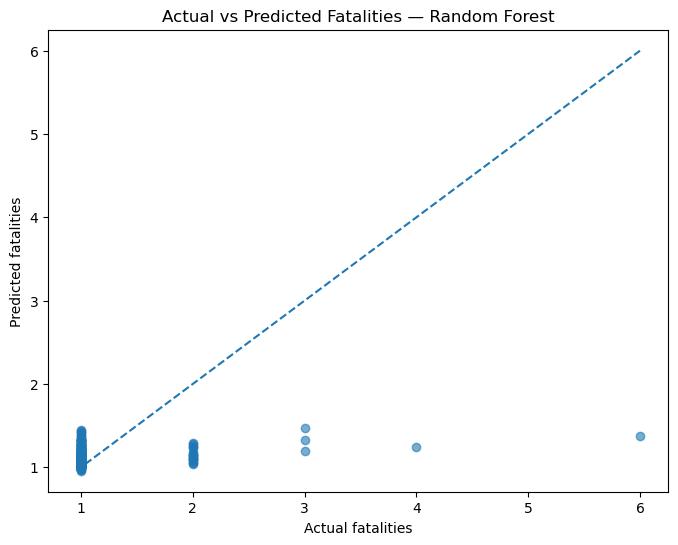

In [221]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--"
)

plt.xlabel("Actual fatalities")
plt.ylabel("Predicted fatalities")
plt.title("Actual vs Predicted Fatalities — Random Forest")

plt.show()

In [222]:
#residual analysis
# Calculate residuals
residuals = y_test.values - y_pred

print("Residual Summary")
print("-" * 30)
print(f"Mean residual: {residuals.mean():.4f}")
print(f"Minimum residual: {residuals.min():.4f}")
print(f"Maximum residual: {residuals.max():.4f}")

Residual Summary
------------------------------
Mean residual: -0.0213
Minimum residual: -0.4448
Maximum residual: 4.6216


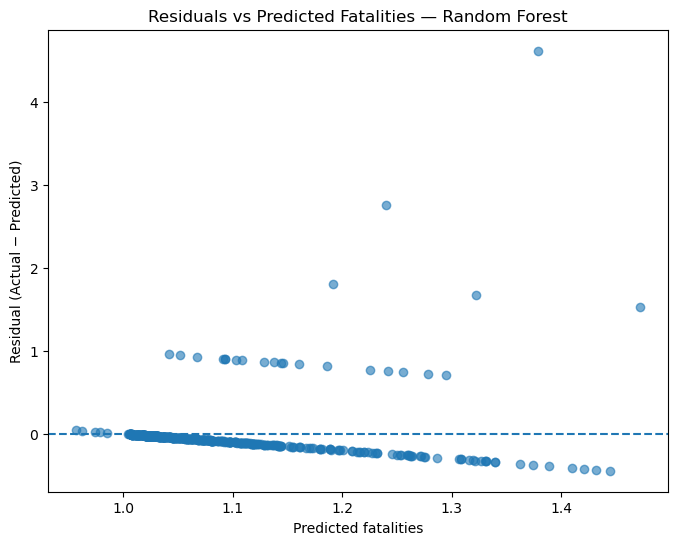

In [223]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline( y=0, linestyle="--")

plt.xlabel("Predicted fatalities")
plt.ylabel("Residual (Actual − Predicted)")
plt.title("Residuals vs Predicted Fatalities — Random Forest")

plt.show()

In [224]:
print("Prediction Summary")
print(f"Minimum prediction: {y_pred.min():.4f}")
print(f"Maximum prediction: {y_pred.max():.4f}")
print(f"Mean prediction:    {y_pred.mean():.4f}")
print(f"Std prediction:     {y_pred.std():.4f}")

print("\nActual Summary")
print(f"Minimum actual: {y_test.min():.4f}")
print(f"Maximum actual: {y_test.max():.4f}")
print(f"Mean actual:    {y_test.mean():.4f}")
print(f"Std actual:     {y_test.std():.4f}")

Prediction Summary
Minimum prediction: 0.9574
Maximum prediction: 1.4718
Mean prediction:    1.0840
Std prediction:     0.0861

Actual Summary
Minimum actual: 1.0000
Maximum actual: 6.0000
Mean actual:    1.0627
Std actual:     0.3462


In [225]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

model_predictions = {"Random Forest": tuned_rf_predictions,"XGBoost": tuned_xgb_predictions, "AdaBoost": tuned_ada_predictions,
                     
      "Gradient Boosting": tuned_gb_predictions,
    "SVR": tuned_svr_predictions,
    "ANN/MLP": tuned_mlp_predictions
}

model_results = []

for model_name, predictions in model_predictions.items():

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    model_results.append([  model_name, rmse, mae,  r2 ])

model_results = pd.DataFrame(  model_results,columns=["MODEL", "RMSE", "MAE", "R2"])

model_results.sort_values("RMSE").reset_index(drop=True)

,MODEL,RMSE,MAE,R2
0,Random Forest,0.331339,0.130352,0.082353
1,XGBoost,0.334693,0.132163,0.063681
2,AdaBoost,0.337215,0.155389,0.049518
3,Gradient Boosting,0.341285,0.136027,0.026433
4,SVR,0.344767,0.122740,0.006467
5,ANN/MLP,0.393487,0.206625,-0.294168


In [226]:
#now testing for fatailties that are 2 or more
high_fatality_results = []

high_fatality_mask = y_test.values >= 2

for model_name, predictions in model_predictions.items():

    actual_high = y_test.values[high_fatality_mask]
    predicted_high = predictions[high_fatality_mask]

    high_fatality_mae = mean_absolute_error(actual_high,predicted_high)

    high_fatality_rmse = np.sqrt(mean_squared_error(actual_high, predicted_high ) )
    high_fatality_results.append([model_name, high_fatality_mae, high_fatality_rmse ])
    
high_fatality_results = pd.DataFrame(high_fatality_results, columns=["MODEL","HIGH_FATALITY_MAE","HIGH_FATALITY_RMSE" ])
high_fatality_results.sort_values("HIGH_FATALITY_RMSE").reset_index(drop=True)

,MODEL,HIGH_FATALITY_MAE,HIGH_FATALITY_RMSE
0,AdaBoost,1.153315,1.428543
1,Random Forest,1.189452,1.461081
2,XGBoost,1.215691,1.482922
3,Gradient Boosting,1.219456,1.490643
4,ANN/MLP,1.212995,1.531037
5,SVR,1.292530,1.568780


In [227]:
from sklearn.metrics import mean_absolute_percentage_error

mape_results = []

for model_name, predictions in model_predictions.items():

    mape = mean_absolute_percentage_error( y_test, predictions ) * 100

    mape_results.append([ model_name,mape ])

mape_results = pd.DataFrame(mape_results,columns=["MODEL", "MAPE_%"])

mape_results.sort_values("MAPE_%").reset_index(drop=True)

,MODEL,MAPE_%
0,SVR,8.699929
1,Random Forest,9.738690
2,XGBoost,9.849813
3,Gradient Boosting,10.223527
4,AdaBoost,12.338964
5,ANN/MLP,17.290888


In [228]:
# Final comparison of candidate regression models

model_comparison = pd.DataFrame({
    "Model": ["Random Forest","XGBoost", "AdaBoost", "Gradient Boosting", "SVR",
        "ANN/MLP"],
    "RMSE": [ 0.331339, 0.334693, 0.337215, 0.341285,0.344767,  0.393487 ],
    "MAE": [0.130352, 0.132163, 0.155389, 0.136027, 0.122740,0.206625 ],
    "R2": [ 0.082353, 0.063681, 0.049518, 0.026433, 0.006467,-0.294168],
    "MAPE (%)": [ 9.738690,9.849813,12.338964,10.223527, 8.699929, 17.290888 ]})

model_comparison.sort_values("RMSE").reset_index(drop=True)

,Model,RMSE,MAE,R2,MAPE (%)
0,Random Forest,0.331339,0.130352,0.082353,9.738690
1,XGBoost,0.334693,0.132163,0.063681,9.849813
2,AdaBoost,0.337215,0.155389,0.049518,12.338964
3,Gradient Boosting,0.341285,0.136027,0.026433,10.223527
4,SVR,0.344767,0.122740,0.006467,8.699929
5,ANN/MLP,0.393487,0.206625,-0.294168,17.290888


In [229]:
# Model performance by crash type

crash_type_results = []

for model_name, predictions in model_predictions.items():

    results = pd.DataFrame({"CRASH_TYPE_DESC": X_test["CRASH_TYPE_DESC"].values, "ACTUAL": y_test.values,"PREDICTED": predictions })

    for crash_type, group in results.groupby("CRASH_TYPE_DESC"):

        # Ignore very small groups
        if len(group) >= 5:

            rmse = np.sqrt(mean_squared_error( group["ACTUAL"], group["PREDICTED"]))

            mae = mean_absolute_error(group["ACTUAL"], group["PREDICTED"] )

            crash_type_results.append({"MODEL": model_name,"CRASH_TYPE": crash_type,"N": len(group),"RMSE": rmse,"MAE": mae})

crash_type_results = pd.DataFrame(crash_type_results)

crash_type_results.sort_values(["CRASH_TYPE", "RMSE"]).reset_index(drop=True)

,MODEL,CRASH_TYPE,N,RMSE,MAE
0,XGBoost,Accident with Pedal Cyclist,8,0.058260,0.056995
1,Gradient Boosting,Accident with Pedal Cyclist,8,0.059576,0.058500
2,Random Forest,Accident with Pedal Cyclist,8,0.069001,0.063513
3,AdaBoost,Accident with Pedal Cyclist,8,0.078484,0.078364
4,SVR,Accident with Pedal Cyclist,8,0.090841,0.088140
...,...,...,...,...,...
61,SVR,Single vehicle (overturned),52,0.412163,0.213755
62,Gradient Boosting,Single vehicle (overturned),52,0.416207,0.269750
63,XGBoost,Single vehicle (overturned),52,0.418315,0.270795
64,AdaBoost,Single vehicle (overturned),52,0.449549,0.309142


In [230]:
# Best-performing model for each crash type

best_crash_models = (crash_type_results.sort_values(["CRASH_TYPE", "RMSE"]).groupby("CRASH_TYPE").first().reset_index())
best_crash_models = best_crash_models[["CRASH_TYPE", "N", "MODEL", "RMSE", "MAE"]]
best_crash_models

,CRASH_TYPE,N,MODEL,RMSE,MAE
0,Accident with Pedal Cyclist,8,XGBoost,0.058260,0.056995
1,Accident with fixed/other object,38,AdaBoost,0.167194,0.100001
2,Accident with pedestrian,155,Random Forest,0.091541,0.047658
3,Approach at angle (both trav. straight),6,AdaBoost,0.087859,0.087859
4,"Approach at angle, One or both turning",14,ANN/MLP,0.321373,0.241511
5,Head on,32,AdaBoost,1.064583,0.691241
6,Head/rear end,38,AdaBoost,0.270126,0.155411
7,Hit and Run,163,Random Forest,0.037042,0.032054
8,Sideswipe (opposite directions),7,AdaBoost,0.354161,0.208982
9,Sideswipe (same direction),6,Random Forest,0.754066,0.431515


In [231]:
# Overall crash-type performance for each model

crash_type_summary = (
    crash_type_results.groupby("MODEL").agg(CRASH_TYPES=("CRASH_TYPE", "count"),TOTAL_OBSERVATIONS=("N", "sum"),MEAN_RMSE=("RMSE", "mean"),
        MEAN_MAE=("MAE", "mean")).reset_index().sort_values("MEAN_RMSE"))

crash_type_summary

,MODEL,CRASH_TYPES,TOTAL_OBSERVATIONS,MEAN_RMSE,MEAN_MAE
1,AdaBoost,11,519,0.344846,0.217244
3,Random Forest,11,519,0.347443,0.226733
5,XGBoost,11,519,0.348749,0.215841
2,Gradient Boosting,11,519,0.354457,0.219442
4,SVR,11,519,0.360983,0.208662
0,ANN/MLP,11,519,0.481264,0.335765


In [232]:
# Number of test observations for each crash type

crash_type_counts = (X_test.groupby("CRASH_TYPE_DESC").size().reset_index(name="N").sort_values("N", ascending=False)
)
crash_type_counts

,CRASH_TYPE_DESC,N
7,Hit and Run,163
2,Accident with pedestrian,155
12,Single vehicle (overturned),52
1,Accident with fixed/other object,38
6,Head/rear end,38
5,Head on,32
4,"Approach at angle, One or both turning",14
0,Accident with Pedal Cyclist,8
9,Sideswipe (opposite directions),7
3,Approach at angle (both trav. straight),6


In [233]:
# Fatalities by crash type during the festive season

crash_type_fatalities = (df_festive_complete.groupby("CRASH_TYPE_DESC").agg(
CRASHES=("CRASH_TYPE_DESC", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")).reset_index().sort_values("TOTAL_FATALITIES", ascending=False))

crash_type_fatalities

,CRASH_TYPE_DESC,CRASHES,TOTAL_FATALITIES,MEAN_FATALITIES
2,Accident with pedestrian,578,590.0,1.020761
7,Hit and Run,441,444.0,1.006803
12,Single vehicle (overturned),192,226.0,1.177083
5,Head on,118,164.0,1.389831
1,Accident with fixed/other object,144,160.0,1.111111
6,Head/rear end,109,121.0,1.110092
3,Approach at angle (both trav. straight),46,53.0,1.152174
9,Sideswipe (opposite directions),40,48.0,1.200000
14,Unknown,22,27.0,1.227273
0,Accident with Pedal Cyclist,26,26.0,1.000000


In [234]:
# Percentage contribution of each crash type to total fatalities

total_fatalities = crash_type_fatalities["TOTAL_FATALITIES"].sum()
crash_type_fatalities["FATALITY_PERCENT"] = ( crash_type_fatalities["TOTAL_FATALITIES"]/ total_fatalities * 100)

crash_type_fatalities

,CRASH_TYPE_DESC,CRASHES,TOTAL_FATALITIES,MEAN_FATALITIES,FATALITY_PERCENT
2,Accident with pedestrian,578,590.0,1.020761,30.538302
7,Hit and Run,441,444.0,1.006803,22.981366
12,Single vehicle (overturned),192,226.0,1.177083,11.697723
5,Head on,118,164.0,1.389831,8.488613
1,Accident with fixed/other object,144,160.0,1.111111,8.281573
6,Head/rear end,109,121.0,1.110092,6.262940
3,Approach at angle (both trav. straight),46,53.0,1.152174,2.743271
9,Sideswipe (opposite directions),40,48.0,1.200000,2.484472
14,Unknown,22,27.0,1.227273,1.397516
0,Accident with Pedal Cyclist,26,26.0,1.000000,1.345756


Now we move to when these festive-season fatalities occur.
first lloking into ACCIDENT_HOUR

examining both:
1. Actual fatalities by hour, and
2. How the six candidate models perform by hour.

In [235]:
# Fatalities by hour during the festive season

hour_fatalities = (df_festive_complete.groupby("ACCIDENT_HOUR").agg(CRASHES=("ACCIDENT_HOUR", "size"),TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")).reset_index().sort_values("ACCIDENT_HOUR"))
hour_fatalities

,ACCIDENT_HOUR,CRASHES,TOTAL_FATALITIES,MEAN_FATALITIES
0,0,66,76.0,1.151515
1,1,61,66.0,1.081967
2,2,56,58.0,1.035714
3,3,59,63.0,1.067797
4,4,54,58.0,1.074074
5,5,60,65.0,1.083333
6,6,67,72.0,1.074627
7,7,65,70.0,1.076923
8,8,45,52.0,1.155556
9,9,39,42.0,1.076923


Festive-season fatalities are concentrated in the evening, particularly around 19:00–23:00, with 20:00 recording the highest total number of fatalities. However, the highest average fatalities per crash occur at different hours, indicating that frequency of crashes and crash severity are not identical temporal patterns.

In [236]:
# Model performance by accident hour

hour_model_results = []

for model_name, predictions in model_predictions.items():

    results = pd.DataFrame({ "ACCIDENT_HOUR": X_test["ACCIDENT_HOUR"].values,"ACTUAL": y_test.values,"PREDICTED": predictions})

    for hour, group in results.groupby("ACCIDENT_HOUR"):

        if len(group) >= 5:
            rmse = np.sqrt(mean_squared_error(group["ACTUAL"],group["PREDICTED"]))
            mae = mean_absolute_error(group["ACTUAL"],group["PREDICTED"])
            hour_model_results.append({"MODEL": model_name,"HOUR": hour,"N": len(group),"RMSE": rmse,"MAE": mae})
            
hour_model_results = pd.DataFrame(hour_model_results)
hour_model_results.sort_values(["HOUR", "RMSE"]).reset_index(drop=True)

,MODEL,HOUR,N,RMSE,MAE
0,Random Forest,0,20,0.465863,0.212207
1,XGBoost,0,20,0.479767,0.218569
2,AdaBoost,0,20,0.480220,0.215614
3,Gradient Boosting,0,20,0.482205,0.195622
4,SVR,0,20,0.483896,0.188163
...,...,...,...,...,...
139,Random Forest,23,25,0.266989,0.157938
140,SVR,23,25,0.268845,0.132065
141,XGBoost,23,25,0.269197,0.159631
142,Gradient Boosting,23,25,0.271398,0.157401


In [237]:
# Overall model performance across accident hours

hour_model_summary = (hour_model_results.groupby("MODEL").agg(HOURS=("HOUR", "count"),TOTAL_OBSERVATIONS=("N", "sum"),MEAN_RMSE=("RMSE", "mean"),
        MEAN_MAE=("MAE", "mean")
    ).reset_index().sort_values("MEAN_RMSE"))
hour_model_summary

,MODEL,HOURS,TOTAL_OBSERVATIONS,MEAN_RMSE,MEAN_MAE
5,XGBoost,24,526,0.243024,0.121602
3,Random Forest,24,526,0.243031,0.121217
4,SVR,24,526,0.244432,0.113847
2,Gradient Boosting,24,526,0.250810,0.124866
1,AdaBoost,24,526,0.260598,0.146781
0,ANN/MLP,24,526,0.324779,0.200299


### Multidimensional Model Comparison

The candidate regression models are being evaluated from multiple analytical perspectives rather than selecting a final model based on a single performance metric.

- **Overall performance:** Random Forest currently provides the strongest overall performance, achieving the lowest RMSE and highest R² on the test set.
- **WHAT – Crash Type:** AdaBoost achieves the lowest mean RMSE across the analysed crash types, while Random Forest performs particularly well for several of the major crash categories.
- **WHEN – Accident Hour:** XGBoost achieves the lowest mean hourly RMSE, although its performance is effectively tied with Random Forest. SVR records the lowest mean hourly MAE.

These results demonstrate that **no single model is consistently the best across every analytical dimension**. Therefore, the final model will not be selected simply by counting how many subgroup analyses a model wins.

Instead, model selection will consider the **overall predictive performance together with the model's behaviour across relevant crash characteristics and temporal patterns**. At this stage, Random Forest remains the leading candidate for the primary model because of its strongest overall test-set performance.

In [238]:
#examining day OF week.
# Model performance by day of week

day_model_results = []

for model_name, predictions in model_predictions.items():ok
    results = pd.DataFrame({"DAY_OF_WEEK": X_test["DAY_OF_WEEK"].values, "ACTUAL": y_test.values, "PREDICTED": predictions})

    for day, group in results.groupby("DAY_OF_WEEK"):

        if len(group) >= 5:
            rmse = np.sqrt(mean_squared_error(group["ACTUAL"],group["PREDICTED"]))
            mae = mean_absolute_error(group["ACTUAL"],group["PREDICTED"])
            day_model_results.append({"MODEL": model_name,"DAY_OF_WEEK": day,"N": len(group),"RMSE": rmse,"MAE": mae})

day_model_results = pd.DataFrame(day_model_results)

day_model_results.sort_values(["DAY_OF_WEEK", "RMSE"]).reset_index(drop=True)

IndentationError: unexpected indent (733944331.py, line 7)

- Friday: Random Forest has the lowest RMSE (0.401).
- Saturday: AdaBoost has the lowest RMSE (0.367).
- Sunday: AdaBoost narrowly has the lowest RMSE (0.477), with XGBoost extremely close (0.477) and RF also very close.
- Monday: SVR performs best (0.127).
- Tuesday: Random Forest performs best (0.135).
- Wednesday: SVR performs best (0.081).
- Thursday: Gradient Boosting performs best (0.194).
  
No model consistently dominates across every day of the week.

In [ ]:
# Fatalities by day of week during the festive season

day_fatalities = (df_festive_complete.groupby("DAY_OF_WEEK").agg(CRASHES=("DAY_OF_WEEK", "size"),TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")).reset_index())

day_fatalities

In [ ]:
# Random Forest performance by day of week

rf_day_results = pd.DataFrame({"DAY_OF_WEEK": X_test["DAY_OF_WEEK"].values,"ACTUAL": y_test.values,"PREDICTED": model_predictions["Random Forest"]
})

rf_day_summary = (rf_day_results.groupby("DAY_OF_WEEK").agg(CRASHES=("ACTUAL", "size"),ACTUAL_FATALITIES=("ACTUAL", "sum"),PREDICTED_FATALITIES=("PREDICTED", "sum"),
        MEAN_ACTUAL=("ACTUAL", "mean"),
        MEAN_PREDICTED=("PREDICTED", "mean"),
        MAE=("ACTUAL", lambda x: np.mean(
            np.abs(x.values -rf_day_results.loc[x.index, "PREDICTED"].values)))).reset_index())

rf_day_summary

In [ ]:
# Random Forest performance by day of week

rf_day_results = pd.DataFrame({"DAY_OF_WEEK": X_test["DAY_OF_WEEK"].values,"ACTUAL": y_test.values,"PREDICTED": model_predictions["Random Forest"]})

rf_day_summary = (rf_day_results.groupby("DAY_OF_WEEK").agg(
        CRASHES=("ACTUAL", "size"),
        ACTUAL_FATALITIES=("ACTUAL", "sum"),
        PREDICTED_FATALITIES=("PREDICTED", "sum"),
        MEAN_ACTUAL=("ACTUAL", "mean"),
        MEAN_PREDICTED=("PREDICTED", "mean"),
        MAE=("ACTUAL", lambda x: np.mean(
            np.abs(x.values - rf_day_results.loc[x.index, "PREDICTED"].values
            )))).reset_index())

rf_day_summary

In [ ]:
# Fatalities by day within the festive season

festive_day_fatalities = (
    df_festive_complete
    .groupby("FESTIVE_DAY")
    .agg(CRASHES=("FESTIVE_DAY", "size"), TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")).reset_index()
    .sort_values("FESTIVE_DAY"))

festive_day_fatalities

In [ ]:
# Random Forest predictions by day within the festive season

rf_festive_day_results = pd.DataFrame({
    "FESTIVE_DAY": X_test["FESTIVE_DAY"].values,
    "ACTUAL": y_test.values,
    "PREDICTED": model_predictions["Random Forest"]
})

rf_festive_day_summary = (
    rf_festive_day_results
    .groupby("FESTIVE_DAY")
    .agg(
        CRASHES=("ACTUAL", "size"),
        ACTUAL_FATALITIES=("ACTUAL", "sum"),
        PREDICTED_FATALITIES=("PREDICTED", "sum"),
        MEAN_ACTUAL=("ACTUAL", "mean"),
        MEAN_PREDICTED=("PREDICTED", "mean"),
        MAE=("ACTUAL", lambda x: np.mean(
            np.abs(
                x.values -
                rf_festive_day_results.loc[x.index, "PREDICTED"].values
            )
        ))
    )
    .reset_index()
    .sort_values("FESTIVE_DAY")
)

rf_festive_day_summary

In [ ]:
# Fatalities by hour during the festive season

hour_fatalities = (
    df_festive_complete
    .groupby("ACCIDENT_HOUR")
    .agg(CRASHES=("ACCIDENT_HOUR", "size"), TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"), MEAN_FATALITIES=("TOTAL_FATALITIES", "mean"))
    .reset_index().sort_values("ACCIDENT_HOUR"))

hour_fatalities

In [ ]:
# Random Forest predictions by accident hour

rf_hour_results = pd.DataFrame({"ACCIDENT_HOUR": X_test["ACCIDENT_HOUR"].values,"ACTUAL": y_test.values,"PREDICTED": model_predictions["Random Forest"]
})

rf_hour_summary = (
    rf_hour_results
    .groupby("ACCIDENT_HOUR")
    .agg(CRASHES=("ACTUAL", "size"),ACTUAL_FATALITIES=("ACTUAL", "sum"), PREDICTED_FATALITIES=("PREDICTED", "sum"), MEAN_ACTUAL=("ACTUAL", "mean"),
        MEAN_PREDICTED=("PREDICTED", "mean"),
        MAE=("ACTUAL", lambda x: np.mean(
            np.abs(
                x.values -
                rf_hour_results.loc[x.index, "PREDICTED"].values )))).reset_index().sort_values("ACCIDENT_HOUR"))

rf_hour_summary

District next. This is our main WHERE analysis.
We'll first establish the observed festive-season fatality pattern by district, before comparing it with the Random Forest predictions.

In [ ]:
# Fatalities by district during the festive season

district_fatalities = (
    df_festive_complete
    .groupby("DISTRICT")
    .agg(
        CRASHES=("DISTRICT", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")
    )
    .reset_index()
    .sort_values("TOTAL_FATALITIES", ascending=False)
)

district_fatalities

In [ ]:
# Spatial hierarchy between District, Police, Station, Road

spatial_summary = (
    df_festive_complete
    .groupby([
        "DISTRICT",
        "POLICE_STATION",
        "ROAD_NAME_NUMBER"
    ])
    .agg(
        CRASHES=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES=("TOTAL_FATALITIES", "mean")
    )
    .reset_index()
)

print("Unique Districts:", spatial_summary["DISTRICT"].nunique())
print("Unique Police Stations:", spatial_summary["POLICE_STATION"].nunique())
print("Unique District–Police Station–Road combinations:", len(spatial_summary))

spatial_summary.head()

In [ ]:
# Examine the number of crashes represented by each spatial combination

spatial_summary["CRASHES"].value_counts().sort_index()

In [ ]:
# Spatial combinations with at least 5 observed crashes

spatial_5plus = (
    spatial_summary[
        spatial_summary["CRASHES"] >= 5
    ]
    .sort_values(
        ["TOTAL_FATALITIES", "CRASHES"],
        ascending=[False, False]
    )
)

print("Spatial combinations with at least 5 crashes:", len(spatial_5plus))

spatial_5plus

In [ ]:
# Random Forest predictions at the District–Police Station–Road level

rf_spatial_results = pd.DataFrame({
    "DISTRICT": df_festive_complete.loc[X_test.index, "DISTRICT"].values,
    "POLICE_STATION": df_festive_complete.loc[X_test.index, "POLICE_STATION"].values,
    "ROAD_NAME_NUMBER": df_festive_complete.loc[X_test.index, "ROAD_NAME_NUMBER"].values,
    "ACTUAL": y_test.values,
    "PREDICTED": model_predictions["Random Forest"]
})

rf_spatial_summary = (
    rf_spatial_results
    .groupby(
        ["DISTRICT", "POLICE_STATION", "ROAD_NAME_NUMBER"]
    )
    .agg(
        CRASHES=("ACTUAL", "size"),
        ACTUAL_FATALITIES=("ACTUAL", "sum"),
        PREDICTED_FATALITIES=("PREDICTED", "sum"),
        MEAN_ACTUAL=("ACTUAL", "mean"),
        MEAN_PREDICTED=("PREDICTED", "mean")
    )
    .reset_index()
)

rf_spatial_summary

In [ ]:
# Random Forest spatial results for locations with at least 5 test-set crashes

rf_spatial_5plus = (rf_spatial_summary[rf_spatial_summary["CRASHES"] >= 5]
    .assign(
        ABS_DIFFERENCE=lambda x: abs(
            x["ACTUAL_FATALITIES"] - x["PREDICTED_FATALITIES"]
        )
    ).sort_values(["ACTUAL_FATALITIES", "CRASHES"],ascending=[False, False]))

rf_spatial_5plus

In [ ]:
# Direction of Random Forest spatial prediction error

rf_spatial_5plus = (rf_spatial_5plus.assign(ERROR=lambda x: (x["PREDICTED_FATALITIES"] - x["ACTUAL_FATALITIES"] )) .sort_values("ERROR"))
rf_spatial_5plus

The **Midrand–N1** combination shows the largest underprediction among the locations with at least five test-set crashes:
- 5 crashes
- 7 actual fatalities
- 5.59 predicted fatalities
- −1.41 error
The other five locations were all slightly overpredicted, with the largest overprediction at Orange Farms–N1 (+0.64).
But there is an important limitation: only six spatial combinations meet the ≥5-crash threshold in the test set. So this is useful as a diagnostic of model behaviour, but it is not enough to make a broad claim about spatial model performance across Gauteng.
something that is interesting is that Midrand–N1 had a mean of 1.4 fatalities per crash, while the other locations shown had exactly 1.0. That is consistent with the RF's broader behaviour we've already observed: it tends to pull predictions toward approximately one fatality and can struggle when crashes have multiple fatalities.

In [ ]:
# Spatial locations with at least 5 recorded festive-season crashes
# showing frequency, fatality burden, and average severity

spatial_findings = (spatial_summary[spatial_summary["CRASHES"] >= 5].sort_values(["TOTAL_FATALITIES", "MEAN_FATALITIES"],ascending=[False, False]
    ).reset_index(drop=True))
spatial_findings

## Spatial Findings

Using a threshold of **≥5 recorded festive-season crashes**, the analysis identified the locations with the highest observed fatality burden and severity.

### Highest Total Fatalities

- **Bronkhorstspruit – N4:** 17 fatalities from 12 crashes
- **Mondeor – N12:** 15 fatalities from 15 crashes
- **Midrand – N1:** 14 fatalities from 11 crashes
- **Benoni – N12:** 14 fatalities from 14 crashes
- **Hammanskraal – R101:** 13 fatalities from 11 crashes
- **Heidelberg – N3:** 13 fatalities from 12 crashes
- **Orange Farms – N1:** 13 fatalities from 13 crashes

### Highest Mean Fatalities per Crash

- **Hammanskraal – N1:** 1.571 fatalities per crash
- **Bronkhorstspruit – N4:** 1.417
- **Westonaria – R28:** 1.400
- **Ivory Park – Republic Road:** 1.400
- **Westonaria – N12:** 1.286
- **Midrand – N1:** 1.273
- **Germiston – N3:** 1.250

### Key Finding

**Bronkhorstspruit–N4 recorded the highest total fatalities (17), while Hammanskraal–N1 recorded the highest mean fatalities per crash (1.571).**

These findings describe **observed festive-season fatality patterns** and should not be interpreted as measures of underlying road risk.

In [ ]:
# Identify spatial locations where average fatalities exceed one per crash

spatial_severity = (spatial_findings[spatial_findings["MEAN_FATALITIES"] > 1].sort_values("MEAN_FATALITIES",ascending=False
    ).reset_index(drop=True))

spatial_severity

## Spatial Severity Findings

Among District–Police Station–Road combinations with **≥5 recorded festive-season crashes**, the highest mean fatalities per crash were:

- **Hammanskraal – N1:** 1.571 fatalities per crash
- **Bronkhorstspruit – N4:** 1.417
- **Westonaria – R28:** 1.400
- **Ivory Park – Republic Road:** 1.400
- **Westonaria – N12:** 1.286
- **Midrand – N1:** 1.273
- **Germiston – N3:** 1.250
- **Wierdaburg – N14:** 1.222
- **Olifantsfontein – R21:** 1.200
- **Pretoria North – R101:** 1.200
- **Olievenhoutbosch – N1:** 1.200
- **Lyttelton – N1:** 1.200
- **JHB Central – M2:** 1.200
- **Magaliesburg – R24:** 1.200

### Key Finding

**Hammanskraal–N1 had the highest observed mean fatalities per crash (1.571), while Bronkhorstspruit–N4 recorded the highest total fatalities (17).**

These results describe **observed festive-season fatality severity** and should not be interpreted as measures of underlying road risk.

In [ ]:
# Random Forest feature importance

feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({"FEATURE": feature_names,"IMPORTANCE": tuned_rf_model.feature_importances_
})

rf_importance = (
    rf_importance
    .sort_values("IMPORTANCE", ascending=False)
    .reset_index(drop=True)
)

rf_importance.head(20)

In [ ]:
# Aggregate Random Forest importance back to the original predictors

rf_importance["ORIGINAL_FEATURE"] = (rf_importance["FEATURE"].str.replace(r"^(categorical|numeric)__", "", regex=True).str.split("_", n=1)
    .str[0]
)

# Correct the categorical feature names that contain underscores
rf_importance.loc[rf_importance["FEATURE"].str.startswith("categorical__"),"ORIGINAL_FEATURE"] = (rf_importance.loc[rf_importance["FEATURE"].str.startswith("categorical__"),
        "FEATURE"
    ]
    .str.replace("categorical__", "", regex=False)
    .str.extract(
        r"^(DISTRICT|CRASH_TYPE_DESC|ROAD_CATEGORY|DAY_OF_WEEK|FESTIVE_SEASON_YEAR)"
    )[0]
)

rf_importance_summary = (rf_importance.groupby("ORIGINAL_FEATURE", as_index=False)["IMPORTANCE"].sum().sort_values("IMPORTANCE", ascending=False)
    .reset_index(drop=True)
)

rf_importance_summary

In [ ]:
# Correctly aggregate Random Forest importance by original predictor

def get_original_feature(feature):
    if feature.startswith("numeric__"):
        return feature.replace("numeric__", "")
    
    if feature.startswith("categorical__"):
        feature = feature.replace("categorical__", "")
        
        for original in categorical_features:
            if feature.startswith(original + "_"):
                return original
    
    return feature


rf_importance["ORIGINAL_FEATURE"] = (rf_importance["FEATURE"].apply(get_original_feature))

rf_importance_summary = (rf_importance.groupby("ORIGINAL_FEATURE", as_index=False)["IMPORTANCE"].sum().sort_values("IMPORTANCE", ascending=False)
    .reset_index(drop=True)
)

rf_importance_summary

## Random Forest Feature Importance

The Random Forest feature-importance analysis identified **crash type (`CRASH_TYPE_DESC`)** as the most influential predictor, accounting for **28.29%** of total feature importance.

Temporal variables also contributed substantially to the model, with **FESTIVE_DAY (12.60%)**, **DAY_OF_WEEK (12.20%)**, and **ACCIDENT_HOUR (11.75%)** together accounting for approximately **36.3%** of feature importance.

The remaining predictors showed relatively similar contributions, including **ROAD_CATEGORY (9.70%)**, **DISTRICT (8.55%)**, **FESTIVE_SEASON_YEAR (8.54%)**, and **TOTAL_VEHICLE_INVOLVED_CLEAN (8.37%)**.

These feature-importance values indicate the relative contribution of predictors to the Random Forest's predictions and should not be interpreted as evidence of causal relationships.

In [ ]:
import importlib.util

print(importlib.util.find_spec("shap"))

In [ ]:
from shap.explainers._tree import TreeExplainer

print("TreeExplainer imported successfully.")

In [ ]:
# Create SHAP TreeExplainer for the fitted Random Forest

rf_explainer = TreeExplainer(tuned_rf_model)

print("SHAP TreeExplainer created successfully.")

In [ ]:
# Prepare the processed test data for SHAP

X_test_shap = X_test_processed.toarray()

X_test_shap = X_test_shap.astype(float)

print("SHAP input shape:", X_test_shap.shape)
print("SHAP input dtype:", X_test_shap.dtype)

In [ ]:
# Calculate SHAP values for the Random Forest

rf_shap_values = rf_explainer.shap_values(X_test_shap)

print("SHAP values shape:", rf_shap_values.shape)

In [ ]:
# Global SHAP importance

shap_importance = pd.DataFrame({"FEATURE": feature_names,"MEAN_ABS_SHAP": np.abs(rf_shap_values).mean(axis=0)})

shap_importance["ORIGINAL_FEATURE"] = (shap_importance["FEATURE"].apply(get_original_feature))

shap_importance_summary = (shap_importance.groupby("ORIGINAL_FEATURE", as_index=False)["MEAN_ABS_SHAP"].sum().sort_values("MEAN_ABS_SHAP", ascending=False)
    .reset_index(drop=True))

shap_importance_summary

In [ ]:
# SHAP contribution and direction for individual encoded features

shap_encoded = pd.DataFrame({"FEATURE": feature_names,"MEAN_ABS_SHAP": np.abs(rf_shap_values).mean(axis=0),"MEAN_SHAP": rf_shap_values.mean(axis=0)
})

shap_encoded = (shap_encoded.sort_values("MEAN_ABS_SHAP", ascending=False).reset_index(drop=True))
shap_encoded.head(20)

In [ ]:
# SHAP direction for categorical features when the category is actually present

categorical_shap_results = []

for i, feature in enumerate(feature_names):
    if feature.startswith("categorical__"):
        
        # Identify observations where this one-hot category is present
        present = X_test_shap[:, i] == 1
        
        if present.sum() > 0:
            categorical_shap_results.append({"FEATURE": feature,"OBSERVATIONS": present.sum(),"MEAN_SHAP_WHEN_PRESENT": rf_shap_values[present, i].mean(),
                "MEAN_ABS_SHAP_WHEN_PRESENT": np.abs(
                    rf_shap_values[present, i]
                ).mean()
            })

categorical_shap_conditional = (pd.DataFrame(categorical_shap_results).sort_values("MEAN_ABS_SHAP_WHEN_PRESENT",ascending=False).reset_index(drop=True))

categorical_shap_conditional.head(20)

In [ ]:
# SHAP direction for numeric predictors

numeric_shap_results = []

for feature in numeric_features:
    i = list(feature_names).index("numeric__" + feature)

    numeric_shap_results.append({"FEATURE": feature,"MEAN_SHAP": rf_shap_values[:, i].mean(),"MEAN_ABS_SHAP": np.abs(rf_shap_values[:, i]).mean(),
        "MIN_SHAP": rf_shap_values[:, i].min(),
        "MAX_SHAP": rf_shap_values[:, i].max()
    })

numeric_shap_results = (pd.DataFrame(numeric_shap_results).sort_values("MEAN_ABS_SHAP", ascending=False).reset_index(drop=True))
numeric_shap_results

# Analysis Completed So Far

## 1. Data Preparation

The RTMC dataset contains crash-level records for Gauteng from 2018–2025.

The target variable `TOTAL_FATALITIES` was created by summing:

- `DRIVER`
- `PASSENGER`
- `PEDESTRIAN`
- `CYCLIST`
- `UNKNOWN`

The festive-season records were identified using `FESTIVE_SEASON_LABEL`.

The following predictors were used in the regression models:

- `DISTRICT`
- `CRASH_TYPE_DESC`
- `TOTAL_VEHICLE_INVOLVED_CLEAN`
- `ROAD_CATEGORY`
- `ACCIDENT_HOUR`
- `DAY_OF_WEEK`
- `FESTIVE_DAY`
- `FESTIVE_SEASON_YEAR`

Categorical variables were one-hot encoded, while numeric variables were passed through unchanged.

## 2. Exploratory Analysis

The festive-season data were analysed according to crash type, accident hour, day of week, festive day, district, police station and road.

### Crash Type

Pedestrian crashes recorded the highest total fatalities, followed by hit-and-run crashes and single-vehicle overturned crashes.

Head-on crashes had one of the highest mean fatalities per crash.

### Accident Hour

The highest total number of fatalities occurred at **20:00**, with 183 fatalities.

The period from approximately **19:00 to 23:00** also recorded relatively high fatality totals.

The highest mean fatalities per crash occurred at 14:00, 13:00, 08:00 and 00:00.

### Day of Week

Sunday recorded the highest total fatalities, with **403 fatalities**.

Saturday recorded the highest number of crashes, with **362 crashes**.

Sunday also had the highest mean fatalities per crash at approximately **1.119**.

### Festive Day

Fatality totals varied across the 42 festive days represented in the data.

The highest total fatalities were recorded on Day 17, Day 16, Day 3 and Day 25.

The highest mean fatalities per crash occurred on Day 5, Day 12, Day 37 and Day 31.

## 3. Spatial Analysis

Spatial analysis was conducted at three levels:

**District → Police Station → Road**

A minimum of five recorded festive-season crashes was used when identifying locations for comparison.

The highest observed fatality totals included:

- Bronkhorstspruit – N4: 17 fatalities from 12 crashes
- Mondeor – N12: 15 fatalities from 15 crashes
- Midrand – N1: 14 fatalities from 11 crashes
- Benoni – N12: 14 fatalities from 14 crashes
- Hammanskraal – R101: 13 fatalities from 11 crashes
- Heidelberg – N3: 13 fatalities from 12 crashes
- Orange Farms – N1: 13 fatalities from 13 crashes

The highest mean fatalities per crash among locations meeting the threshold was **Hammanskraal – N1**, with 1.571 fatalities per crash.

## 4. Machine Learning Models

Six regression models were developed:

- Random Forest
- XGBoost
- AdaBoost
- Gradient Boosting
- Support Vector Regression
- Artificial Neural Network / MLP

The models were evaluated using RMSE, MAE, R² and MAPE.

Random Forest achieved the lowest RMSE (**0.3313**) and highest R² (**0.0824**).

SVR achieved the lowest MAE (**0.1227**) and lowest MAPE (**8.70%**).

ANN/MLP produced the weakest overall results.

## 5. Model Performance by Crash Type

Model performance was evaluated separately for crash types with at least five test observations.

Different models performed best for different crash types.

The number of crash-type categories with the lowest RMSE was:

- AdaBoost: 5
- Random Forest: 4
- XGBoost: 1
- ANN/MLP: 1
- Gradient Boosting: 0
- SVR: 0

AdaBoost had the lowest mean RMSE across the analysed crash types, while Random Forest performed particularly well for several major crash categories.

## 6. Model Performance by Time

Model performance was evaluated across all 24 accident hours.

Mean hourly RMSE was lowest for XGBoost (**0.2430**) and Random Forest (**0.2430**).

SVR recorded the lowest mean hourly MAE.

## 7. Model Performance by Day of Week

Model performance varied across the days of the week.

The best-performing model by day was:

- Friday: Random Forest
- Monday: SVR
- Tuesday: Random Forest
- Wednesday: SVR
- Thursday: Gradient Boosting
- Saturday: AdaBoost
- Sunday: AdaBoost

No single model achieved the lowest RMSE for every day.

## 8. Random Forest Diagnostics

Random Forest produced:

- RMSE: **0.3313**
- MAE: **0.1304**
- R²: **0.0824**

The model predicted the majority of one-fatality crashes relatively closely.

Predictions for crashes with higher actual fatality counts were generally lower than the observed values.

For example:

- Actual = 3 → mean prediction ≈ 1.329
- Actual = 4 → prediction ≈ 1.240
- Actual = 6 → prediction ≈ 1.378

The Random Forest predictions were concentrated around approximately one fatality.

## 9. Random Forest Feature Importance

The aggregated Random Forest feature importance was:

- `CRASH_TYPE_DESC`: **28.29%**
- `FESTIVE_DAY`: **12.60%**
- `DAY_OF_WEEK`: **12.20%**
- `ACCIDENT_HOUR`: **11.75%**
- `ROAD_CATEGORY`: **9.70%**
- `DISTRICT`: **8.55%**
- `FESTIVE_SEASON_YEAR`: **8.54%**
- `TOTAL_VEHICLE_INVOLVED_CLEAN`: **8.37%**

`CRASH_TYPE_DESC` was the most important predictor in the Random Forest.

## 10. SHAP Analysis

SHAP was used to examine the Random Forest predictions.

Mean absolute SHAP importance for the original predictors was:

- `CRASH_TYPE_DESC`: **0.07146**
- `ROAD_CATEGORY`: **0.02087**
- `TOTAL_VEHICLE_INVOLVED_CLEAN`: **0.01959**
- `DAY_OF_WEEK`: **0.01867**
- `DISTRICT`: **0.01291**
- `ACCIDENT_HOUR`: **0.00732**
- `FESTIVE_DAY`: **0.00691**
- `FESTIVE_SEASON_YEAR`: **0.00681**

`CRASH_TYPE_DESC` was the highest-ranked predictor under both Random Forest feature importance and SHAP.

## 11. SHAP Direction – Categorical Variables

Conditional SHAP values were examined for categorical variables.

Some of the larger positive contributions were associated with:

- Head-on
- Single vehicle overturned
- Sideswipe opposite
- Approach-angle crashes
- N Route
- M Route
- City of Tshwane
- Sunday

Some categories had negative contributions, including:

- Hit and Run
- Pedestrian
- Tuesday

Categories with very small sample sizes were not used for substantive interpretation.

## 12. SHAP Direction – Numeric Variables

The numeric predictors were evaluated using mean SHAP and mean absolute SHAP.

The ranking by mean absolute SHAP was:

1. `TOTAL_VEHICLE_INVOLVED_CLEAN`: **0.01959**
2. `ACCIDENT_HOUR`: **0.00732**
3. `FESTIVE_DAY`: **0.00691**

The SHAP ranges were:

- `TOTAL_VEHICLE_INVOLVED_CLEAN`: −0.0272 to +0.1269
- `ACCIDENT_HOUR`: −0.0199 to +0.0412
- `FESTIVE_DAY`: −0.0236 to +0.0488

The direction of these numeric effects will be examined separately.

In [ ]:
# SHAP direction for numeric predictors

numeric_shap_direction = []

for feature in numeric_features:
    shap_index = list(feature_names).index("numeric__" + feature)
    temp = pd.DataFrame({"VALUE": X_test[feature].values,"SHAP": rf_shap_values[:, shap_index]})
    numeric_shap_direction.append({"FEATURE": feature,"CORRELATION": temp["VALUE"].corr(temp["SHAP"]),"MEAN_SHAP": temp["SHAP"].mean(),
        "MEAN_ABS_SHAP": temp["SHAP"].abs().mean()})

numeric_shap_direction = (pd.DataFrame(numeric_shap_direction).sort_values("MEAN_ABS_SHAP", ascending=False).reset_index(drop=True))
numeric_shap_direction

## Final Model Selection

The six regression models were compared using their overall test-set performance, performance across crash types and temporal groups, high-fatality performance, and diagnostic results.

Random Forest achieved the lowest overall RMSE and the highest R². SVR achieved the lowest MAE and MAPE, while other models performed better for some individual crash types, hours or days.

The final model will therefore be selected using the overall predictive results together with the additional diagnostic analyses rather than relying on a single evaluation metric.

In [ ]:
# Final model selection summary

final_model_summary = model_comparison.copy()
final_model_summary["OVERALL_RANK"] = (final_model_summary["RMSE"].rank(method="min", ascending=True))
final_model_summary = (final_model_summary.sort_values("OVERALL_RANK").reset_index(drop=True))
final_model_summary

## 13. Final Model Selection

Random Forest was selected as the final predictive model.

It achieved the lowest RMSE (0.3313) and highest R² (0.0824) among the six models evaluated. It also recorded the second-lowest MAE (0.1304) and second-lowest MAPE (9.74%).

XGBoost ranked second overall and produced similar results, while SVR achieved the lowest MAE and MAPE but had a higher RMSE and lower R² than Random Forest.

The additional crash-type, temporal and diagnostic analyses showed that model performance varied across different subsets of the data. Therefore, the final model was selected primarily on its overall test-set performance while considering its performance across the additional analyses.

Random Forest was therefore retained as the primary model for predicting festive-season road traffic fatalities in Gauteng.

In [ ]:
# Identify the available 2025/26 festive-season records

season_2025_26 = df[ df["FESTIVE_SEASON_LABEL"] == "2025/26"].copy()

print("2025/26 records available:", len(season_2025_26))
print("Date range:", season_2025_26["ACCIDENT_DATE"].min(), "to",season_2025_26["ACCIDENT_DATE"].max())

print("\nRecords by month:")
print(season_2025_26["ACCIDENT_DATE"].dt.to_period("M").value_counts().sort_index())

In [ ]:
# Temporal holdout: train on previous festive seasons,
# then evaluate on the available 2025/26 festive-season data

historical_data = df[ (df["FESTIVE_SEASON_LABEL"].notna()) & (df["FESTIVE_SEASON_LABEL"] != "2025/26")].copy()

holdout_2025_26 = df[ df["FESTIVE_SEASON_LABEL"] == "2025/26"].copy()

print("Historical festive-season records:", len(historical_data))
print("2025/26 holdout records:", len(holdout_2025_26))

print("\nHistorical seasons:")
print(sorted(historical_data["FESTIVE_SEASON_LABEL"].unique()))

print("\n2025/26 date range:")
print( holdout_2025_26["ACCIDENT_DATE"].min(),"to",holdout_2025_26["ACCIDENT_DATE"].max())

In [ ]:
# Keep only historical festive-season records for temporal validation

historical_festive = historical_data[historical_data["FESTIVE_SEASON_LABEL"] != "Non-festive"].copy()

print("Historical festive-season records:", len(historical_festive))

print("\nHistorical festive seasons:")
print(sorted(historical_festive["FESTIVE_SEASON_LABEL"].unique()))

print("\nRecords per season:")
print(historical_festive["FESTIVE_SEASON_LABEL"].value_counts().sort_index())

In [ ]:
# Final historical festive-season training population
# Exclude incomplete 2017/18 and COVID-affected 2020/21 and 2021/22

valid_training_seasons = ["2018/19","2019/20","2022/23","2023/24","2024/25"]

historical_festive_clean = historical_festive[historical_festive["FESTIVE_SEASON_LABEL"].isin(valid_training_seasons)].copy()

print("Final historical training records:", len(historical_festive_clean))

print("\nTraining seasons:")
print(historical_festive_clean["FESTIVE_SEASON_LABEL"].value_counts().sort_index())

In [ ]:
print("Model:", type(tuned_rf_model).__name__)
print("\nRandom Forest parameters:")
print(tuned_rf_model.get_params())

In [ ]:
print("predictor_columns:")
print(predictor_columns)

print("\nColumns in historical_festive_clean:")
print(historical_festive_clean.columns.tolist())

print("\nColumns in holdout_2025_26:")
print(holdout_2025_26.columns.tolist())

In [ ]:
# Rebuild temporal datasets from the processed modelling data

# Historical seasons used for temporal training
historical_festive_clean = df_analysis[ df_analysis["FESTIVE_SEASON_LABEL"].isin(valid_training_seasons)].copy()

# 2025/26 holdout
holdout_2025_26 = df_analysis[ df_analysis["FESTIVE_SEASON_LABEL"] == "2025/26"].copy()

# Create FESTIVE_DAY from the start of each festive season
historical_festive_clean["FESTIVE_DAY"] = (historical_festive_clean["ACCIDENT_DATE"]
    .apply(lambda x: (x - pd.Timestamp(year=x.year if x.month == 12 else x.year - 1, month=12, day=1)).days + 1))

holdout_2025_26["FESTIVE_DAY"] = (holdout_2025_26["ACCIDENT_DATE"]
    .apply(lambda x: (x - pd.Timestamp(year=x.year if x.month == 12 else x.year - 1, month=12, day=1)).days + 1))

print("Historical training records:", len(historical_festive_clean))
print("2025/26 holdout records:", len(holdout_2025_26))

print("\nHistorical FESTIVE_DAY range:",
      historical_festive_clean["FESTIVE_DAY"].min(), "to",historical_festive_clean["FESTIVE_DAY"].max())

print("2025/26 FESTIVE_DAY range:",holdout_2025_26["FESTIVE_DAY"].min(),"to",holdout_2025_26["FESTIVE_DAY"].max())

print("\nRequired predictor columns present:")
print(historical_festive_clean[predictor_columns].columns.tolist())

In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Separate predictors and target
X_temporal_train = historical_festive_clean[predictor_columns].copy()
y_temporal_train = historical_festive_clean["TOTAL_FATALITIES"].copy()

X_temporal_test = holdout_2025_26[predictor_columns].copy()
y_temporal_test = holdout_2025_26["TOTAL_FATALITIES"].copy()

# Define feature types
categorical_features = ["DISTRICT","CRASH_TYPE_DESC","ROAD_CATEGORY","DAY_OF_WEEK","FESTIVE_SEASON_YEAR"]

numeric_features = ["TOTAL_VEHICLE_INVOLVED_CLEAN","ACCIDENT_HOUR","FESTIVE_DAY"]

# Fit preprocessing only on the historical training data
temporal_preprocessor = ColumnTransformer(
    transformers=[("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_features),("numeric","passthrough",numeric_features)])

X_temporal_train_processed = temporal_preprocessor.fit_transform(X_temporal_train)

X_temporal_test_processed = temporal_preprocessor.transform(X_temporal_test)

# Clone the selected Random Forest so the original model remains unchanged
temporal_rf_model = clone(tuned_rf_model)

# Train only on historical festive seasons
temporal_rf_model.fit(X_temporal_train_processed,y_temporal_train)

# Predict the unseen 2025/26 December crashes
temporal_predictions = temporal_rf_model.predict(X_temporal_test_processed)

print("Training records:", len(X_temporal_train))
print("Holdout records:", len(X_temporal_test))
print("Processed training features:", X_temporal_train_processed.shape[1])
print("Processed test features:", X_temporal_test_processed.shape[1])
print("\nTemporal validation model fitted successfully.")

In [ ]:
#Evaluating the 2025/26 temporal validation

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate temporal validation metrics
temporal_rmse = mean_squared_error(y_temporal_test,temporal_predictions) ** 0.5

temporal_mae = mean_absolute_error(y_temporal_test,temporal_predictions)

temporal_r2 = r2_score(y_temporal_test,temporal_predictions)

# Calculate MAPE only for observations with non-zero actual fatalities
non_zero_mask = y_temporal_test != 0

temporal_mape = (abs( (y_temporal_test[non_zero_mask] -temporal_predictions[non_zero_mask])/ y_temporal_test[non_zero_mask]).mean()* 100)

# Aggregate predicted and actual fatalities
actual_total = y_temporal_test.sum()
predicted_total = temporal_predictions.sum()

print("2025/26 TEMPORAL VALIDATION RESULTS")

print(f"RMSE: {temporal_rmse:.4f}")
print(f"MAE:  {temporal_mae:.4f}")
print(f"R²:   {temporal_r2:.4f}")
print(f"MAPE: {temporal_mape:.2f}%")

print("\nAggregate December 2025 comparison")
print(f"Actual fatalities:    {actual_total:.2f}")
print(f"Predicted fatalities: {predicted_total:.2f}")
print(f"Difference:           {predicted_total - actual_total:.2f}")
print(f"Absolute difference:  {abs(predicted_total - actual_total):.2f}")
print(f"Percentage difference: "f"{abs(predicted_total - actual_total) / actual_total * 100:.2f}%")

In [ ]:
# Historical mean baseline
baseline_prediction = y_temporal_train.mean()

baseline_predictions = [baseline_prediction] * len(y_temporal_test)

baseline_rmse = mean_squared_error(y_temporal_test, baseline_predictions) ** 0.5

baseline_mae = mean_absolute_error(y_temporal_test,baseline_predictions)

baseline_r2 = r2_score(y_temporal_test,baseline_predictions)

baseline_mape = ( abs((y_temporal_test[non_zero_mask] - baseline_prediction)/ y_temporal_test[non_zero_mask]).mean()* 100)

print("TEMPORAL MODEL VS HISTORICAL-MEAN BASELINE")


print(f"Historical mean fatalities per crash: {baseline_prediction:.4f}")

print("\nRandom Forest:")
print(f"RMSE: {temporal_rmse:.4f}")
print(f"MAE:  {temporal_mae:.4f}")
print(f"R²:   {temporal_r2:.4f}")
print(f"MAPE: {temporal_mape:.2f}%")

print("\nHistorical-mean baseline:")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"MAE:  {baseline_mae:.4f}")
print(f"R²:   {baseline_r2:.4f}")
print(f"MAPE: {baseline_mape:.2f}%")

print("\nImprovement over baseline:")
print(f"RMSE improvement: "f"{(baseline_rmse - temporal_rmse) / baseline_rmse * 100:.2f}%")
print(f"MAE improvement: "f"{(baseline_mae - temporal_mae) / baseline_mae * 100:.2f}%")

In [ ]:
temporal_results = pd.DataFrame({"ACTUAL_FATALITIES": y_temporal_test.values,"PREDICTED_FATALITIES": temporal_predictions})
temporal_results["ABS_ERROR"] = (temporal_results["ACTUAL_FATALITIES"]- temporal_results["PREDICTED_FATALITIES"]).abs()

temporal_severity = (temporal_results.groupby("ACTUAL_FATALITIES").agg(CRASHES=("ACTUAL_FATALITIES", "size"),MEAN_PREDICTION=("PREDICTED_FATALITIES", "mean"),
        MAE=("ABS_ERROR", "mean")).reset_index())

print(temporal_severity)

In [ ]:
print("TEMPORAL PREDICTION DIAGNOSTICS")

print(f"Actual mean:       {y_temporal_test.mean():.4f}")
print(f"Predicted mean:    {temporal_predictions.mean():.4f}")

print(f"\nActual minimum:    {y_temporal_test.min():.0f}")
print(f"Actual maximum:    {y_temporal_test.max():.0f}")

print(f"Predicted minimum: {temporal_predictions.min():.4f}")
print(f"Predicted maximum: {temporal_predictions.max():.4f}")

print( f"\nCorrelation (actual vs predicted): "f"{np.corrcoef(y_temporal_test, temporal_predictions)[0, 1]:.4f}")

In [ ]:
print("TEMPORAL PREDICTION DIAGNOSTICS")

print(f"Actual mean:       {y_temporal_test.mean():.4f}")
print(f"Predicted mean:    {temporal_predictions.mean():.4f}")

print(f"\nActual minimum:    {y_temporal_test.min():.0f}")
print(f"Actual maximum:    {y_temporal_test.max():.0f}")

print(f"Predicted minimum: {temporal_predictions.min():.4f}")
print(f"Predicted maximum: {temporal_predictions.max():.4f}")

print(f"\nCorrelation (actual vs predicted): "f"{np.corrcoef(y_temporal_test, temporal_predictions)[0, 1]:.4f}")

The Random Forest demonstrated modest temporal generalisation. It outperformed the historical-mean baseline, reducing RMSE by 2.41% and MAE by 9.84%, while achieving an R² of 0.0448 and MAPE of 9.42%. At the aggregate level, predicted December 2025 fatalities differed from the observed total by only 2.76%. However, the weak actual-predicted correlation (r = 0.2207) and compressed prediction range indicate limited discrimination between crashes of different fatality severity, particularly for rare high-fatality crashes.

In [ ]:
# Historical festive-season fatality pattern:
# Compare 1-11 January with 1-31 December

historical_for_ratio = df_analysis[df_analysis["FESTIVE_SEASON_LABEL"].isin(valid_training_seasons)].copy()

historical_for_ratio["MONTH_PERIOD"] = np.where( historical_for_ratio["ACCIDENT_DATE"].dt.month == 12,"December","January")

historical_dec = historical_for_ratio[historical_for_ratio["MONTH_PERIOD"] == "December"]

historical_jan_1_11 = historical_for_ratio[(historical_for_ratio["MONTH_PERIOD"] == "January") &(historical_for_ratio["ACCIDENT_DATE"].dt.day <= 11)]

print("HISTORICAL FESTIVE PERIOD")

print("December crashes:", len(historical_dec))
print("December fatalities:", historical_dec["TOTAL_FATALITIES"].sum())

print("\nJanuary 1-11 crashes:", len(historical_jan_1_11))
print("January 1-11 fatalities:", historical_jan_1_11["TOTAL_FATALITIES"].sum())

fatality_ratio = (historical_jan_1_11["TOTAL_FATALITIES"].sum()/ historical_dec["TOTAL_FATALITIES"].sum())

crash_ratio = (len(historical_jan_1_11)/ len(historical_dec))

print("\nJanuary 1-11 / December ratio")
print(f"Fatality ratio: {fatality_ratio:.4f}")
print(f"Crash ratio:    {crash_ratio:.4f}")

In [ ]:
# Historical January 1-11 crash counts by festive season

jan_profile = (historical_jan_1_11.groupby("FESTIVE_SEASON_LABEL").agg(CRASHES=("TOTAL_FATALITIES", "size"),FATALITIES=("TOTAL_FATALITIES", "sum"))
    .reset_index())

print(jan_profile)

print("\nHistorical average:")
print(f"Average January 1-11 crashes: "f"{jan_profile['CRASHES'].mean():.2f}")

print(f"Average January 1-11 fatalities: "f"{jan_profile['FATALITIES'].mean():.2f}")

In [ ]:
# Use the selected RF to predict historical January 1-11 crashes

# Rebuild the historical January dataset from the correctly engineered data
historical_jan_1_11_model = historical_festive_clean[
    (historical_festive_clean["ACCIDENT_DATE"].dt.month == 1) &
    (historical_festive_clean["ACCIDENT_DATE"].dt.day <= 11)
].copy()

# Prepare predictors
X_historical_jan = historical_jan_1_11_model[predictor_columns].copy()

# Apply the same preprocessing used for the temporal RF model
X_historical_jan_processed = temporal_preprocessor.transform(X_historical_jan)

# Predict fatalities for historical January 1-11 crashes
historical_jan_predictions = temporal_rf_model.predict(X_historical_jan_processed)

# Average predicted fatalities per January 1-11 crash
mean_january_prediction = historical_jan_predictions.mean()

# Expected number of January 1-11 crashes for 2025/26
expected_january_crashes = jan_profile["CRASHES"].mean()

# ML-based estimated January fatalities
estimated_january_fatalities = (mean_january_prediction * expected_january_crashes)

# December 2025 actual fatalities
december_actual_fatalities = holdout_2025_26["TOTAL_FATALITIES"].sum()

# Estimated full 2025/26 festive-season fatalities
estimated_full_season = (december_actual_fatalities + estimated_january_fatalities)

print("ML-BASED 2025/26 FULL-SEASON ESTIMATE")
print()
print(f"Historical January mean RF prediction per crash: {mean_january_prediction:.4f}")
print(f"Expected January 1-11 crashes: {expected_january_crashes:.2f}")
print(f"Estimated January 1-11 fatalities: {estimated_january_fatalities:.2f}")
print(f"Actual December 2025 fatalities: {december_actual_fatalities:.2f}")
print(f"Estimated full 2025/26 fatalities: {estimated_full_season:.2f}")

The Random Forest-based historical-pattern extension estimated 259.72 fatalities for the Gauteng 2025/26 festive season. The observed RTMC total was 277 fatalities, resulting in an absolute difference of 17.28 fatalities and an absolute percentage error of 6.24%. The estimate therefore captured approximately 93.76% of the observed fatalities.

In [ ]:
# Compare the 2025/26 full-season estimate with the observed RTMC total

actual_2025_26_fatalities = 277
prediction_difference = (estimated_full_season - actual_2025_26_fatalities)

absolute_error = abs(prediction_difference)
percentage_error = (absolute_error / actual_2025_26_fatalities) * 100

percentage_of_actual = (estimated_full_season / actual_2025_26_fatalities) * 100

comparison_2025_26 = pd.DataFrame({
    "Measure": ["Estimated fatalities","Observed fatalities","Difference","Absolute error","Absolute percentage error","Estimate as % of observed"],
    "Value": [estimated_full_season,actual_2025_26_fatalities,prediction_difference,absolute_error,percentage_error,percentage_of_actual]})
print("2025/26 FULL-SEASON PREDICTION COMPARISON")
print(comparison_2025_26.to_string(index=False))

### Application of the Selected Model

To demonstrate the practical application of the selected Random Forest regression model, a simple graphical user interface (GUI) is developed. The GUI allows a user to enter the temporal, geographical and crash-related characteristics of an individual road traffic crash occurring during the festive season in Gauteng.

The interface uses the same predictor variables used to develop the selected model, namely district, crash type, number of vehicles involved, road category, accident hour, day of the week, festive day and festive season. These characteristics are passed through the fitted preprocessing procedure and selected Random Forest model to produce an estimated number of fatalities associated with the individual crash.

This application addresses **Objective 5**, which aims to use the selected machine learning regression model to predict the number of fatalities associated with an individual road traffic crash based on its characteristics during the festive season in Gauteng.

The GUI is intended as a practical demonstration of the model rather than a replacement for the statistical evaluation conducted earlier. The resulting value represents a model-based estimated fatality count and should not be interpreted as a guaranteed or literal number of people who will die in a crash.

In [ ]:
import joblib

# Save the fitted preprocessing pipeline and selected Random Forest model
joblib.dump(preprocessor, "rf_preprocessor.pkl")
joblib.dump(tuned_rf_model, "rf_fatality_model.pkl")

print("Models saved successfully.")

In [ ]:
import joblib

gui_reference_data = df_analysis[["DISTRICT", "POLICE_STATION", "ROAD_NAME_NUMBER","ROAD_CATEGORY", "CRASH_TYPE_DESC"]].drop_duplicates()
joblib.dump(gui_reference_data, "gui_reference_data.pkl")

In [ ]:
import os

print("Working directory:", os.getcwd())
print("\nFiles:")
for file in os.listdir():
    print(file)

In [ ]:

import os
import sys
import time
import subprocess
from pathlib import Path

folder = Path(r"C:\Users\xikon\Pictures\Eduvos Honours Analysis 2026")
app_path = folder / "app.py"
log_path = folder / "streamlit_startup.log"

if not app_path.is_file():
    print(f"ERROR: app.py not found at {app_path}")
else:
    log_file = open(log_path, "w", encoding="utf-8")

    process = subprocess.Popen(
        [
            sys.executable,
            "-m",
            "streamlit",
            "run",
            str(app_path),
            "--server.headless=true",
        ],
        cwd=str(folder),
        stdout=log_file,
        stderr=subprocess.STDOUT,
    )

    log_file.close()
    time.sleep(4)

    if process.poll() is None:
        print("Streamlit is running!")
        print("Open: http://localhost:8501")
    else:
        print("Streamlit did not start.")
        print("Check the log:", log_path)


In [ ]:

import os
import sys
import time
import subprocess

folder = r"C:\Users\xikon\Pictures\Eduvos Honours Analysis 2026"
app_path = os.path.join(folder, "app.py")
log_path = os.path.join(folder, "streamlit_startup.log")

if not os.path.isfile(app_path):
    print("ERROR: app.py is missing from the project folder.")
else:
    log_file = open(log_path, "w", encoding="utf-8")

    process = subprocess.Popen(
        [
            sys.executable,
            "-m", "streamlit",
            "run", app_path,
            "--server.headless=true"
        ],
        cwd=folder,
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

    log_file.close()
    time.sleep(3)

    if process.poll() is None:
        print("Streamlit is running!")
        print("Open your GUI: http://localhost:8501")
    else:
        print("Streamlit stopped during startup.")
        print("Check this log file:")
        print(log_path)


In [ ]:
!python -m streamlit run "C:\Users\xikon\Pictures\Eduvos Honours Analysis 2026\app.py"

In [ ]:
# Show the DataFrames currently loaded in your notebook
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")
        print(list(obj.columns))
        print("-" * 60)

In [ ]:

from pathlib import Path

# Folder containing your Streamlit app
APP_FOLDER = Path(r"C:\Users\xikon\Pictures\Eduvos Honours Analysis 2026")

# Save the existing, analysed RTMC dataset for the GUI
output_file = APP_FOLDER / "rtmc_historical_data.pkl"
df.to_pickle(output_file)

print("Historical dataset saved:", output_file)
print("Rows:", len(df))
print("Columns available:", df.columns.tolist())


In [ ]:
from pathlib import Path

folder = Path.cwd()
app = folder / "app.py"

print("App location:", app.resolve())
print("App exists:", app.exists())

if app.exists():
    code = app.read_text(encoding="utf-8")
    print("App size:", len(code), "characters")
    print("Has tabs:", "st.tabs" in code)
    print("Has Compare Scenarios:", "Compare Scenarios" in code)
    print("Has Model Performance:", "Model Performance" in code)
    print("Has Intended Use:", "Intended Use" in code)

for name in [
    "rf_fatality_model.pkl",
    "rf_preprocessor.pkl",
    "gui_reference_data.pkl"
]:
    print(f"{name}: {(folder / name).exists()}")

In [ ]:

import os
import sys
import time
import subprocess

folder = r"C:\Users\xikon\Pictures\Eduvos Honours Analysis 2026"
app_path = os.path.join(folder, "app.py")
log_path = os.path.join(folder, "streamlit_startup.log")

if not os.path.isfile(app_path):
    print("ERROR: app.py is missing from the project folder.")
else:
    log_file = open(log_path, "w", encoding="utf-8")

    process = subprocess.Popen(
        [
            sys.executable,
            "-m", "streamlit",
            "run", app_path,
            "--server.headless=true"
        ],
        cwd=folder,
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

    log_file.close()
    time.sleep(3)

    if process.poll() is None:
        print("Streamlit is running!")
        print("Open your GUI: http://localhost:8501")
    else:
        print("Streamlit stopped during startup.")
        print("Check this log file:")
        print(log_path)


# Visualisations for Chapter 4 Results

In [ ]:
import pandas as pd

# Confirm the festive-season dataset
print("Number of crash records:", len(df_festive))

# Check the date range
print("Earliest date:", df_festive["ACCIDENT_DATE"].min())
print("Latest date:", df_festive["ACCIDENT_DATE"].max())

# Fatality summary
print(df_festive["TOTAL_FATALITIES"].describe())

# Fatalities by festive-season year
season_summary = (
    df_festive.groupby("FESTIVE_SEASON_YEAR")
    .agg(Crash_Records=("TOTAL_FATALITIES", "size"),Total_Fatalities=("TOTAL_FATALITIES", "sum"),Mean_Fatalities_Per_Crash=("TOTAL_FATALITIES", "mean")
    )
    .reset_index())
display(season_summary)

In [ ]:
import pandas as pd
from IPython.display import display

# Ensure accident dates are in datetime format
df_festive["ACCIDENT_DATE"] = pd.to_datetime(df_festive["ACCIDENT_DATE"], errors="coerce")

# Assign festive-season labels
def assign_festive_season(date):
    if pd.isna(date):
        return None
    if date.month == 12:
        start_year = date.year
    elif date.month == 1 and date.day <= 11:
        start_year = date.year - 1
    else:
        return None

    return f"{start_year}/{start_year + 1}"

df_festive["FESTIVE_SEASON_LABEL"] = (
    df_festive["ACCIDENT_DATE"].apply(assign_festive_season)
)

# Create the summary table
season_table = (
    df_festive.groupby("FESTIVE_SEASON_LABEL")
    .agg(
        Crash_Records=("TOTAL_FATALITIES", "size"),
        Total_Fatalities=("TOTAL_FATALITIES", "sum"),
        Mean_Fatalities_Per_Crash=("TOTAL_FATALITIES", "mean")
    ).reset_index().rename(columns={"FESTIVE_SEASON_LABEL": "Festive_Season"}))

# Mark incomplete boundary seasons
season_table["Coverage"] = "Complete period expected"
season_table.loc[
    season_table["Festive_Season"] == "2017/2018", "Coverage"
] = "Incomplete: December 2017 unavailable"
season_table.loc[
    season_table["Festive_Season"] == "2025/2026", "Coverage"
] = "Incomplete: January 2026 unavailable"

# Format the output
season_table["Mean_Fatalities_Per_Crash"] = (
    season_table["Mean_Fatalities_Per_Crash"].round(4)
)

display(season_table)

In [ ]:
# Fatalities by day of the week
# Seven complete festive seasons: 2018/19–2024/25

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday","Friday", "Saturday", "Sunday"]

day_fatalities = (
    df_festive_complete
    .groupby("DAY_OF_WEEK")
    .agg(
        Crash_Records=("TOTAL_FATALITIES", "size"),
        Total_Fatalities=("TOTAL_FATALITIES", "sum"),
        Mean_Fatalities_Per_Crash=("TOTAL_FATALITIES", "mean")
    ).reindex(day_order).reset_index())

day_fatalities["Mean_Fatalities_Per_Crash"] = (day_fatalities["Mean_Fatalities_Per_Crash"].round(4))

display(day_fatalities)

In [ ]:
from scipy.stats import kruskal

day_groups = [
    group["TOTAL_FATALITIES"].values
    for _, group in df_festive_complete.groupby("DAY_OF_WEEK")
]

statistic, p_value = kruskal(*day_groups)

print(f"Kruskal-Wallis statistic: {statistic:.4f}")
print(f"p-value: {p_value:.4f}")

In [ ]:
hourly_fatalities = (
    df_festive_complete
    .groupby("ACCIDENT_HOUR")
    .agg(
        Crash_Records=("TOTAL_FATALITIES", "size"),
        Total_Fatalities=("TOTAL_FATALITIES", "sum"),
        Mean_Fatalities_Per_Crash=("TOTAL_FATALITIES", "mean")
    )
    .reindex(range(24))
    .reset_index()
)

hourly_fatalities["Mean_Fatalities_Per_Crash"] = (
    hourly_fatalities["Mean_Fatalities_Per_Crash"].round(4)
)

display(hourly_fatalities)

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(hourly_fatalities["Hour"],hourly_fatalities["Total_Fatalities"])

plt.title("Total Road Traffic Fatalities by Hour During Gauteng Festive Seasons")
plt.xlabel("Hour of the Day")
plt.ylabel("Total Fatalities")
plt.xticks(range(24))
plt.tight_layout()
plt.savefig("Hourly_Distribution")
plt.show()

In [ ]:
from scipy.stats import kruskal

# Kruskal-Wallis test: fatalities per crash across hours
hour_groups = [
    group["TOTAL_FATALITIES"].dropna().values
    for _, group in df_festive_complete.groupby("ACCIDENT_HOUR")
    if not group["TOTAL_FATALITIES"].dropna().empty
]

# Run the test
hour_statistic, hour_p_value = kruskal(*hour_groups)

# Display results
print("KRUSKAL-WALLIS TEST: FATALITIES PER CRASH BY HOUR")
print("-" * 55)
print(f"Number of hourly groups: {len(hour_groups)}")
print(f"Test statistic (H): {hour_statistic:.4f}")
print(f"p-value: {hour_p_value:.4f}")
print(f"Significance level: 0.05")

if hour_p_value < 0.05:
    print("Result: Statistically significant difference across hours.")
else:
    print("Result: No statistically significant difference across hours.")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Work with the seven complete festive seasons
df_plot = df_festive_complete.copy()

# Ensure the accident date is in datetime format
df_plot["ACCIDENT_DATE"] = pd.to_datetime(df_plot["ACCIDENT_DATE"], errors="coerce")

# Map dates to festive-season days:
# Day 1 = 1 December
# Day 31 = 31 December
# Day 32 = 1 January
# Day 42 = 11 January
month = df_plot["ACCIDENT_DATE"].dt.month
day = df_plot["ACCIDENT_DATE"].dt.day

df_plot["FESTIVE_DAY"] = day.where(month == 12, 31 + day)

# Summarise total fatalities for each festive-season day
daily_fatalities = (df_plot.groupby("FESTIVE_DAY")["TOTAL_FATALITIES"].sum().reindex(range(1, 43), fill_value=0))

# Create the chart
plt.figure(figsize=(12, 6))
plt.plot(daily_fatalities.index,daily_fatalities.values, marker="o", linewidth=2)

plt.title("Total Road Traffic Fatalities by Festive-Season Day",fontsize=14)
plt.xlabel("Festive-Season Day (1 December–11 January)")
plt.ylabel("Total Fatalities")
plt.xticks(range(1, 43, 2))
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save a high-resolution image
filename = "festive_day_fatalities.png"
plt.savefig(filename, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved as: {filename}")

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Check that the required columns exist
required = ["ACCIDENT_DATE", "TOTAL_FATALITIES", "FESTIVE_DAY"]
missing = [c for c in required if c not in df_festive_complete.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Check the actual column names in your notebook."
    )

df_check = df_festive_complete.copy()
df_check["ACCIDENT_DATE"] = pd.to_datetime(
    df_check["ACCIDENT_DATE"], errors="coerce"
)

print("DATASET CHECK")
print("Rows:", len(df_check))
print("Date range:", df_check["ACCIDENT_DATE"].min(),
      "to", df_check["ACCIDENT_DATE"].max())
print("Festive days observed:",
      sorted(df_check["FESTIVE_DAY"].dropna().unique()))
print("\nFestive-season labels:")
if "FESTIVE_SEASON_LABEL" in df_check.columns:
    print(df_check["FESTIVE_SEASON_LABEL"].value_counts().sort_index())
elif "FESTIVE_SEASON_YEAR" in df_check.columns:
    print(df_check["FESTIVE_SEASON_YEAR"].value_counts().sort_index())
else:
    print("No season-label column found. Check the dataframe columns.")

# 2. Validate the festive-day mapping against the dates
month = df_check["ACCIDENT_DATE"].dt.month
day = df_check["ACCIDENT_DATE"].dt.day

expected_day = day.where(month == 12, 31 + day)
valid_month = month.isin([12, 1])
valid_dates = df_check["ACCIDENT_DATE"].notna() & valid_month

mismatch = (
    df_check.loc[valid_dates, "FESTIVE_DAY"].astype("float")
    != expected_day.loc[valid_dates].astype("float")
)

print("\nDate-to-festive-day mismatches:", int(mismatch.sum()))
print("Rows with dates outside December/January:",
      int((~valid_month & df_check["ACCIDENT_DATE"].notna()).sum()))

# 3. Calculate the real summary for all 42 festive-season days
daily_summary = (
    df_check.groupby("FESTIVE_DAY")
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    )
    .reindex(range(1, 43))
)

print("\nFATALITIES BY FESTIVE-SEASON DAY")
display(daily_summary.round(3))

print("\nHighest total-fatality days:")
display(daily_summary.nlargest(5, "TOTAL_FATALITIES").round(3))

print("\nHighest mean-fatality days:")
display(daily_summary.nlargest(5, "MEAN_FATALITIES_PER_CRASH").round(3))


In [ ]:

import matplotlib.pyplot as plt

# Summarise fatalities by festive-season day
daily_summary = (
    df_festive_complete
    .groupby("FESTIVE_DAY")
    .agg(
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    )
    .reindex(range(1, 43))
)

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Chart 1: Total fatalities
axes[0].bar(
    daily_summary.index,
    daily_summary["TOTAL_FATALITIES"]
)
axes[0].set_title("Total Fatalities by Festive-Season Day")
axes[0].set_xlabel("Festive-Season Day")
axes[0].set_ylabel("Total Fatalities")
axes[0].set_xticks(range(1, 43, 2))
axes[0].grid(axis="y", alpha=0.3)

# Chart 2: Mean fatalities per crash
axes[1].plot(
    daily_summary.index,
    daily_summary["MEAN_FATALITIES_PER_CRASH"],
    marker="o",
    markersize=3
)
axes[1].set_title("Mean Fatalities per Crash by Festive-Season Day")
axes[1].set_xlabel("Festive-Season Day")
axes[1].set_ylabel("Mean Fatalities per Crash")
axes[1].set_xticks(range(1, 43, 2))
axes[1].grid(alpha=0.3)

fig.suptitle(
    "Road Traffic Fatalities Across the Festive Season in Gauteng",
    fontsize=14
)
plt.tight_layout()

# Save a high-resolution image
plt.savefig(
    "festive_day_total_vs_mean.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:

# Verify festive-day mapping and retrieve the results needed for Section 4.3.3

import pandas as pd

df_check = df_festive_complete.copy()
df_check["ACCIDENT_DATE"] = pd.to_datetime(
    df_check["ACCIDENT_DATE"], errors="coerce"
)

# Expected day: 1–31 December, then 32–42 for 1–11 January
expected_day = df_check["ACCIDENT_DATE"].apply(
    lambda d: d.day if d.month == 12
    else 31 + d.day if d.month == 1 and d.day <= 11
    else None
)

valid_dates = expected_day.notna()
mismatches = (
    df_check.loc[valid_dates, "FESTIVE_DAY"].astype(int)
    != expected_day.loc[valid_dates].astype(int)
).sum()

print("Date-to-festive-day mismatches:", mismatches)
print("Records checked:", int(valid_dates.sum()))

# Summary across all 42 festive-season days
daily_summary = (
    df_check.groupby("FESTIVE_DAY")
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    )
    .reindex(range(1, 43))
)

print("\nTop 5 days by TOTAL fatalities:")
print(
    daily_summary.nlargest(5, "TOTAL_FATALITIES").round(3)
)

print("\nTop 5 days by MEAN fatalities per crash:")
print(
    daily_summary.nlargest(5, "MEAN_FATALITIES_PER_CRASH").round(3)
)

print("\nMissing festive-day summaries:")
print(daily_summary[daily_summary["CRASH_RECORDS"].isna()])


In [ ]:
# Section 4.3.4: Fatalities by crash type

crash_type_summary = (
    df_festive_complete
    .groupby("CRASH_TYPE_DESC", dropna=False)
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    )
    .sort_values("TOTAL_FATALITIES", ascending=False)
)

print("TOP 10 CRASH TYPES BY TOTAL FATALITIES")
print(crash_type_summary.head(10).round(3).to_string())

print("\nTOP 10 CRASH TYPES BY NUMBER OF CRASH RECORDS")
print(
    crash_type_summary
    .sort_values("CRASH_RECORDS", ascending=False)
    .head(10)
    .round(3)
    .to_string()
)

print("\nDATA CHECK")
print("Total crash records:", crash_type_summary["CRASH_RECORDS"].sum())
print("Total fatalities:", crash_type_summary["TOTAL_FATALITIES"].sum())
print("Number of crash-type categories:", len(crash_type_summary))

In [ ]:

import matplotlib.pyplot as plt

# Select the 10 crash types with the highest total fatalities
top_crash_types = (crash_type_summary.nlargest(10, "TOTAL_FATALITIES") .sort_values("TOTAL_FATALITIES", ascending=True))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Chart 1: Total fatalities
axes[0].barh( top_crash_types.index.astype(str), top_crash_types["TOTAL_FATALITIES"])

axes[0].set_title("Total Fatalities by Crash Type")
axes[0].set_xlabel("Total Fatalities")
axes[0].set_ylabel("Crash Type")
axes[0].set_xlim(0, top_crash_types["TOTAL_FATALITIES"].max() + 70)
axes[0].grid(axis="x", alpha=0.3)
axes[0].set_axisbelow(True)

for i, value in enumerate(top_crash_types["TOTAL_FATALITIES"]):
    axes[0].text(value + 5, i, f"{value:.0f}", va="center", fontsize=9)

# Chart 2: Mean fatalities per crash
means = top_crash_types["MEAN_FATALITIES_PER_CRASH"]

axes[1].barh(top_crash_types.index.astype(str), means)
axes[1].set_title("Mean Fatalities per Crash Type")
axes[1].set_xlabel("Mean Fatalities per Crash")
axes[1].set_ylabel("Crash Type")
axes[1].set_xlim(0, means.max() + 0.18)
axes[1].grid(axis="x", alpha=0.3)
axes[1].set_axisbelow(True)

for i, value in enumerate(means):
    axes[1].text(
        value + 0.015, i, f"{value:.3f}",
        va="center", ha="left", fontsize=9
    )

fig.suptitle(  "Road Traffic Fatalities by Crash Type During Seven Complete " "Gauteng Festive Seasons (2018/2019–2024/2025)", fontsize=14,  fontweight="bold")

fig.tight_layout(rect=[0, 0, 1, 0.94])

fig.savefig("figure_4_3_crash_type_fatalities.svg", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

In [ ]:
district_summary = (
    df_festive_complete
    .groupby("DISTRICT", dropna=False)
    .agg(CRASH_RECORDS=("TOTAL_FATALITIES", "size"),TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    ).sort_values("TOTAL_FATALITIES", ascending=False))

print("FATALITIES BY DISTRICT")
print(district_summary.round(3).to_string())

print("\nDATA CHECK")
print("Crash records:", district_summary["CRASH_RECORDS"].sum())
print("Fatalities:", district_summary["TOTAL_FATALITIES"].sum())
print("District categories:", len(district_summary))

In [ ]:
import matplotlib.pyplot as plt

# Order districts from lowest to highest total fatalities
district_plot = district_summary.sort_values("TOTAL_FATALITIES")

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.barh(district_plot.index.astype(str),district_plot["TOTAL_FATALITIES"])
ax.set_title("Total Road Traffic Fatalities by District During Seven Complete " "Gauteng Festive Seasons (2018/2019–2024/2025)",fontsize=12, fontweight="bold")
ax.set_xlabel("Total Fatalities")
ax.set_ylabel("District")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, district_plot["TOTAL_FATALITIES"].max() + 70)

for i, value in enumerate(district_plot["TOTAL_FATALITIES"]):
    ax.text(value + 5, i, f"{value:.0f}", va="center")

plt.tight_layout()
plt.savefig("figure_4_4_district_fatalities.svg",dpi=300,bbox_inches="tight")
plt.show()

In [ ]:

# Section 4.3.6: Fatalities by police station

police_station_summary = ( df_festive_complete.groupby("POLICE_STATION", dropna=False)
    .agg( CRASH_RECORDS=("TOTAL_FATALITIES", "size"),TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"), MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    ).sort_values("TOTAL_FATALITIES", ascending=False))

print("TOP 10 POLICE STATIONS BY TOTAL FATALITIES")
print(police_station_summary.head(10).round(3).to_string())

print("\nTOP 10 POLICE STATIONS BY CRASH RECORDS")
print(police_station_summary.sort_values("CRASH_RECORDS", ascending=False).head(10).round(3).to_string())

print("\nDATA CHECK")
print("Total crash records:", police_station_summary["CRASH_RECORDS"].sum())
print("Total fatalities:", police_station_summary["TOTAL_FATALITIES"].sum())
print("Police-station categories:", len(police_station_summary))

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Use the seven complete festive seasons
# 2018/2019 to 2024/2025
df_plot = df[df["FESTIVE_SEASON_LABEL"].isin([
    "2018/2019", "2019/2020", "2020/2021",
    "2021/2022", "2022/2023", "2023/2024",
    "2024/2025"])].copy()

# Aggregate fatalities and crash records by police station
station_summary = (
    df_plot.groupby("POLICE_STATION")
    .agg(
        Crash_Records=("TOTAL_FATALITIES", "size"),Total_Fatalities=("TOTAL_FATALITIES", "sum")))

station_summary["Mean_Fatalities_Per_Crash"] = ( station_summary["Total_Fatalities"] / station_summary["Crash_Records"])

# Select the top 10 stations by total fatalities
top10 = station_summary.nlargest(10, "Total_Fatalities")
top10 = top10.sort_values("Total_Fatalities", ascending=True)

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(top10.index,top10["Total_Fatalities"])

ax.bar_label(bars, padding=4, fontsize=10)

ax.set_title("Top 10 Police Stations by Total Road Traffic Fatalities\n""During the Festive Seasons (2018/2019–2024/2025)", fontsize=13, pad=14)
ax.set_xlabel("Total Fatalities")
ax.set_ylabel("Police Station")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure_4_5_police_station_fatalities.png", dpi=300,bbox_inches="tight")
plt.show()

# Display the exact values used in the chart
display(top10.sort_values("Total_Fatalities", ascending=False).round(3))

In [ ]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFestive-season labels:")
print(df["FESTIVE_SEASON_LABEL"].value_counts(dropna=False).sort_index())

print("\nFatalities column:")
print(df["TOTAL_FATALITIES"].describe())

In [ ]:

import matplotlib.pyplot as plt

# Seven complete festive seasons
complete_seasons = [
    "2018/19", "2019/20", "2020/21",
    "2021/22", "2022/23", "2023/24", "2024/25"
]

df_plot = df[
    (df["FESTIVE_SEASON_LABEL"].isin(complete_seasons))
    & (df["FESTIVE_SEASON"] == 1)
].copy()

print("Records included:", len(df_plot))

# Summarise by police station
station_summary = (
    df_plot.groupby("POLICE_STATION")
    .agg(
        Crash_Records=("TOTAL_FATALITIES", "size"),
        Total_Fatalities=("TOTAL_FATALITIES", "sum")
    )
)

station_summary["Mean_Fatalities_Per_Crash"] = (
    station_summary["Total_Fatalities"]
    / station_summary["Crash_Records"]
)

# Top 10 by total fatalities
top10 = station_summary.nlargest(10, "Total_Fatalities")
top10 = top10.sort_values("Total_Fatalities", ascending=True)

# Plot
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(top10.index,top10["Total_Fatalities"])

ax.bar_label(bars, padding=4, fontsize=10)

ax.set_title( "Top 10 Police Stations by Total Road Traffic Fatalities\n" "During the Festive Seasons (2018/19–2024/25)", fontsize=13, pad=14)
ax.set_xlabel("Total Fatalities")
ax.set_ylabel("Police Station")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig( "figure_4_5_police_station_fatalities.svg",  dpi=300,  bbox_inches="tight")
plt.show()

# Display the actual values behind the chart
display(top10.sort_values("Total_Fatalities", ascending=False).round(3))

In [ ]:

import pandas as pd
from IPython.display import display, HTML

results = {
    "Model": [
        "Random Forest", "XGBoost", "AdaBoost",
        "Gradient Boosting", "Support Vector Regression (SVR)",
        "Artificial Neural Network (MLP)"
    ],
    "RMSE": [0.331339, 0.334693, 0.337215, 0.341285, 0.344767, 0.393487],
    "MAE": [0.130352, 0.132163, 0.155389, 0.136027, 0.122740, 0.206625],
    "R²": [0.082353, 0.063681, 0.049518, 0.026433, 0.006467, -0.294168],
    "MAPE (%)": [9.738690, 9.849813, 12.338964, 10.223527, 8.699929, 17.290888]
}

results_df = pd.DataFrame(results)

# Round the displayed values
display_df = results_df.copy()
for col in ["RMSE", "MAE", "R²"]:
    display_df[col] = display_df[col].map(lambda x: f"{x:.6f}")
display_df["MAPE (%)"] = display_df["MAPE (%)"].map(lambda x: f"{x:.4f}")

# Build an HTML table without Pandas Styler
html = """
<h3>Table 4.1: Comparison of Machine Learning Model Performance</h3>
<style>
table.model-results {border-collapse: collapse; width: 100%;}
table.model-results th, table.model-results td {
    border: 1px solid #999; padding: 8px; text-align: center;
}
table.model-results th {background-color: #e8edf3;}
table.model-results td:first-child {text-align: left;}
</style>
"""
html += display_df.to_html(index=False, classes="model-results", escape=False)
display(HTML(html))

# Save the table data for the dissertation
results_df.to_excel("table_4_1_model_comparison.xlsx", index=False)
print("Excel table saved successfully.")


In [ ]:
print("DataFrame shape:", df.shape)

print("\nColumns containing 'ROAD':")
print([col for col in df.columns if "ROAD" in col.upper()])

print("\nModelling-related columns:")
print([
    col for col in df.columns
    if any(term in col.upper() for term in
           ["CATEGORY", "STATION", "FATALIT", "FESTIVE"])
])

In [ ]:
print("Road category frequencies in the dataset:")
print(df["ROAD_CATEGORY"].value_counts(dropna=False))

print("\nDistinct road names and categories:")
print(df[["ROAD_NAME_NUMBER", "ROAD_CATEGORY"]] .drop_duplicates().head(30))

In [ ]:

complete_seasons = [
    "2018/19", "2019/20", "2020/21", "2021/22",
    "2022/23", "2023/24", "2024/25"
]

festive_df = df_analysis[
    (df_analysis["FESTIVE_SEASON"] == 1) &
    (df_analysis["FESTIVE_SEASON_LABEL"].isin(complete_seasons))
].copy()

road_category_summary = (
    festive_df.groupby("ROAD_CATEGORY", dropna=False)
    .agg(
        CRASH_RECORDS=("TOTAL_FATALITIES", "size"),
        TOTAL_FATALITIES=("TOTAL_FATALITIES", "sum"),
        MEAN_FATALITIES_PER_CRASH=("TOTAL_FATALITIES", "mean")
    )
    .sort_values("TOTAL_FATALITIES", ascending=False)
)

display(road_category_summary.round(3))

print("\nTotal crash records:", len(festive_df))
print("Total fatalities:", festive_df["TOTAL_FATALITIES"].sum())


In [ ]:

import matplotlib.pyplot as plt

plot_data = road_category_summary.sort_values("TOTAL_FATALITIES", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Crash records
bars1 = axes[0].barh(plot_data.index,plot_data["CRASH_RECORDS"])
axes[0].bar_label(bars1, padding=4, fmt="%.0f")
axes[0].set_title("Crash Records by Road Category")
axes[0].set_xlabel("Number of Crash Records")
axes[0].set_ylabel("Road Category")

# Total fatalities
bars2 = axes[1].barh(plot_data.index,plot_data["TOTAL_FATALITIES"])
axes[1].bar_label(bars2, padding=4, fmt="%.0f")
axes[1].set_title("Fatalities by Road Category")
axes[1].set_xlabel("Total Fatalities")
axes[1].set_ylabel("")

# Make room for the labels
for ax, values in zip(
    axes,
    [plot_data["CRASH_RECORDS"], plot_data["TOTAL_FATALITIES"]]
):
    ax.set_xlim(0, values.max() * 1.12)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig( "figure_4_6_road_category_fatalities.svg",dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
print("Random Forest model:", type(rf_model))

print("\nTest feature matrix shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nModel input feature count:")
print(rf_model.n_features_in_)

print("\nFirst few model feature names:")
if hasattr(rf_model, "feature_names_in_"):
    print(rf_model.feature_names_in_[:10])
else:
    print("No feature_names_in_ attribute available.")

In [ ]:
print("Random Forest expects:", rf_model.n_features_in_, "features")
print("X_test contains:", X_test.shape[1], "columns")

print("\nAvailable fitted preprocessing/model objects:")

for name, obj in list(globals().items()):
    if any(term in name.lower() for term in
           ["preprocess", "transform", "encoder", "pipeline", "grid_search", "best_rf"]):
        if hasattr(obj, "get_feature_names_out"):
            print(name, "has get_feature_names_out()")
        elif hasattr(obj, "named_steps"):
            print(name, "is a Pipeline")
        elif hasattr(obj, "best_estimator_"):
            print(name, "has best_estimator_")

In [ ]:

# Inspect the fitted model and preprocessing dimensions
print("Random Forest features:", rf_model.n_features_in_)

print("Main preprocessor type:", type(preprocessor).__name__)
print("Preprocessor fitted:", hasattr(preprocessor, "transformers_"))

if hasattr(preprocessor, "transformers_"):
    feature_names = preprocessor.get_feature_names_out()
    print("Encoded feature count:", len(feature_names))
    print("\nEncoded feature names:")
    print(feature_names)

In [ ]:

print("Main RF feature importances:", len(rf_model.feature_importances_))
print("Preprocessor feature names:", len(preprocessor.get_feature_names_out()))

print("\nChecking fitted Random Forest candidates:")

for name, obj in list(globals().items()):
    if hasattr(obj, "feature_importances_"):
        if hasattr(obj, "n_features_in_"):
            print(
                name,
                "| input features:", obj.n_features_in_,
                "| importances:", len(obj.feature_importances_)
            )

print("\nChecking transformed training matrices:")

for name, obj in list(globals().items()):
    if name.startswith("X_") and hasattr(obj, "shape"):
        print(name, obj.shape)

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Get encoded feature names from the fitted preprocessor
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance from the fitted Random Forest
importance_df = pd.DataFrame({"ENCODED_FEATURE": feature_names,"IMPORTANCE": rf_model.feature_importances_})

# Map encoded features back to their original predictor
original_predictors = [ "DISTRICT", "CRASH_TYPE_DESC", "ROAD_CATEGORY", "DAY_OF_WEEK","FESTIVE_SEASON_YEAR","TOTAL_VEHICLE_INVOLVED_CLEAN",
    "ACCIDENT_HOUR",
    "FESTIVE_DAY"]

def get_original_predictor(feature):
    feature = feature.split("__", 1)[-1]

    for predictor in sorted(original_predictors, key=len, reverse=True):
        if feature == predictor or feature.startswith(predictor + "_"):
            return predictor

    return feature

importance_df["PREDICTOR"] = importance_df["ENCODED_FEATURE"].apply(get_original_predictor)

predictor_importance = (importance_df.groupby("PREDICTOR")["IMPORTANCE"].sum().sort_values(ascending=False))

display(predictor_importance.to_frame("Aggregated Importance").round(4))

In [ ]:

print("Transformed matrices:")

for name in [
    "X_train_processed",
    "X_test_processed",
    "X_train_transformed",
    "X_test_transformed",
    "X_train_encoded",
    "X_test_encoded"
]:
    obj = globals().get(name)
    if obj is not None and hasattr(obj, "shape"):
        print(name, obj.shape)

print("\nPreprocessing objects:")

for name in [
    "preprocessor",
    "preprocessor_no_year",
    "temporal_preprocessor",
    "ColumnTransformer"
]:
    obj = globals().get(name)
    if obj is not None:
        print(f"\n{name}: {type(obj).__name__}")
        if hasattr(obj, "get_feature_names_out"):
            try:
                print("Feature-name count:", len(obj.get_feature_names_out()))
            except Exception as e:
                print("Feature names unavailable:", e)


In [ ]:

candidates = ["rf_model", "tuned_rf_model", "rf_grid_search"]

for name in candidates:
    obj = globals().get(name)

    if obj is None:
        print(f"{name}: not found")
        continue

    if hasattr(obj, "best_estimator_"):
        model = obj.best_estimator_
        print(f"\n{name}: GridSearchCV")
        print("Best estimator:", type(model).__name__)
        print("Input features:", model.n_features_in_)
        print("Importance count:", len(model.feature_importances_))

    elif hasattr(obj, "feature_importances_") and hasattr(obj, "n_features_in_"):
        print(f"\n{name}: {type(obj).__name__}")
        print("Input features:", obj.n_features_in_)
        print("Importance count:", len(obj.feature_importances_))

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Confirm that the model and preprocessing features match
feature_names = preprocessor.get_feature_names_out()
importances = tuned_rf_model.feature_importances_

assert len(feature_names) == len(importances), ("Feature names and model importances do not match.")

importance_df = pd.DataFrame({"ENCODED_FEATURE": feature_names,"IMPORTANCE": importances})

# Original predictors used in the model
original_predictors = ["DISTRICT","CRASH_TYPE_DESC","POLICE_STATION","ROAD_CATEGORY","TOTAL_VEHICLE_INVOLVED_CLEAN","ACCIDENT_HOUR",
    "DAY_OF_WEEK",
    "FESTIVE_SEASON_YEAR",
    "FESTIVE_DAY"]

def get_original_predictor(feature):
    feature = feature.split("__", 1)[-1]

    for predictor in sorted(original_predictors, key=len, reverse=True):
        if feature == predictor or feature.startswith(predictor + "_"):
            return predictor

    return feature

importance_df["PREDICTOR"] = (importance_df["ENCODED_FEATURE"].apply(get_original_predictor))

predictor_importance = (importance_df.groupby("PREDICTOR")["IMPORTANCE"].sum().sort_values(ascending=False))

display(predictor_importance.to_frame("Aggregated Importance").round(4))
print("Total aggregated importance:", predictor_importance.sum())

In [ ]:

print("Final predictor columns:")
print(predictor_columns)

print("\nDoes POLICE_STATION appear in predictor_columns?")
print("POLICE_STATION" in predictor_columns)

print("\nCategorical features:")
print(categorical_features)

print("\nNumeric features:")
print(numeric_features)

In [ ]:
import matplotlib.pyplot as plt

plot_importance = predictor_importance.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh( plot_importance.index, plot_importance.values)
ax.bar_label(bars, fmt="%.4f", padding=4)

ax.set_xlabel("Aggregated Feature Importance")
ax.set_ylabel("Predictor")
ax.set_title("Random Forest Feature Importance")
ax.set_xlim(0, plot_importance.max() * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure_4_7_random_forest_feature_importance.svg",dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
# Check police-station coverage in the modelling dataset

print("Unique police stations in training data:",
      X_train["POLICE_STATION"].nunique())

print("\nMost frequent police stations in training data:")
print(X_train["POLICE_STATION"].value_counts().head(15))

print("\nMissing police-station values in training data:",
      X_train["POLICE_STATION"].isna().sum())

print("\nTraining records:", len(X_train))
print("Test records:", len(X_test))

In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# 1. Confirm police station is available in both datasets
assert "POLICE_STATION" in train_data.columns
assert "POLICE_STATION" in test_data.columns

# 2. Baseline: current tuned Random Forest, without police station
baseline_predictions = tuned_rf_model.predict(X_test_processed)

# 3. Prepare an alternative dataset with police station added
predictors_with_station = predictor_columns + ["POLICE_STATION"]

X_train_station = train_data[predictors_with_station].copy()
X_test_station = test_data[predictors_with_station].copy()

categorical_with_station = [
    "DISTRICT",
    "CRASH_TYPE_DESC",
    "ROAD_CATEGORY",
    "DAY_OF_WEEK",
    "FESTIVE_SEASON_YEAR",
    "POLICE_STATION"
]

numeric_features = [
    "TOTAL_VEHICLE_INVOLVED_CLEAN",
    "ACCIDENT_HOUR",
    "FESTIVE_DAY"
]

station_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_with_station
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

X_train_station_processed = station_preprocessor.fit_transform(
    X_train_station
)
X_test_station_processed = station_preprocessor.transform(
    X_test_station
)

# 4. Train a separate model using the same tuned hyperparameters
rf_with_station = clone(tuned_rf_model)
rf_with_station.fit(X_train_station_processed, y_train)

station_predictions = rf_with_station.predict(
    X_test_station_processed
)

# 5. Compare both models on exactly the same test records
def evaluate_predictions(y_true, predictions):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "MAE": mean_absolute_error(y_true, predictions),
        "R2": r2_score(y_true, predictions),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, predictions
        ) * 100
    }

comparison = pd.DataFrame({
    "Current model (without station)": evaluate_predictions(
        y_test, baseline_predictions
    ),
    "Model with police station": evaluate_predictions(
        y_test, station_predictions
    )
}).T

print("Training records:", len(X_train_station))
print("Test records:", len(X_test_station))
print("Encoded features without station:", X_train_processed.shape[1])
print("Encoded features with station:", X_train_station_processed.shape[1])

display(comparison.round(4))

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Check that the required variables exist
required = ["y_test", "tuned_rf_model", "X_test_processed"]
missing = [v for v in required if v not in globals()]

if missing:
    print("Missing variables:", missing)
    print("We need to identify the correct variables before continuing.")

else:
    # Generate predictions using the selected fitted Random Forest
    actual = np.asarray(y_test).ravel()
    predicted = np.asarray(
        tuned_rf_model.predict(X_test_processed)
    ).ravel()

    # Overall test-set evaluation
    print("TEST-SET EVALUATION")
    print("Test records:", len(actual))
    print("Actual fatalities — minimum:", actual.min())
    print("Actual fatalities — maximum:", actual.max())
    print("Actual zero-fatality records:", (actual == 0).sum())
    print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
    print("MAE:", mean_absolute_error(actual, predicted))
    print("R²:", r2_score(actual, predicted))

    # Examine errors for each observed fatality count
    results = pd.DataFrame({
        "Actual_Fatalities": actual,
        "Predicted_Fatalities": predicted
    })

    results["Absolute_Error"] = abs(
        results["Actual_Fatalities"] -
        results["Predicted_Fatalities"]
    )

    error_summary = results.groupby(
        "Actual_Fatalities"
    ).agg(
        Number_of_Crashes=("Predicted_Fatalities", "size"),
        Mean_Predicted=("Predicted_Fatalities", "mean"),
        Mean_Absolute_Error=("Absolute_Error", "mean")
    ).round(4)

    print("\nERRORS BY ACTUAL FATALITY COUNT")
    display(error_summary)

    # Inspect individual predictions
    print("\nSAMPLE OF ACTUAL VS PREDICTED VALUES")
    display(results.head(15).round(4))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm the original test features are available and aligned
required = ["y_test", "X_test", "X_test_processed", "tuned_rf_model"]
missing = [v for v in required if v not in globals()]

if missing:
    print("Missing variables:", missing)
    print("Check the names of your original test-set variables.")
else:
    actual = np.asarray(y_test).ravel()
    predicted = np.asarray(tuned_rf_model.predict(X_test_processed)).ravel()

    # Preserve row order so each prediction matches its crash
    evaluation = X_test.reset_index(drop=True).copy()
    evaluation["ACTUAL_FATALITIES"] = actual
    evaluation["PREDICTED_FATALITIES"] = predicted
    evaluation["ABSOLUTE_ERROR"] = np.abs(actual - predicted)

    group_columns = ["ACCIDENT_HOUR","DAY_OF_WEEK","FESTIVE_DAY","CRASH_TYPE_DESC"]

    for column in group_columns:
        if column not in evaluation.columns:
            print(f"\nSkipping {column}: not in X_test.")
            continue

        summary = (
            evaluation.groupby(column, dropna=False)
            .agg(CRASHES=("ACTUAL_FATALITIES", "size"),ACTUAL_MEAN=("ACTUAL_FATALITIES", "mean"),PREDICTED_MEAN=("PREDICTED_FATALITIES", "mean"),
                MAE=("ABSOLUTE_ERROR", "mean")).round(3))

        # Flag groups with limited evidence rather than hiding them
        summary["SAMPLE_NOTE"] = np.where(
            summary["CRASHES"] < 10,
            "Small sample (<10)",
            ""
        )

        print(f"\n--- Actual vs predicted by {column} ---")
        display(summary)

    # Plot actual and predicted means by accident hour
    if "ACCIDENT_HOUR" in evaluation.columns:
        hourly = (
            evaluation.groupby("ACCIDENT_HOUR")
            .agg(CRASHES=("ACTUAL_FATALITIES", "size"),ACTUAL=("ACTUAL_FATALITIES", "mean"),PREDICTED=("PREDICTED_FATALITIES", "mean")
            ).sort_index()
        )

        plt.figure(figsize=(10, 5))
        plt.plot(hourly.index, hourly["ACTUAL"],
                 marker="o", label="Actual mean fatalities")
        plt.plot(hourly.index, hourly["PREDICTED"],
                 marker="o", label="Predicted mean fatalities")
        plt.xlabel("Accident hour")
        plt.ylabel("Mean fatalities per crash")
        plt.title("Actual vs Predicted Fatalities by Accident Hour")
        plt.xticks(range(24))
        plt.legend()
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

actual = evaluation["ACTUAL_FATALITIES"]
predicted = evaluation["PREDICTED_FATALITIES"]

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(actual, predicted, alpha=0.55)
ax.plot([actual.min(), actual.max()],[actual.min(), actual.max()], linestyle="--")

ax.set_xlabel("Actual fatalities per crash")
ax.set_ylabel("Predicted fatalities per crash")
ax.set_title("Actual vs Predicted Fatalities: Random Forest")
ax.set_xticks(range(int(actual.min()), int(actual.max()) + 1))
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm the required evaluation columns exist
required = [
    "ACTUAL_FATALITIES",
    "PREDICTED_FATALITIES",
    "ACCIDENT_HOUR",
    "DAY_OF_WEEK",
    "FESTIVE_DAY"
]
missing = [c for c in required if c not in evaluation.columns]

if missing:
    raise ValueError(f"Missing columns in evaluation: {missing}")

# Explicit weekday order: the day the crash OCCURRED
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

def temporal_performance(data, group_col, order=None):
    """Calculate predictive performance within each temporal group."""
    rows = []

    for group, subset in data.groupby(group_col, dropna=False):
        actual = subset["ACTUAL_FATALITIES"].to_numpy(dtype=float)
        predicted = subset["PREDICTED_FATALITIES"].to_numpy(dtype=float)
        errors = predicted - actual

        rows.append({
            group_col: group,
            "Test_Crashes": len(subset),
            "Actual_Mean_RTFs_Per_Crash": actual.mean(),
            "Predicted_Mean_RTFs_Per_Crash": predicted.mean(),
            "MAE": np.abs(errors).mean(),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "Bias_Predicted_Minus_Actual": errors.mean()
        })

    result = pd.DataFrame(rows)

    if order is not None:
        result[group_col] = pd.Categorical(
            result[group_col], categories=order, ordered=True
        )
        result = result.sort_values(group_col)

    return result.reset_index(drop=True)


# Check the festive-day coding before interpreting the results
festive_days = pd.to_numeric(evaluation["FESTIVE_DAY"], errors="coerce")

print("Festive-day range in test set:",
      festive_days.min(), "to", festive_days.max())
print("Missing/invalid festive-day values:", festive_days.isna().sum())

if not festive_days.dropna().between(1, 42).all():
    print("WARNING: Check festive-day coding before interpreting that analysis.")

# 1. Performance by accident hour
hourly_results = temporal_performance(
    evaluation, "ACCIDENT_HOUR",
    order=list(range(24))
)

print("\nPERFORMANCE BY ACCIDENT HOUR")
display(hourly_results.round(3))

# 2. Performance by weekday on which the crash occurred
weekday_results = temporal_performance(
    evaluation, "DAY_OF_WEEK",
    order=weekday_order
)

print("\nPERFORMANCE BY DAY OF THE WEEK (DAY CRASH OCCURRED)")
display(weekday_results.round(3))

# 3. Performance by sequential day of the festive season
festive_results = temporal_performance(
    evaluation, "FESTIVE_DAY",
    order=list(range(1, 43))
)

print("\nPERFORMANCE BY FESTIVE-SEASON DAY")
display(festive_results.round(3))




In [ ]:
# Plot actual and predicted mean RTFs per crash.
# Sample sizes are displayed below the x-axis.
def plot_temporal_performance(results, group_col, labels, title, xlabel):
    x = np.arange(len(results))
    actual_mean = results["Actual_Mean_RTFs_Per_Crash"].to_numpy()
    predicted_mean = results["Predicted_Mean_RTFs_Per_Crash"].to_numpy()
    counts = results["Test_Crashes"].to_numpy()

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(x, actual_mean, marker="o",
            label="Actual mean RTFs per crash")
    ax.plot(x, predicted_mean, marker="o",
            label="Predicted mean RTFs per crash")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylabel("Mean RTFs per crash")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

    # Show how many test crashes contribute to each point
    ax.text(
        0.01, -0.32,
        "Number of test crashes: " +
        " | ".join(f"{label}: {n}" for label, n in zip(labels, counts)),
        transform=ax.transAxes,
        fontsize=8,
        va="top",
        wrap=True
    )

    fig.tight_layout()
    plt.show()


plot_temporal_performance(
    hourly_results, "ACCIDENT_HOUR",
    [f"{int(h):02d}:00" for h in hourly_results["ACCIDENT_HOUR"]],
    "Random Forest: Actual vs Predicted Mean RTFs by Accident Hour",
    "Hour when the crash occurred"
)

plot_temporal_performance(
    weekday_results, "DAY_OF_WEEK",
    weekday_results["DAY_OF_WEEK"].astype(str).tolist(),
    "Random Forest: Actual vs Predicted Mean RTFs by Weekday",
    "Weekday on which the crash occurred"
)

plot_temporal_performance(
    festive_results, "FESTIVE_DAY",
    [str(int(d)) for d in festive_results["FESTIVE_DAY"]],
    "Random Forest: Actual vs Predicted Mean RTFs by Festive-Season Day",
    "Sequential day of the festive season"
)

In [ ]:
from IPython.display import display
import matplotlib.pyplot as plt

# 1. Hour of day
display(hourly_results.round(3))

# 2. Day of week
display(weekday_results.round(3))

# 3. Festive-season day
display(festive_results.round(3))

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(festive_results["FESTIVE_DAY"],festive_results["Actual_Mean_RTFs_Per_Crash"], marker="o",label="Actual mean RTFs per crash")
ax.plot(festive_results["FESTIVE_DAY"],festive_results["Predicted_Mean_RTFs_Per_Crash"],marker="o",label="Predicted mean RTFs per crash")

ax.set_title("Random Forest: Actual vs Predicted Mean RTFs by Festive-Season Day")
ax.set_xlabel("Sequential day of the festive season")
ax.set_ylabel("Mean RTFs per crash")
ax.set_xticks(range(1, 43))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig("figure_festive_day_predictions.svg", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
from IPython.display import display

crash_table = festive_results[
    ["FESTIVE_DAY", "Test_Crashes"]
].copy()

crash_table.columns = [
    "Festive-Season Day",
    "Number of Test Crashes"
]

display(
    crash_table.style
    .hide(axis="index")
    .set_caption("Test Crashes by Festive-Season Day")
    .format({"Number of Test Crashes": "{:.0f}"})
)

In [ ]:
print(evaluation.columns.tolist())

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Summarise test-set results by hour
hourly_plot_data = (
    evaluation.groupby("ACCIDENT_HOUR")
    .agg(
        Test_Crashes=("ACTUAL_FATALITIES", "size"),
        Actual_Mean=("ACTUAL_FATALITIES", "mean"),
        Predicted_Mean=("PREDICTED_FATALITIES", "mean")
    )
    .reindex(range(24))
    .rename_axis("ACCIDENT_HOUR")
    .reset_index()
)

hourly_plot_data["Test_Crashes"] = (
    hourly_plot_data["Test_Crashes"].fillna(0).astype(int)
)

# Create side-by-side panels
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Number of test crashes by hour
axes[0].bar(
    hourly_plot_data["ACCIDENT_HOUR"],
    hourly_plot_data["Test_Crashes"]
)
axes[0].set_title("(a) Number of test crashes by hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Number of test crashes")
axes[0].set_xticks(range(24))
axes[0].grid(axis="y", alpha=0.3)

# (b) Mean actual vs predicted fatalities per crash
axes[1].plot(
    hourly_plot_data["ACCIDENT_HOUR"],
    hourly_plot_data["Actual_Mean"],
    marker="o",
    label="Actual mean"
)
axes[1].plot(
    hourly_plot_data["ACCIDENT_HOUR"],
    hourly_plot_data["Predicted_Mean"],
    marker="o",
    label="Predicted mean"
)
axes[1].set_title("(b) Mean actual vs predicted fatalities")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Mean fatalities per crash")
axes[1].set_xticks(range(24))
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle(
    "Test Crashes and Random Forest Predictions by Hour",
    fontsize=13
)
fig.tight_layout()

# Save high-resolution figure
fig.savefig(
    "figure_4_8_hourly_performance.svg",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Display supporting values in a neat table
display(
    hourly_plot_data.rename(columns={
        "ACCIDENT_HOUR": "Hour",
        "Test_Crashes": "Number of test crashes",
        "Actual_Mean": "Actual mean fatalities per crash",
        "Predicted_Mean": "Predicted mean fatalities per crash"
    }).round(3)
)

In [ ]:
hourly_evaluation = (
    evaluation.groupby("ACCIDENT_HOUR")
    .agg(
        Test_Crashes=("ACTUAL_FATALITIES", "size"),
        Actual_Mean=("ACTUAL_FATALITIES", "mean"),
        Predicted_Mean=("PREDICTED_FATALITIES", "mean"),
        MAE=("ABSOLUTE_ERROR", "mean"),
        RMSE=("ABSOLUTE_ERROR", lambda x: (x.pow(2).mean()) ** 0.5)
    )
    .reset_index()
)

display(hourly_evaluation.round(4))

In [ ]:

festive_day_evaluation = (
    evaluation.groupby("FESTIVE_DAY")
    .agg(
        Test_Crashes=("ACTUAL_FATALITIES", "size"),
        Actual_Mean=("ACTUAL_FATALITIES", "mean"),
        Predicted_Mean=("PREDICTED_FATALITIES", "mean"),
        MAE=("ABSOLUTE_ERROR", "mean"),
        RMSE=("ABSOLUTE_ERROR", lambda x: (x.pow(2).mean()) ** 0.5)
    )
    .reset_index()
)

display(festive_day_evaluation.round(4))

# Save the table for Chapter 4
festive_day_evaluation.to_excel(
    "festive_day_model_performance.xlsx",
    index=False,
    sheet_name="Festive Day Performance"
)


In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Panel (a): Actual vs predicted mean fatalities
axes[0].plot(festive_day_evaluation["FESTIVE_DAY"],festive_day_evaluation["Actual_Mean"],marker="o",markersize=4,label="Actual mean fatalities")
axes[0].plot(festive_day_evaluation["FESTIVE_DAY"],festive_day_evaluation["Predicted_Mean"],marker="o",markersize=4,label="Predicted mean fatalities")
axes[0].set_ylabel("Mean fatalities per crash")
axes[0].set_title("(a) Actual vs predicted mean fatalities by festive-season day")
axes[0].set_xticks(range(1, 43, 1))
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Panel (b): RMSE by festive-season day
axes[1].bar(festive_day_evaluation["FESTIVE_DAY"],festive_day_evaluation["RMSE"])
axes[1].set_xlabel("Festive-season day (Day 1 = 1 December)")
axes[1].set_ylabel("RMSE")
axes[1].set_title("(b) Prediction error by festive-season day")
axes[1].set_xticks(range(1, 43, 1))
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figure_4_9_festive_day_model_performance.svg",dpi=300,bbox_inches="tight")
plt.show()

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Rebuild the test-set evaluation DataFrame
predictions = tuned_rf_model.predict(X_test_processed)

evaluation = X_test.copy().reset_index(drop=True)
evaluation["ACTUAL_FATALITIES"] = np.asarray(y_test).reshape(-1)
evaluation["PREDICTED_FATALITIES"] = predictions
evaluation["ABSOLUTE_ERROR"] = np.abs(
    evaluation["ACTUAL_FATALITIES"] -
    evaluation["PREDICTED_FATALITIES"]
)

# 2. Calculate performance by festive-season day
festive_day_evaluation = (
    evaluation.groupby("FESTIVE_DAY")
    .agg(
        Test_Crashes=("ACTUAL_FATALITIES", "size"),
        Actual_Mean=("ACTUAL_FATALITIES", "mean"),
        Predicted_Mean=("PREDICTED_FATALITIES", "mean"),
        MAE=("ABSOLUTE_ERROR", "mean"),
        RMSE=("ABSOLUTE_ERROR", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
    .sort_values("FESTIVE_DAY")
)

# 3. Create the two-panel figure
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

# Panel (a): Actual vs predicted mean fatalities
axes[0].plot(
    festive_day_evaluation["FESTIVE_DAY"],
    festive_day_evaluation["Actual_Mean"],
    marker="o",
    markersize=4,
    label="Actual mean fatalities"
)

axes[0].plot(
    festive_day_evaluation["FESTIVE_DAY"],
    festive_day_evaluation["Predicted_Mean"],
    marker="o",
    markersize=4,
    label="Predicted mean fatalities"
)

axes[0].set_title("(a) Actual vs predicted mean fatalities")
axes[0].set_ylabel("Mean fatalities per crash")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Panel (b): Grouped bar chart for MAE and RMSE
days = festive_day_evaluation["FESTIVE_DAY"].to_numpy()
mae = festive_day_evaluation["MAE"].to_numpy()
rmse = festive_day_evaluation["RMSE"].to_numpy()

bar_width = 0.38

axes[1].bar(
    days - bar_width / 2,
    mae,
    width=bar_width,
    label="MAE"
)

axes[1].bar(
    days + bar_width / 2,
    rmse,
    width=bar_width,
    label="RMSE"
)

axes[1].set_title("(b) MAE and RMSE by festive-season day")
axes[1].set_xlabel("Festive-season day (Day 1 = 1 December)")
axes[1].set_ylabel("Prediction error (fatalities)")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

# Label every festive-season day on the shared x-axis
axes[1].set_xticks(np.arange(1, 43))
axes[1].tick_params(axis="x", labelsize=8)

# Annotate the three highest RMSE bars
top_days = festive_day_evaluation.nlargest(3, "RMSE")



# Label MAE and RMSE for the 10 days with the highest RMSE
top_days = festive_day_evaluation.nlargest(10, "RMSE")

for _, row in top_days.iterrows():
    day = row["FESTIVE_DAY"]

    # MAE label
    axes[1].annotate(
        f'{row["MAE"]:.2f}',
        xy=(day - bar_width / 2, row["MAE"]),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=7,
        rotation=90
    )

    # RMSE label
    axes[1].annotate(
        f'{row["RMSE"]:.2f}',
        xy=(day + bar_width / 2, row["RMSE"]),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=7,
        rotation=90
    )

# Add a little space above the tallest bar for its label
axes[1].set_ylim(
    0,
    festive_day_evaluation["RMSE"].max() * 1.12
)

# 4. Finalise and save the figure
fig.suptitle(
    "Random Forest Predictive Performance Across Festive-Season Days",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "figure_4_9_festive_day_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "figure_4_9_festive_day_model_performance.svg",
    bbox_inches="tight"
)

plt.show()

# 5. Save the supporting performance results
festive_day_evaluation.to_excel(
    "festive_day_model_performance.xlsx",
    index=False
)

print("Saved figure: PNG and SVG formats")
print("Saved results: festive_day_model_performance.xlsx")


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Rebuild test-set evaluation using the existing model
predictions = tuned_rf_model.predict(X_test_processed)

evaluation = X_test.copy().reset_index(drop=True)
evaluation["ACTUAL_FATALITIES"] = np.asarray(y_test).reshape(-1)
evaluation["PREDICTED_FATALITIES"] = predictions
evaluation["ABSOLUTE_ERROR"] = np.abs(
    evaluation["ACTUAL_FATALITIES"] -
    evaluation["PREDICTED_FATALITIES"]
)

# 2. Calculate performance by day of the week
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

evaluation["DAY_OF_WEEK"] = (
    evaluation["DAY_OF_WEEK"].astype(str).str.strip().str.title()
)

day_evaluation = (
    evaluation.groupby("DAY_OF_WEEK")
    .agg(
        Test_Crashes=("ACTUAL_FATALITIES", "size"),
        Actual_Mean=("ACTUAL_FATALITIES", "mean"),
        Predicted_Mean=("PREDICTED_FATALITIES", "mean"),
        MAE=("ABSOLUTE_ERROR", "mean"),
        RMSE=("ABSOLUTE_ERROR", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reindex(day_order)
    .dropna(subset=["Test_Crashes"])
    .reset_index()
)

display(day_evaluation.round(4))

# 3. Create the two-panel figure
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

x = np.arange(len(day_evaluation))
days = day_evaluation["DAY_OF_WEEK"]

# Panel (a): Actual vs predicted mean fatalities
axes[0].plot(
    x, day_evaluation["Actual_Mean"],
    marker="o", linewidth=2,
    label="Actual mean fatalities"
)
axes[0].plot(
    x, day_evaluation["Predicted_Mean"],
    marker="o", linewidth=2,
    label="Predicted mean fatalities"
)

# Data labels for both lines
for i, row in day_evaluation.iterrows():
    axes[0].annotate(
        f'{row["Actual_Mean"]:.2f}',
        (i, row["Actual_Mean"]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )
    axes[0].annotate(
        f'{row["Predicted_Mean"]:.2f}',
        (i, row["Predicted_Mean"]),
        xytext=(0, -13),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

axes[0].set_title("(a) Actual vs predicted mean fatalities")
axes[0].set_ylabel("Mean fatalities per crash")
axes[0].set_xticks(x)
axes[0].set_xticklabels(days)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Panel (b): Grouped bars for MAE and RMSE
bar_width = 0.36

mae_bars = axes[1].bar(
    x - bar_width / 2,
    day_evaluation["MAE"],
    width=bar_width,
    label="MAE"
)
rmse_bars = axes[1].bar(
    x + bar_width / 2,
    day_evaluation["RMSE"],
    width=bar_width,
    label="RMSE"
)

# Data labels for every MAE and RMSE bar
axes[1].bar_label(mae_bars, fmt="%.2f", padding=3, fontsize=8)
axes[1].bar_label(rmse_bars, fmt="%.2f", padding=3, fontsize=8)

axes[1].set_title("(b) MAE and RMSE by day of the week")
axes[1].set_xlabel("Day of the week")
axes[1].set_ylabel("Prediction error (fatalities)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(days)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

# Provide space above bars so data labels are visible
max_error = day_evaluation["RMSE"].max()
axes[1].set_ylim(0, max_error * 1.22)

fig.suptitle(
    "Random Forest Predictive Performance by Day of the Week",
    fontsize=14
)
plt.tight_layout()

# 4. Save figure and results
plt.savefig(
    "figure_4_10_day_of_week_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "figure_4_10_day_of_week_model_performance.svg",
    bbox_inches="tight"
)
plt.show()

day_evaluation.to_excel(
    "day_of_week_model_performance.xlsx",
    index=False
)

print("Saved the day-of-week performance figures and Excel results.")


In [ ]:

import numpy as np
import pandas as pd

# Summarise prediction performance by actual fatalities per crash
fatality_error_analysis = (
    evaluation.groupby("ACTUAL_FATALITIES")
    .agg(
        Test_Crashes=("ACTUAL_FATALITIES", "size"),
        Mean_Predicted=("PREDICTED_FATALITIES", "mean"),
        MAE=("ABSOLUTE_ERROR", "mean"),
        RMSE=(
            "ABSOLUTE_ERROR",
            lambda x: np.sqrt(np.mean(x**2))
        )
    )
    .reset_index()
    .sort_values("ACTUAL_FATALITIES")
)

fatality_error_analysis["Mean_Predicted"] = (
    fatality_error_analysis["Mean_Predicted"].round(3)
)
fatality_error_analysis["MAE"] = (
    fatality_error_analysis["MAE"].round(3)
)
fatality_error_analysis["RMSE"] = (
    fatality_error_analysis["RMSE"].round(3)
)

display(fatality_error_analysis)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Combine actual and predicted values with road categories
road_results = pd.DataFrame({
    "ROAD_CATEGORY": df_festive_complete.loc[X_test.index, "ROAD_CATEGORY"].values,
    "ACTUAL": y_test.values,
    "PREDICTED": np.asarray(model_predictions["Random Forest"])
})

# Evaluate predictions for each road category
road_predictions = (
    road_results.groupby("ROAD_CATEGORY")
    .apply(lambda g: pd.Series({
        "TEST_CRASH_RECORDS": len(g),
        "ACTUAL_FATALITIES": g["ACTUAL"].sum(),
        "PREDICTED_FATALITIES": g["PREDICTED"].sum(),
        "ACTUAL_MEAN_FATALITIES": g["ACTUAL"].mean(),
        "PREDICTED_MEAN_FATALITIES": g["PREDICTED"].mean(),
        "MAE": mean_absolute_error(g["ACTUAL"], g["PREDICTED"]),
        "RMSE": np.sqrt(mean_squared_error(g["ACTUAL"], g["PREDICTED"])),
        "PREDICTION_ERROR": g["PREDICTED"].sum() - g["ACTUAL"].sum()
    }))
    .reset_index()
    .sort_values("ACTUAL_FATALITIES", ascending=False)
)

display(road_predictions.round(3))

In [ ]:
# Combine actual and predicted values with police stations
station_results = pd.DataFrame({
    "POLICE_STATION": df_festive_complete.loc[X_test.index, "POLICE_STATION"].values,
    "ACTUAL": y_test.values,
    "PREDICTED": np.asarray(model_predictions["Random Forest"])
})

# Evaluate predictions for each police station
station_predictions = (
    station_results.groupby("POLICE_STATION")
    .apply(lambda g: pd.Series({
        "TEST_CRASH_RECORDS": len(g),
        "ACTUAL_FATALITIES": g["ACTUAL"].sum(),
        "PREDICTED_FATALITIES": g["PREDICTED"].sum(),
        "ACTUAL_MEAN_FATALITIES": g["ACTUAL"].mean(),
        "PREDICTED_MEAN_FATALITIES": g["PREDICTED"].mean(),
        "MAE": mean_absolute_error(g["ACTUAL"], g["PREDICTED"]),
        "RMSE": np.sqrt(mean_squared_error(g["ACTUAL"], g["PREDICTED"])),
        "PREDICTION_ERROR": g["PREDICTED"].sum() - g["ACTUAL"].sum()
    }))
    .reset_index()
)

# Keep stations with at least 5 test records for more meaningful comparisons
station_predictions = (
    station_predictions[
        station_predictions["TEST_CRASH_RECORDS"] >= 5
    ]
    .sort_values("ACTUAL_FATALITIES", ascending=False)
)

display(station_predictions.round(3))

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Individual road names in the test set
road_name_results = pd.DataFrame({
    "ROAD_NAME_NUMBER": df_festive_complete.loc[
        X_test.index, "ROAD_NAME_NUMBER"
    ].values,
    "ACTUAL": np.asarray(y_test),
    "PREDICTED": np.asarray(model_predictions["Random Forest"])
})

# Exclude missing road names
road_name_results = road_name_results.dropna(
    subset=["ROAD_NAME_NUMBER"]
)

# Evaluate each individual road
road_name_predictions = (
    road_name_results.groupby("ROAD_NAME_NUMBER")
    .apply(lambda g: pd.Series({
        "TEST_CRASH_RECORDS": len(g),
        "ACTUAL_FATALITIES": g["ACTUAL"].sum(),
        "PREDICTED_FATALITIES": g["PREDICTED"].sum(),
        "ACTUAL_MEAN_FATALITIES": g["ACTUAL"].mean(),
        "PREDICTED_MEAN_FATALITIES": g["PREDICTED"].mean(),
        "MAE": mean_absolute_error(g["ACTUAL"], g["PREDICTED"]),
        "RMSE": np.sqrt(mean_squared_error(g["ACTUAL"], g["PREDICTED"])),
        "PREDICTION_ERROR": g["PREDICTED"].sum() - g["ACTUAL"].sum()
    }))
    .reset_index()
)

# Require at least 3 test crashes to avoid ranking roads from single observations
eligible_roads = road_name_predictions[
    road_name_predictions["TEST_CRASH_RECORDS"] >= 3
].copy()

# Top 15 roads by actual fatalities in the test set
top_15_roads = (
    eligible_roads
    .sort_values("ACTUAL_FATALITIES", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(top_15_roads.round(3))

In [ ]:

import pandas as pd
import numpy as np

# 1. Build one correctly aligned test-results table
test_results = df_festive_complete.loc[X_test.index].copy()

test_results["ACTUAL_FATALITIES"] = y_test.reindex(X_test.index).to_numpy()
test_results["PREDICTED_FATALITIES"] = np.asarray(
    model_predictions["Random Forest"]
)

# Check that every test record has one actual and predicted value
assert len(test_results) == len(X_test)
assert len(test_results["ACTUAL_FATALITIES"]) == len(test_results["PREDICTED_FATALITIES"])
assert test_results["ACTUAL_FATALITIES"].notna().all()
assert test_results["PREDICTED_FATALITIES"].notna().all()

# 2. Summarise performance by police station
station_results = (
    test_results
    .groupby("POLICE_STATION", dropna=False)
    .agg(
        TEST_CRASH_RECORDS=("ACTUAL_FATALITIES", "size"),
        ACTUAL_FATALITIES=("ACTUAL_FATALITIES", "sum"),
        PREDICTED_FATALITIES=("PREDICTED_FATALITIES", "sum"),
        ACTUAL_MEAN_FATALITIES=("ACTUAL_FATALITIES", "mean"),
        PREDICTED_MEAN_FATALITIES=("PREDICTED_FATALITIES", "mean"),
        MAE=("ACTUAL_FATALITIES",
             lambda x: np.nan)  # Replaced below with aligned group calculation
    )
    .reset_index()
)

# 3. Calculate MAE and RMSE using the same test records per station
station_errors = (
    test_results.assign(
        ABS_ERROR=lambda d: (
            d["ACTUAL_FATALITIES"] - d["PREDICTED_FATALITIES"]
        ).abs(),
        SQUARED_ERROR=lambda d: (
            d["ACTUAL_FATALITIES"] - d["PREDICTED_FATALITIES"]
        ) ** 2
    )
    .groupby("POLICE_STATION", dropna=False)
    .agg(
        MAE=("ABS_ERROR", "mean"),
        RMSE=("SQUARED_ERROR", lambda x: np.sqrt(x.mean()))
    )
    .reset_index()
)

station_results = station_results.drop(columns="MAE").merge(
    station_errors, on="POLICE_STATION", how="left"
)

station_results["PREDICTION_ERROR"] = (
    station_results["PREDICTED_FATALITIES"]
    - station_results["ACTUAL_FATALITIES"]
)

# Show the top 15 stations by actual fatalities, requiring at least 5 test crashes
top_15_stations = (
    station_results[station_results["TEST_CRASH_RECORDS"] >= 5]
    .sort_values("ACTUAL_FATALITIES", ascending=False)
    .head(15)
    .round(3)
)

display(top_15_stations)

# 4. Explicitly verify Vereeniging
vereeniging = station_results[
    station_results["POLICE_STATION"].astype(str).str.strip().str.upper()
    == "VEREENIGING"
]

print("\nVEREENIGING CHECK")
display(vereeniging.round(3))

if not vereeniging.empty:
    row = vereeniging.iloc[0]
    print("Actual total / crash count:",
          row["ACTUAL_FATALITIES"] / row["TEST_CRASH_RECORDS"])
    print("Reported actual mean:", row["ACTUAL_MEAN_FATALITIES"])
    print("Predicted total / crash count:",
          row["PREDICTED_FATALITIES"] / row["TEST_CRASH_RECORDS"])
    print("Reported predicted mean:", row["PREDICTED_MEAN_FATALITIES"])


In [ ]:
columns_to_display = [
    "POLICE_STATION",
    "TEST_CRASH_RECORDS",
    "ACTUAL_FATALITIES",
    "PREDICTED_FATALITIES",
    "ACTUAL_MEAN_FATALITIES",
    "PREDICTED_MEAN_FATALITIES",
    "MAE",
    "RMSE",
    "PREDICTION_ERROR"
]

display(
    top_15_stations[columns_to_display]
    .round(3)
    .reset_index(drop=True)
)

,Model,Test observations,RMSE,MAE,R2,MAPE_percent_nonzero_actuals
0,Random Forest,526,0.3313,0.1304,0.0824,9.7387
1,XGBoost,526,0.3347,0.1322,0.0637,9.8498
2,AdaBoost,526,0.3372,0.1554,0.0495,12.3390
3,Gradient Boosting,526,0.3413,0.1360,0.0264,10.2235
4,SVR,526,0.3448,0.1227,0.0065,8.6999
5,ANN/MLP,526,0.3935,0.2066,-0.2942,17.2909


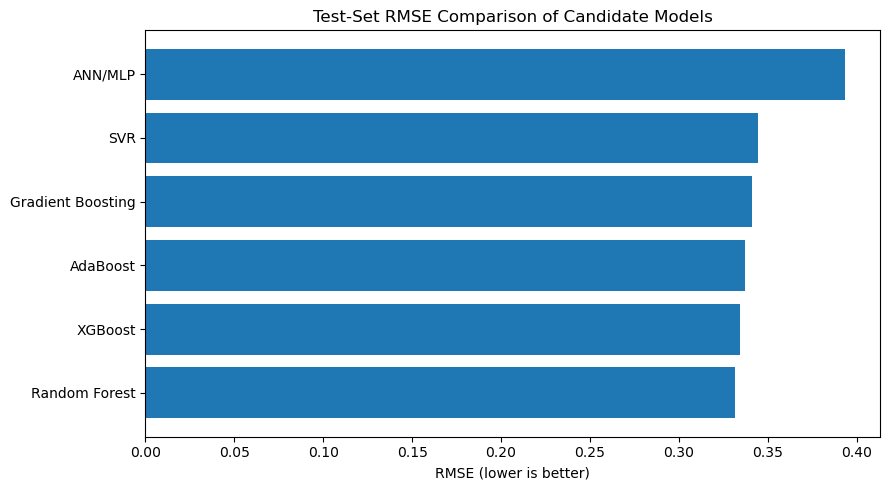

,Predictor,Importance
0,CRASH_TYPE_DESC,0.2829
1,FESTIVE_DAY,0.1260
2,DAY_OF_WEEK,0.1220
3,ACCIDENT_HOUR,0.1175
4,ROAD_CATEGORY,0.0970
5,DISTRICT,0.0855
6,FESTIVE_SEASON_YEAR,0.0854
7,TOTAL_VEHICLE_INVOLVED_CLEAN,0.0837


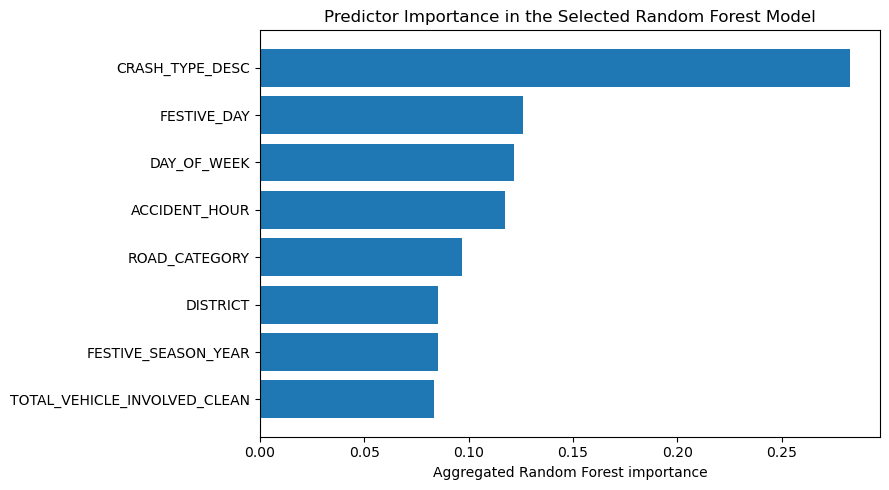

,ACCIDENT_HOUR,Crash_records,Total_fatalities,Mean_fatalities_per_crash
0,0,66,76.0,1.152
1,1,61,66.0,1.082
2,2,56,58.0,1.036
3,3,59,63.0,1.068
4,4,54,58.0,1.074
5,5,60,65.0,1.083
6,6,67,72.0,1.075
7,7,65,70.0,1.077
8,8,45,52.0,1.156
9,9,39,42.0,1.077


,CRASH_TYPE_DESC,Crash_records,Total_fatalities,Mean_fatalities_per_crash
0,Accident with pedestrian,578,590.0,1.021
1,Hit and Run,441,444.0,1.007
2,Single vehicle (overturned),192,226.0,1.177
3,Head on,118,164.0,1.390
4,Accident with fixed/other object,144,160.0,1.111
5,Head/rear end,109,121.0,1.110
6,Approach at angle (both trav. straight),46,53.0,1.152
7,Sideswipe (opposite directions),40,48.0,1.200
8,Unknown,22,27.0,1.227
9,Accident with Pedal Cyclist,26,26.0,1.000


,DISTRICT,Crash_records,Total_fatalities,Mean_fatalities_per_crash
0,City of Johannesburg,596,637.0,1.069
1,Ekurhuleni,450,476.0,1.058
2,City of Tshwane,404,452.0,1.119
3,Sedibeng,183,206.0,1.126
4,West Rand,149,161.0,1.081


DONE: comparison tables and charts saved.


In [239]:

# ============================================================
# DISSERTATION COMPARISON OUTPUTS — CHAPTER 4
# Run after the existing modelling and analysis cells.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. VERIFY MODEL METRICS FROM THE EXISTING TEST PREDICTIONS
# ------------------------------------------------------------
# Uses the predictions already generated in your notebook.

comparison_rows = []

for model_name, predictions in model_predictions.items():
    predictions = np.asarray(predictions).ravel()
    actual = np.asarray(y_test).ravel()

    valid = np.isfinite(actual) & np.isfinite(predictions)
    actual_valid = actual[valid]
    pred_valid = predictions[valid]

    nonzero = actual_valid != 0
    mape = (
        np.mean(np.abs(
            (actual_valid[nonzero] - pred_valid[nonzero])
            / actual_valid[nonzero]
        )) * 100
        if nonzero.any() else np.nan
    )

    comparison_rows.append({
        "Model": model_name,
        "Test observations": len(actual_valid),
        "RMSE": mean_squared_error(actual_valid, pred_valid) ** 0.5,
        "MAE": mean_absolute_error(actual_valid, pred_valid),
        "R2": r2_score(actual_valid, pred_valid),
        "MAPE_percent_nonzero_actuals": mape
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE")
display(model_comparison.round(4))
model_comparison.to_csv("verified_model_comparison.csv", index=False)

# Chart 1: RMSE across your candidate models
plot_data = model_comparison.sort_values("RMSE", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_data["Model"], plot_data["RMSE"])
plt.xlabel("RMSE (lower is better)")
plt.title("Test-Set RMSE Comparison of Candidate Models")
plt.tight_layout()
plt.savefig("chapter4_model_rmse_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. RANDOM FOREST PREDICTOR IMPORTANCE
# ------------------------------------------------------------
# Aggregate one-hot encoded feature importances to original variables.
# Use the fitted tuned RF if it exists; otherwise use rf_model.

final_rf = globals().get("tuned_rf_model", rf_model)
feature_names = preprocessor.get_feature_names_out()
importances = final_rf.feature_importances_

assert len(feature_names) == len(importances), (
    "Feature names and model importances do not match."
)

importance_df = pd.DataFrame({
    "Encoded_feature": feature_names,
    "Importance": importances
})

predictors = [
    "DISTRICT", "CRASH_TYPE_DESC", "ROAD_CATEGORY",
    "DAY_OF_WEEK", "FESTIVE_SEASON_YEAR",
    "TOTAL_VEHICLE_INVOLVED_CLEAN", "ACCIDENT_HOUR"
]

def original_predictor(feature):
    feature = feature.split("__", 1)[-1]
    for name in sorted(predictors, key=len, reverse=True):
        if feature == name or feature.startswith(name + "_"):
            return name
    return feature

importance_df["Predictor"] = importance_df["Encoded_feature"].apply(
    original_predictor
)

predictor_comparison = (
    importance_df.groupby("Predictor")["Importance"]
    .sum().sort_values(ascending=False)
    .reset_index()
)

display(predictor_comparison.round(4))
predictor_comparison.to_csv("verified_predictor_importance.csv", index=False)

plt.figure(figsize=(9, 5))
ordered = predictor_comparison.sort_values("Importance")
plt.barh(ordered["Predictor"], ordered["Importance"])
plt.xlabel("Aggregated Random Forest importance")
plt.title("Predictor Importance in the Selected Random Forest Model")
plt.tight_layout()
plt.savefig("chapter4_predictor_importance.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. FESTIVE-SEASON FINDINGS TO MATCH AGAINST LITERATURE
# ------------------------------------------------------------
# Summarise key descriptive patterns from the existing festive dataset.

festive = df_festive_complete.copy()

hour_summary = (
    festive.groupby("ACCIDENT_HOUR")
    .agg(
        Crash_records=("TOTAL_FATALITIES", "size"),
        Total_fatalities=("TOTAL_FATALITIES", "sum"),
        Mean_fatalities_per_crash=("TOTAL_FATALITIES", "mean")
    ).reset_index()
)

crash_type_summary = (
    festive.groupby("CRASH_TYPE_DESC", dropna=False)
    .agg(
        Crash_records=("TOTAL_FATALITIES", "size"),
        Total_fatalities=("TOTAL_FATALITIES", "sum"),
        Mean_fatalities_per_crash=("TOTAL_FATALITIES", "mean")
    ).sort_values("Total_fatalities", ascending=False)
    .reset_index()
)

district_summary = (
    festive.groupby("DISTRICT", dropna=False)
    .agg(
        Crash_records=("TOTAL_FATALITIES", "size"),
        Total_fatalities=("TOTAL_FATALITIES", "sum"),
        Mean_fatalities_per_crash=("TOTAL_FATALITIES", "mean")
    ).sort_values("Total_fatalities", ascending=False)
    .reset_index()
)

display(hour_summary.round(3))
display(crash_type_summary.head(10).round(3))
display(district_summary.round(3))

hour_summary.to_csv("comparison_festive_hour_findings.csv", index=False)
crash_type_summary.to_csv("comparison_festive_crash_type_findings.csv", index=False)
district_summary.to_csv("comparison_festive_district_findings.csv", index=False)

print("DONE: comparison tables and charts saved.")


In [240]:

# HELD-OUT TEST RESULTS — ALL SIX MODELS

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score
)

actual = np.asarray(y_test).ravel()
results = []

for name, prediction in model_predictions.items():
    prediction = np.asarray(prediction).ravel()

    if len(prediction) != len(actual):
        print(f"Skipped {name}: prediction/test lengths differ.")
        continue

    valid = np.isfinite(actual) & np.isfinite(prediction)
    y_true = actual[valid]
    y_pred = prediction[valid]

    # Conventional MAPE is undefined when actual values are zero.
    nonzero = y_true != 0
    mape = (
        np.mean(np.abs((y_true[nonzero] - y_pred[nonzero])
                       / y_true[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    results.append({
        "Model": name,
        "Test observations": len(y_true),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
        "MAPE (%)": mape
    })

heldout_results = pd.DataFrame(results).sort_values("RMSE")
display(heldout_results.round(4))
heldout_results.to_csv("heldout_test_results.csv", index=False)

print("These are held-out test results, not cross-validation results.")


,Model,Test observations,RMSE,MAE,R²,MAPE (%)
0,Random Forest,526,0.3313,0.1304,0.0824,9.7387
1,XGBoost,526,0.3347,0.1322,0.0637,9.8498
2,AdaBoost,526,0.3372,0.1554,0.0495,12.3390
3,Gradient Boosting,526,0.3413,0.1360,0.0264,10.2235
4,SVR,526,0.3448,0.1227,0.0065,8.6999
5,ANN/MLP,526,0.3935,0.2066,-0.2942,17.2909


These are held-out test results, not cross-validation results.


In [241]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Use the same seasons and predictors as the current modelling split
seasons = ["2018/19", "2019/20", "2020/21",
           "2021/22", "2022/23", "2023/24", "2024/25"]

categorical = [
    "DISTRICT", "CRASH_TYPE_DESC", "ROAD_CATEGORY",
    "DAY_OF_WEEK", "FESTIVE_SEASON_YEAR"
]
numerical = [
    "TOTAL_VEHICLE_INVOLVED_CLEAN", "ACCIDENT_HOUR"
]

results = []

for i in range(2, len(seasons)):
    train_seasons = seasons[:i]
    test_season = seasons[i]

    train = df_festive_complete[
        df_festive_complete["FESTIVE_SEASON_LABEL"].isin(train_seasons)
    ].copy()

    test = df_festive_complete[
        df_festive_complete["FESTIVE_SEASON_LABEL"] == test_season
    ].copy()

    predictors = categorical + numerical

    X_train = train[predictors]
    y_train = train["TOTAL_FATALITIES"]
    X_test = test[predictors]
    y_test = test["TOTAL_FATALITIES"]

    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numerical)
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    model = RandomForestRegressor(
        n_estimators=300, random_state=42, n_jobs=-1
    )
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)

    baseline = np.repeat(y_train.mean(), len(y_test))
    nonzero = y_test.to_numpy() != 0

    results.append({
        "Test season": test_season,
        "Training seasons": ", ".join(train_seasons),
        "Training crashes": len(train),
        "Test crashes": len(test),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
        "MAPE (%)": (
            np.mean(np.abs(
                (y_test.to_numpy()[nonzero] - predictions[nonzero])
                / y_test.to_numpy()[nonzero]
            )) * 100 if nonzero.any() else np.nan
        ),
        "Baseline RMSE": np.sqrt(
            mean_squared_error(y_test, baseline)
        )
    })

yearly_results = pd.DataFrame(results)
display(yearly_results.round(4))


,Test season,Training seasons,Training crashes,Test crashes,RMSE,MAE,R2,MAPE (%),Baseline RMSE
0,2020/21,"2018/19, 2019/20",489,220,0.3676,0.1670,-0.3199,12.8558,0.3204
1,2021/22,"2018/19, 2019/20, 2020/21",709,268,0.4078,0.1807,-0.1308,12.3465,0.3842
2,2022/23,"2018/19, 2019/20, 2020/21, 2021/22",977,279,0.2916,0.1079,0.1694,7.7603,0.3212
3,2023/24,"2018/19, 2019/20, 2020/21, 2021/22, 2022/23",1256,297,0.4209,0.1408,-0.1424,9.8335,0.3940
4,2024/25,"2018/19, 2019/20, 2020/21, 2021/22, 2022/23, 2...",1553,229,0.2728,0.0892,-0.0236,6.8941,0.2745
